# Trabajo Práctico Integrador - Introducción al Análisis de Datos

**Caso:** análisis y predicción de cancelaciones en reservas hoteleras.

> La empresa busca comprender qué factores influyen en la cancelación de reservas en hoteles urbanos y resort, analizando variables como fechas de estadía, tipo de cliente, canal de reserva, historial previo y tarifas, con el fin de identificar patrones y mejorar la gestión operativa.


## Desarrollado por

- **Integrantes:** `Matias Carro` y `Hugo Catalan`
- **Comisión:** 11
- **Dataset asignado:** Dataset K
- **Entrega:** Primer Entrega - Semana 3
- **Fecha:** 22/08/2026

## Importación de librerías

### Librerias a utilizar:

- **pandas:** para cargar el dataset y trabajar con datos en forma de tablas (DataFrames).
- **numpy:** para realizar operaciones numéricas y manejar arreglos de forma eficiente.



In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

print("Versión de Pandas:", pd.__version__)
print("Versión de NumPy:", np.__version__)
print("Versión de Matplotlib:", plt.matplotlib.__version__)
print("Versión de Seaborn:", sns.__version__)
print("Version de DuckDB: ", duckdb.__version__)


from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Librerías cargadas correctamente.")


Versión de Pandas: 3.0.5
Versión de NumPy: 2.5.2
Versión de Matplotlib: 3.11.1
Versión de Seaborn: 0.13.2
Version de DuckDB:  1.5.6
Librerías cargadas correctamente.


## 1. Presentacion del problema

El caso de estudio se centra en el análisis de reservas hoteleras con el objetivo de comprender qué factores están asociados a la cancelación de estadías. El dataset asignado contiene información detallada de cada reserva, incluyendo tipo de hotel, fechas de llegada, duración de la estadía, composición del grupo, país de origen, canal de reserva, tipo de cliente, historial previo, tarifa promedio por noche y características operativas como depósito, agente, pedidos especiales y cambios realizados.


### Relación entre datos, información y conocimiento
En este trabajo partimos de los **datos** que son valores crudos del sistema de reservas: fechas, cantidades, categorías y códigos.  
Mediante el análisis exploratorio estos datos se convierten en **información**, como distribuciones, patrones y diferencias entre reservas canceladas y no canceladas.  
A partir de esa información generamos el **conocimiento** que nos permite entender el comportamiento de los clientes y detectar factores que podrían influir en la cancelación de una reserva.  

Esta relación es clave para el caso: los datos del hotel por sí solos no dicen nada, pero al transformarlos en información y luego interpretarlos, podemos identificar variables relevantes (como `lead_time`, `deposit_type` o `customer_type`) que ayudan a explicar por qué algunas reservas se cancelan y otras no.

### Ciclo de vida del análisis
Este trabajo se enmarca en el ciclo de vida del análisis de datos, que incluye:
1. Obtención del dataset asignado.  
2. Comprensión inicial del problema (cancelaciones hoteleras).  
3. Exploración y limpieza mínima (EDA).  
4. Transformación y preparación de variables relevantes.  
5. Interpretación y comunicación de resultados.

### Variable objetivo
La **variable objetivo** del análisis es **`is_canceled`**, que indica si la reserva fue cancelada (`1`) o no (`0`).  
Su distribución será calculada y analizada en las próximas secciones para comprender el comportamiento general del conjunto de datos y orientar las preguntas del análisis.

### Preguntas iniciales que orientan el trabajo
- ¿Qué características diferencian a las reservas canceladas de las no canceladas?  
- ¿Influyen el tipo de hotel o el canal de reserva en la cancelación?  
- ¿Las reservas con mayor anticipación (`lead_time`) presentan mayor probabilidad de cancelación?  
- ¿Los clientes con pedidos especiales o estacionamiento tienden a cancelar menos?  
- ¿Las políticas de depósito (`deposit_type`) reducen la cancelación?  
- ¿Existen segmentos de mercado con mayor riesgo de cancelación?  

## 2. Dataset Asignado

- **Comisión:** 11
- **Dataset asignado:** Dataset K

## 3. Carga del dataset

Se carga el Dataset perteneciente a la comisión 11:


In [2]:
df = pd.read_csv("hotel booking TPI grupo K.csv")

print("Dataset cargado correctamente.")



Dataset cargado correctamente.


## 4. Vista Inicial

In [3]:
print("\nVista de los primeros datos: ")
df.head()


Vista de los primeros datos: 


,booking_id,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,arrival_date,stays_in_weekend_nights,...,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
0,HB-014269,Resort Hotel,0,17,2025,February,8,21,2025-02-21,0,...,E,0,No Deposit,NaN,292.0,0,Transient,58.00,1,1
1,HB-018087,Resort Hotel,0,6,2023,November,44,1,2023-11-01,2,...,D,3,No Deposit,240.0,NaN,0,Transient,58.00,0,2
2,HB-022870,Resort Hotel,0,45,2024,April,15,8,2024-04-08,0,...,D,1,No Deposit,240.0,NaN,0,Transient-Party,65.00,0,2
3,HB-048154,City Hotel,0,95,2024,March,11,17,2024-03-17,2,...,A,0,No Deposit,9.0,NaN,0,Transient,73.95,0,1
4,HB-060351,City Hotel,1,277,2024,November,45,7,2024-11-07,1,...,A,0,Non Refund,NaN,NaN,0,Transient,100.00,0,0


## 5. Estructura general:

Filas y Columnas:

In [4]:
filas, columnas = df.shape
print(f"El dataset tiene {filas} filas y {columnas} columnas.")

print("Columnas del dataset:")
print(df.columns.tolist())

print("\nTipos de datos:")
print(df.info())


El dataset tiene 25000 filas y 32 columnas.
Columnas del dataset:
['booking_id', 'hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'arrival_date', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Tipos de datos:
<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   booking_id                      25000 non-null  str    
 1   hotel                          

El dataset tiene 25.000 filas y 32 columnas.  
Las variables incluyen información temporal, categórica y numérica relevante para el análisis.


### Diccionario de variables 

| Variable | Traducción | Representación | Tipo de Datos |
|----------|------------|----------------|-----------|
| booking_id | ID de reserva | Identificador único de cada reserva. | str |
| hotel | Tipo de hotel | Indica si la reserva corresponde a City Hotel (Ciudad) o Resort Hotel (Resort). | str |
| is_canceled | Cancelada | Indica si la reserva fue cancelada (1) o no (0). | int64 |
| lead_time | Anticipación | Días entre la fecha de reserva y la fecha de llegada. | int64 |
| arrival_date_year | Año de llegada | Año en el que el huésped llega al hotel. | int64 |
| arrival_date_month | Mes de llegada | Mes en el que el huésped llega al hotel. | str |
| arrival_date_week_number | Semana de llegada | Número de semana del año en la que llega el huésped. | int64 |
| arrival_date_day_of_month | Día del mes de llegada | Día del mes en el que llega el huésped. | int64 |
| arrival_date | Fecha de llegada | Fecha completa de llegada (YYYY-MM-DD). | str |
| stays_in_weekend_nights | Noches de fin de semana | Cantidad de noches en fines de semana. | int64 |
| stays_in_week_nights | Noches de semana | Cantidad de noches de lunes a jueves. | int64 |
| adults | Adultos | Número de adultos en la reserva. | int64 |
| children | Niños | Número de niños en la reserva. | float64 |
| babies | Bebés | Número de bebés en la reserva. | int64 |
| meal | Tipo de comida | Plan de comidas asociado a la reserva (BB, HB, SC, etc.). | str |
| country | País | País de origen del huésped. | str |
| market_segment | Segmento de mercado | Tipo de cliente según el canal de adquisición. | str |
| distribution_channel | Canal de distribución | Canal por el cual se realizó la reserva. | str |
| is_repeated_guest | Huésped repetido | Indica si el cliente ya se alojó anteriormente. | int64 |
| previous_cancellations | Cancelaciones previas | Cantidad de reservas previas canceladas por el cliente. | int64 |
| previous_bookings_not_canceled | Reservas previas no canceladas | Cantidad de reservas previas completadas por el cliente. | int64 |
| reserved_room_type | Habitación reservada | Tipo de habitación solicitada originalmente. | str |
| assigned_room_type | Habitación asignada | Tipo de habitación finalmente asignada. | str |
| booking_changes | Cambios en la reserva | Número de modificaciones realizadas a la reserva. | int64 |
| deposit_type | Tipo de depósito | Política de depósito aplicada. | str |
| agent | Agente | Código del agente que gestionó la reserva. | float64 |
| company | Compañía | Código de la empresa asociada a la reserva. | float64 |
| days_in_waiting_list | Días en lista de espera | Tiempo que la reserva permaneció en espera antes de confirmarse. | int64 |
| customer_type | Tipo de cliente | Clasificación del cliente (Transient, Contract, Group, etc.). | str |
| adr | Tarifa promedio diaria | Precio promedio por noche de la reserva. | float64 |
| required_car_parking_spaces | Estacionamiento requerido | Cantidad de espacios de estacionamiento solicitados. | int64 |
| total_of_special_requests | Pedidos especiales | Número de solicitudes especiales realizadas por el cliente. | int64 |



## 6. Tipos de variables 

Clasificacion de las variables por su tipo de datos

In [5]:
numericas = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cadenas = df.select_dtypes(include=['str']).columns.tolist()

print("Cantidad de variables numéricas:", len(numericas))
print("Cantidad de variables de texto / fecha:", len(cadenas))



Cantidad de variables numéricas: 20
Cantidad de variables de texto / fecha: 12


### Clasificación inicial de las variables

| Variable | Tipo | Representación |
|----------|------|----------------|
| booking_id | Categórica (ID) | Identificador único de reserva. |
| hotel | Categórica | Tipo de hotel. |
| is_canceled | Numérica (booleana) | Indica si la reserva fue cancelada. |
| lead_time | Numérica | Días de anticipación de la reserva. |
| arrival_date_year | Numérica | Año de llegada. |
| arrival_date_month | Categórica | Mes de llegada. |
| arrival_date_week_number | Numérica | Semana del año. |
| arrival_date_day_of_month | Numérica | Día del mes. |
| arrival_date | Temporal | Fecha completa de llegada. |
| stays_in_weekend_nights | Numérica | Noches de fin de semana. |
| stays_in_week_nights | Numérica | Noches de semana. |
| adults | Numérica | Cantidad de adultos. |
| children | Numérica | Cantidad de niños. |
| babies | Numérica | Cantidad de bebés. |
| meal | Categórica | Tipo de comida. |
| country | Categórica | País de origen. |
| market_segment | Categórica | Segmento de mercado. |
| distribution_channel | Categórica | Canal de distribución. |
| is_repeated_guest | Numérica (booleana) | Indica si el huésped ya se alojó antes. |
| previous_cancellations | Numérica | Cancelaciones previas. |
| previous_bookings_not_canceled | Numérica | Reservas previas no canceladas. |
| reserved_room_type | Categórica | Habitación reservada. |
| assigned_room_type | Categórica | Habitación asignada. |
| booking_changes | Numérica | Cambios realizados a la reserva. |
| deposit_type | Categórica | Política de depósito. |
| agent | Categórica (ID) | Código del agente. |
| company | Categórica (ID) | Código de la compañía. |
| days_in_waiting_list | Numérica | Días en lista de espera. |
| customer_type | Categórica | Tipo de cliente. |
| adr | Numérica | Tarifa promedio diaria. |
| required_car_parking_spaces | Numérica | Espacios de estacionamiento solicitados. |
| total_of_special_requests | Numérica | Cantidad de pedidos especiales. |

---


### Resumen descriptivo

Estadisticas iniciales de cada variable

In [6]:
print("Resumen descriptivo:")
df.describe().round(2)

Resumen descriptivo:


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,25000.00,25000.00,25000.00,25000.00,25000.00,25000.00,25000.00,25000.00,25000.00,25000.00,25000.00,25000.00,25000.00,25000.00,21511.00,1426.00,25000.00,25000.00,25000.00,25000.00
mean,0.37,103.29,2024.16,26.51,15.83,0.92,2.48,1.85,0.10,0.01,0.03,0.08,0.13,0.22,86.05,189.79,2.40,101.86,0.06,0.57
std,0.48,106.59,0.71,13.40,8.81,0.99,1.88,0.58,0.39,0.12,0.18,0.79,1.43,0.63,110.38,132.42,17.56,48.03,0.24,0.80
min,0.00,0.00,2023.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,9.00,0.00,-6.38,0.00,0.00
25%,0.00,18.00,2024.00,16.00,8.00,0.00,1.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,9.00,62.00,0.00,69.50,0.00,0.00
50%,0.00,68.00,2024.00,27.00,16.00,1.00,2.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,14.00,174.00,0.00,95.00,0.00,0.00
75%,1.00,159.00,2025.00,37.00,24.00,2.00,3.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,229.00,277.00,0.00,126.00,0.00,1.00
max,1.00,629.00,2025.00,52.00,31.00,14.00,34.00,50.00,3.00,10.00,1.00,26.00,66.00,14.00,531.00,539.00,391.00,510.00,3.00,5.00


## 7. Caracterización descriptiva inicial:
Vista inicial de todas las variables 

### 1. booking_id


In [7]:

print("Conteos:")
print(df["booking_id"].describe())
ids_unicos = df["booking_id"].nunique()
faltantes = df["booking_id"].isnull().sum()

print("\n Descripción:")

print(f"\nCantidad de faltantes: {faltantes}")
print (f"\nSe trata de {ids_unicos} IDs unicas")

Conteos:
count         25000
unique        25000
top       HB-014269
freq              1
Name: booking_id, dtype: object

 Descripción:

Cantidad de faltantes: 0

Se trata de 25000 IDs unicas


**Descripción:**  
Es un identificador único, no aporta información estadística. Se usa solo para referencia.

**Cantidad y Faltantes:** 
Se cuenta con 25000 IDs unicas, sin ninguna faltante

---

### 2. hotel

In [8]:

print(df["hotel"].shape)

conteo_total = df["hotel"].count()

faltantes = df["hotel"].isnull().sum()
porcentaje_faltantes = (faltantes / len(df)) * 100

distintos = df["hotel"].nunique()

conteo = df["hotel"].value_counts()
porcentaje = df["hotel"].value_counts(normalize=True) * 100

print("Datos totales:", conteo_total)
print("Faltantes:", faltantes)
print("Porcentaje de faltantes:", porcentaje_faltantes, "%")

print("Cantidad de valores distintos:", distintos)

print("\nDistribución:")
print(conteo)

print("\nPorcentaje:")
print(porcentaje)



(25000,)
Datos totales: 25000
Faltantes: 0
Porcentaje de faltantes: 0.0 %
Cantidad de valores distintos: 2

Distribución:
hotel
City Hotel      16716
Resort Hotel     8284
Name: count, dtype: int64

Porcentaje:
hotel
City Hotel      66.864
Resort Hotel    33.136
Name: proportion, dtype: float64


**Descripción:**  
La variable `hotel` indica el tipo de establecimiento donde se realizó la reserva. Es útil para comparar comportamientos entre City Hotel y Resort Hotel, ya que cada uno puede tener patrones diferentes de demanda, estacionalidad y cancelaciones.

**Faltantes:**  
0 (0%)

**Valores distintos:**  
Se tratan de 2 valores distintos

**Distribución y porcentajes:**  
- City Hotel: 16716 (67%)
- Resort Hotel: 8284 (33%)

**Observación:**  
La mayoría de las reservas corresponden al City Hotel. 

---

### 3. is_canceled

In [9]:
conteo_total = df["is_canceled"].count()

faltantes = df["is_canceled"].isnull().sum()
porcentaje_faltantes = (faltantes / len(df)) * 100

distintos = df["is_canceled"].nunique()

conteo = df["is_canceled"].value_counts()
porcentaje = df["is_canceled"].value_counts(normalize=True) * 100

print("Datos totales:", conteo_total)
print("Faltantes:", faltantes)
print("Porcentaje de faltantes:", porcentaje_faltantes, "%")

print("Cantidad de valores distintos:", distintos)

print("\nDistribución:")
print(conteo)

print("\nPorcentaje:")
print(porcentaje)




Datos totales: 25000
Faltantes: 0
Porcentaje de faltantes: 0.0 %
Cantidad de valores distintos: 2

Distribución:
is_canceled
0    15729
1     9271
Name: count, dtype: int64

Porcentaje:
is_canceled
0    62.916
1    37.084
Name: proportion, dtype: float64



**Descripción:**  
La variable `is_canceled` indica si la reserva fue cancelada (`1`) o no (`0`). Es una variable clave porque representa el resultado final del proceso de reserva y suele ser la variable objetivo en modelos de predicción de cancelaciones.

**Faltantes:**  
0 (0%)

**Valores distintos:**  
Son 2 valores distintos. 
- `0`: reserva no cancelada  
- `1`: reserva cancelada  

**Distribución:**  
- No canceladas: 15729 (62.91%) 
- Canceladas: 9271 (37.08%)

**Observación:**  
Es la variable principal a observar y analizar.

El dataset presenta una proporción considerable de cancelaciones. Esta distribución es importante para evaluar y llegar a una conclusion del motivo tan alto de las cancelaciones.

---

### 4. lead_time

In [10]:
conteo_total = df["lead_time"].count()
faltantes = df["lead_time"].isnull().sum()
porcentaje_faltantes = (faltantes / len(df)) * 100
distintos = df["lead_time"].nunique()

print("\nDatos totales:", conteo_total)
print(f"Faltantes: {faltantes}")
print(f"Porcentaje de faltantes: {porcentaje_faltantes}%")
print(f"Cantidad de valores distintos: {distintos}")


print("\nEstadisticas:")
print(df["lead_time"].describe())


print(f"\nMinimo y Maximo:\nMin: {df['lead_time'].min()}  |  Max: {df['lead_time'].max()}")







Datos totales: 25000
Faltantes: 0
Porcentaje de faltantes: 0.0%
Cantidad de valores distintos: 460

Estadisticas:
count    25000.000000
mean       103.285280
std        106.585179
min          0.000000
25%         18.000000
50%         68.000000
75%        159.000000
max        629.000000
Name: lead_time, dtype: float64

Minimo y Maximo:
Min: 0  |  Max: 629



**Descripción:**  
La variable `lead_time` representa la cantidad de días entre la fecha de reserva y la fecha de llegada (anticipacion). 

**Faltantes:**  
0 faltantes, se encuentra completo.

Se trata de 460 valores diferentes. De un total de 25000 datos, sin ningun faltante.

**Outliers:** La media es 103 días, pero la mediana es 68, esto nos dice que la distribución está sesgada por valores extremos altos.

**Dispersión:** La desviación estándar es 106 días, bastante elevada, lo que confirma gran variabilidad.

**Rango:** Va de 0 (reservas hechas el mismo día) hasta 629 días (más de un año y medio de anticipación).

Con los **cuartiles** sabemos que:

  - 25% de las reservas se hacen con menos de 18 días de anticipación.

  - 50% con menos de 68 días.

  - 75% con menos de 159 días.

Muestra una anticipación muy variable: aunque la mayoría de las reservas se hacen dentro de los primeros 2 meses, existen valores extremos que llegan hasta 629 días y generan una distribución muy dispersa

---


### 5. arrival_date_year


In [11]:
conteo_total = df["arrival_date_year"].count()

print("\nEstadisticas:")
print(df["arrival_date_year"].describe())

print("\nDatos y Cantidades:")
print(df["arrival_date_year"].value_counts())

print("\nPorcentajes:")
print(df["arrival_date_year"].value_counts(normalize=True))


Estadisticas:
count    25000.000000
mean      2024.158880
std          0.706072
min       2023.000000
25%       2024.000000
50%       2024.000000
75%       2025.000000
max       2025.000000
Name: arrival_date_year, dtype: float64

Datos y Cantidades:
arrival_date_year
2024    11906
2025     8533
2023     4561
Name: count, dtype: int64

Porcentajes:
arrival_date_year
2024    0.47624
2025    0.34132
2023    0.18244
Name: proportion, dtype: float64


**Descripcion:**
La variable `arrival_date_year` representa el año de llegada del huésped al hotel. 

**Faltantes:**
Está completa (0 faltantes) 

Contiene solo tres valores distintos: **2023**, **2024** y **2025**.

- El año 2024 concentra casi la mitad de las reservas (47,6 %), siendo el período con mas huespedes  del dataset.
- El año 2025 aporta un 34,1 %, mostrando continuidad hacia el futuro.
- El año 2023 tiene el 18,2 %, con menor peso porque es el inicio del registro.

Se deberia analizar el motivo por el cual en el 2024 hubo mayor cantidad de huespedes y esta bajo durante el 2025.

---

### 6. arrival_date_month 

In [12]:
print(f"Estadisticas basicas: ")
print(df["arrival_date_month"].describe())

print("\nCantidad por mes:")
print(df["arrival_date_month"].value_counts())

print("\nPorcentajes por mes:")
print(df["arrival_date_month"].value_counts(normalize=True).round(2))

print(f"\n Meses de los que tenemos datos: ")
print(df["arrival_date_month"].unique())


Estadisticas basicas: 
count      25000
unique        12
top       August
freq        2861
Name: arrival_date_month, dtype: object

Cantidad por mes:
arrival_date_month
August       2861
July         2691
May          2448
April        2379
October      2356
June         2321
September    2165
March        2020
February     1723
December     1389
November     1370
January      1277
Name: count, dtype: int64

Porcentajes por mes:
arrival_date_month
August       0.11
July         0.11
May          0.10
April        0.10
October      0.09
June         0.09
September    0.09
March        0.08
February     0.07
December     0.06
November     0.05
January      0.05
Name: proportion, dtype: float64

 Meses de los que tenemos datos: 
<StringArray>
[ 'February',  'November',     'April',     'March',    'August',       'May',
      'July', 'September',  'December',   'October',   'January',      'June']
Length: 12, dtype: str


**Descripción:**

La variable `arrival_date_month` representa el mes de llegada del huésped al hotel.
Faltantes:

**Faltantes:**
Está completa (0 faltantes).

Contiene 12 valores distintos, correspondientes a todos los meses del año.

- Los meses con mayor cantidad de huéspedes son Agosto (11%), Julio (11%) y Mayo (10%), mostrando la temporada alta.

- Meses como Enero (5%), Noviembre (5%) y Diciembre (6%) tienen un menor volumen de reservas.

Se debería analizar si esta distribucion de las reservas se relaciona directamente con estacionalidad o hay otros factores claves que influyan.

---

### 7. arrival_date_week_number

In [13]:

conteo_total = df["arrival_date_week_number"].count()
print("Conteo total:", conteo_total)

print("\nCantidad de valores distintos:")
print(f"{df["arrival_date_week_number"].nunique()} Semanas en el año")

print("\n Informacion:")
print(df["arrival_date_week_number"].info())

print("\nEstadísticas:")
print(df["arrival_date_week_number"].describe())

print("\nDatos y Cantidades:")
print(df["arrival_date_week_number"].value_counts().sort_index())

print("\nPorcentajes:")
print(df["arrival_date_week_number"].value_counts(normalize=True).round(4))




Conteo total: 25000

Cantidad de valores distintos:
52 Semanas en el año

 Informacion:
<class 'pandas.Series'>
RangeIndex: 25000 entries, 0 to 24999
Series name: arrival_date_week_number
Non-Null Count  Dtype
--------------  -----
25000 non-null  int64
dtypes: int64(1)
memory usage: 195.4 KB
None

Estadísticas:
count    25000.00000
mean        26.50996
std         13.39698
min          1.00000
25%         16.00000
50%         27.00000
75%         37.00000
max         52.00000
Name: arrival_date_week_number, dtype: float64

Datos y Cantidades:
arrival_date_week_number
1     343
2     200
3     323
4     338
5     300
6     323
7     462
8     436
9     549
10    385
11    454
12    511
13    439
14    485
15    538
16    552
17    594
18    598
19    516
20    591
21    609
22    513
23    581
24    550
25    522
26    550
27    578
28    614
29    634
30    612
31    594
32    703
33    735
34    589
35    578
36    471
37    527
38    562
39    471
40    571
41    565
42    533
43   

**Descripción:**

La variable `arrival_date_week_number` representa la semana del año en la que el huésped llega al hotel, con valores que van del 1 al 52.
Faltantes:

**Faltantes:**
Está completa (0 faltantes).

Contiene 52 valores distintos, cubriendo todas las semanas del año.

- La distribución es relativamente uniforme, con una media de 26.5 y una mediana de 27, lo que indica que las llegadas se concentran hacia la mitad del año.

- Las semanas con mayor cantidad de huéspedes se ubican entre la 27 y la 33, donde se observan los picos más altos (hasta 2.032 reservas).

- Las semanas iniciales y finales del año muestran menor actividad, especialmente la semana 1 y la semana 52, que presentan los valores más bajos del conjunto.

Se puede asumir que los picos en semanas centrales están asociados a vacaciones o temporadas turísticas específicas que incrementan la demanda.

---

### 8. arrival_date_day_of_month 

In [14]:
print(f"Conteo total: {df['arrival_date_day_of_month'].count()}")

print(f"\nCantidad de valores distintos: {df['arrival_date_day_of_month'].nunique()}")

print(f"\nNulos: {df['arrival_date_day_of_month'].isnull().sum()}")

print(f"\nEstadísticas:\n{df['arrival_date_day_of_month'].describe()}")

print(f"\nDatos y Cantidades:\n{df['arrival_date_day_of_month'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['arrival_date_day_of_month'].value_counts(normalize=True).round(4)}")





Conteo total: 25000

Cantidad de valores distintos: 31

Nulos: 0

Estadísticas:
count    25000.000000
mean        15.830240
std          8.806273
min          1.000000
25%          8.000000
50%         16.000000
75%         24.000000
max         31.000000
Name: arrival_date_day_of_month, dtype: float64

Datos y Cantidades:
arrival_date_day_of_month
1     784
2     881
3     792
4     802
5     927
6     740
7     747
8     749
9     879
10    767
11    741
12    845
13    788
14    785
15    877
16    857
17    945
18    877
19    825
20    806
21    808
22    762
23    752
24    860
25    885
26    838
27    810
28    796
29    747
30    859
31    469
Name: count, dtype: int64

Porcentajes:
arrival_date_day_of_month
17    0.0378
5     0.0371
25    0.0354
2     0.0352
9     0.0352
18    0.0351
15    0.0351
24    0.0344
30    0.0344
16    0.0343
12    0.0338
26    0.0335
19    0.0330
27    0.0324
21    0.0323
20    0.0322
4     0.0321
28    0.0318
3     0.0317
13    0.0315
14    0.0314


**Descripción**

La variable `arrival_date_day_of_month` representa el día del mes en el que el huésped llega al hotel, con valores entre 1 y 31.

**Faltantes**

Está completa (0 nulos).

Contiene 31 valores diferentes, cubriendo todos los días posibles del mes.

Los estadísticos muestran una distribución equilibrada, lo que nos marca que las llegadas de los huespedes son estables y no hay concentraciones en dias particulares. 

**Frecuencias por día**

- El dia con mayor cantidad de huéspedes es el día 17 con 945

- El día con menor cantidad de huéspedes es el día 31 con 469

- Los días más frecuentes rondan entre 3.5% y 3.7% del total.

- El día 31 tiene el porcentaje más bajo (1.88%).


Las llegadas se concentran en días centrales del mes, mientras que los extremos muestran menor actividad. Esto muestra un patrón estable de reservas que se centran en la mitad del mes.

---

### 9. arrival_date

In [15]:
print(f"Conteo total: {df['arrival_date'].count()}")

print(f"Cantidad de valores distintos: {df['arrival_date'].nunique()}")

print(f"Nulos: {df['arrival_date'].isnull().sum()}")


#valor mas frecuente y porcentaje

valor_mas_frecuente = df['arrival_date'].mode()[0]
frecuencia = df['arrival_date'].value_counts()[valor_mas_frecuente]
porcentaje = frecuencia / df['arrival_date'].count() * 100

print(f"\nValor más frecuente: {valor_mas_frecuente}")
print(f"Frecuencia: {frecuencia}")
print(f"Porcentaje del valor mas frecuente: {porcentaje:.2f}%")



Conteo total: 25000
Cantidad de valores distintos: 793
Nulos: 0

Valor más frecuente: 2023-12-05
Frecuencia: 88
Porcentaje del valor mas frecuente: 0.35%


**Descripción**

La variable `arrival_date` representa la fecha completa de llegada del huésped al hotel.

**Faltantes**

Está completa (0 nulos).

**Valores**

Contiene 793 valores diferentes, lo que muestra una alta variabilidad en las fechas registradas.

- Valor más frecuente: 2023‑12‑05

- Frecuencia: 88

- Porcentaje: 0.35%

Las fechas de llegada están muy dispersas y no se concentran en días específicos. El valor más frecuente representa solo el 0.35% del total, lo que muestra mucha variabilidad sin ningun pico.

---

### 10. stays_in_weekend_nights

In [16]:
print(f"Conteo total: {df['stays_in_weekend_nights'].count()}")
print(f"Cantidad de valores distintos: {df['stays_in_weekend_nights'].nunique()}")
print(f"Nulos: {df['stays_in_weekend_nights'].isnull().sum()}")

print(f"\nEstadísticas:\n{df['stays_in_weekend_nights'].describe()}")

print(f"\nDatos y Cantidades:\n{df['stays_in_weekend_nights'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['stays_in_weekend_nights'].value_counts(normalize=True).round(4)}")

print(f"\nMinimo y Maximo:\nMin: {df['stays_in_weekend_nights'].min()}  |  Max: {df['stays_in_weekend_nights'].max()}")


Conteo total: 25000
Cantidad de valores distintos: 12
Nulos: 0

Estadísticas:
count    25000.000000
mean         0.916640
std          0.991227
min          0.000000
25%          0.000000
50%          1.000000
75%          2.000000
max         14.000000
Name: stays_in_weekend_nights, dtype: float64

Datos y Cantidades:
stays_in_weekend_nights
0     10983
1      6486
2      6817
3       248
4       388
5        19
6        37
7         4
8        13
9         3
10        1
14        1
Name: count, dtype: int64

Porcentajes:
stays_in_weekend_nights
0     0.4393
2     0.2727
1     0.2594
4     0.0155
3     0.0099
6     0.0015
5     0.0008
8     0.0005
7     0.0002
9     0.0001
14    0.0000
10    0.0000
Name: proportion, dtype: float64

Minimo y Maximo:
Min: 0  |  Max: 14


**Descripción**

La variable `stays_in_weekend_nights` indica cuántas noches de fin de semana (viernes y sábado) permaneció el huésped en el hotel. Los valores observados van desde 0 hasta 14.

**Faltantes**
Está completa (0 nulos).

Contiene 12 valores diferentes, lo que muestra que la mayoría de los huéspedes tienen pocas noches de fin de semana registradas.

Los estadísticos muestran una distribución fuertemente concentrada en valores bajos, mostrando que los huéspedes no pasan noches de fin de semana en el hotel.

**Frecuencias por valor**

- El valor más frecuente es 0 noches, con 10.983 huéspedes.

- Los valores 1 y 2 noches también son comunes, con 6.486 y 6.817 respectivamente.

- A partir de 3 noches, las frecuencias caen.

**Porcentajes** 

- 0 noches representa el 43.93% del total.

- 2 noches: 27.27%

- 1 noche: 25.94%

- El resto de los valores tienen porcentajes menores al 2%, mostrando que estancias largas de fin de semana son muy poco frecuentes.

La mayoría de los huéspedes no se alojan durante fines de semana, y quienes lo hacen suelen quedarse solo 1 o 2 noches. Esto sugiere que el hotel recibe principalmente reservas de corta duración y con poca actividad en fines de semana.

---

### 11. stays_in_week_nights

In [17]:
print(f"Conteo total: {df['stays_in_week_nights'].count()}")
print(f"Cantidad de valores distintos: {df['stays_in_week_nights'].nunique()}")
print(f"Nulos: {df['stays_in_week_nights'].isnull().sum()}")

print(f"\nEstadísticas:\n{df['stays_in_week_nights'].describe()}")

print(f"\nDatos y Cantidades:\n{df['stays_in_week_nights'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['stays_in_week_nights'].value_counts(normalize=True).round(4)}")

print(f"\nMinimo y Maximo:\nMin: {df['stays_in_week_nights'].min()}  |  Max: {df['stays_in_week_nights'].max()}")


Conteo total: 25000
Cantidad de valores distintos: 25
Nulos: 0

Estadísticas:
count    25000.000000
mean         2.479680
std          1.878629
min          0.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         34.000000
Name: stays_in_week_nights, dtype: float64

Datos y Cantidades:
stays_in_week_nights
0     1584
1     6368
2     7246
3     4587
4     1978
5     2262
6      313
7      192
8      121
9       44
10     214
11      17
12       9
13       3
14       5
15      22
16       7
17       1
18       1
19      11
20       4
21       5
22       3
24       2
34       1
Name: count, dtype: int64

Porcentajes:
stays_in_week_nights
2     0.2898
1     0.2547
3     0.1835
5     0.0905
4     0.0791
0     0.0634
6     0.0125
10    0.0086
7     0.0077
8     0.0048
9     0.0018
15    0.0009
11    0.0007
19    0.0004
12    0.0004
16    0.0003
21    0.0002
14    0.0002
20    0.0002
13    0.0001
22    0.0001
24    0.0001
18    0.0000
34    0.0000
17    0.0000


**Descripción**

La variable `stays_in_week_nights` representa la cantidad de noches de días de semana (lunes a jueves) que el  huésped permaneció en el hotel. Los valores observados van desde 0 hasta 34.

**Faltantes**

Está completa (0 nulos).

Contiene 25 valores diferentes, lo que muestra una mayor variabilidad respecto a las noches de fin de semana.

Los estadísticos muestran una distribución concentrada en valores bajos, mostrando estancias cortas durante días de semana.

**Frecuencias por valor**

- Los valores más frecuentes son 2 noches (28.98%), 1 noche (25.47%) y 3 noches (18.35%).

- A partir de 4 noches, las frecuencias disminuyen

- Los valores altos (17, 18, 24, 34) aparecen en cantidades mínimas, entre 1 y 2 registros.

**Porcentajes**

- Más del 70% de los huéspedes se alojan entre 1 y 3 noches.

- Las estadias de 4 a 6 noches representan porcentajes moderados.

- Las estadias largas (más de 10 noches) son extremadamente raras, con porcentajes cercanos a 0%.

La distribución muestra que los huéspedes suelen tener estadias cortas durante días de semana, con muy pocos casos de estadías prolongadas. 

---

### 12. Adults

In [18]:
print(f"Conteo total: {df['adults'].count()}")
print(f"Cantidad de valores distintos: {df['adults'].nunique()}")
print(f"Nulos: {df['adults'].isnull().sum()}")

print(f"\nEstadísticas:\n{df['adults'].describe()}")

print(f"\nDatos y Cantidades:\n{df['adults'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['adults'].value_counts(normalize=True).round(4)}")

print(f"\nMinimo y Maximo:\nMin: {df['adults'].min()}  |  Max: {df['adults'].max()}")


Conteo total: 25000
Cantidad de valores distintos: 7
Nulos: 0

Estadísticas:
count    25000.000000
mean         1.853840
std          0.577313
min          0.000000
25%          2.000000
50%          2.000000
75%          2.000000
max         50.000000
Name: adults, dtype: float64

Datos y Cantidades:
adults
0        80
1      4875
2     18727
3      1302
4        14
5         1
50        1
Name: count, dtype: int64

Porcentajes:
adults
2     0.7491
1     0.1950
3     0.0521
0     0.0032
4     0.0006
50    0.0000
5     0.0000
Name: proportion, dtype: float64

Minimo y Maximo:
Min: 0  |  Max: 50


**Descripción**

La variable adults representa la cantidad de adultos incluidos en cada reserva. Los valores observados van desde 0 hasta 50, aunque la distribución muestra que casi todas las reservas contienen entre 1 y 3 adultos.

**Faltantes**

Está completa (0 nulos).

Contiene 7 valores diferentes, lo que indica una variabilidad muy baja en la cantidad de adultos por reserva.

Los estadísticos muestran una distribución fuertemente concentrada en valores bajos, donde la mayoria son reservas para 1 o 2 adultos.

**Frecuencias**

- 2 adultos es el valor más frecuente, con 18.727 registros (74.91%).

- 1 adulto aparece en 4.875 reservas (19.50%).

- 3 adultos representa 1.302 casos (5.21%).

- El valor máximo observado (50 adultos) es un outlier muy extremo.

**Porcentajes** 

- Más del 94% de las reservas tienen entre 1 y 2 adultos.

- Los valores superiores a 3 adultos representan porcentajes prácticamente nulos.

- La distribución presenta una asimetría extrema, con valores atípicos que no reflejan el comportamiento típico del dataset. (El outlier de 50 siendo un solo caso extremo)


La variable muestra que las reservas casi siempre incluyen 1 o 2 adultos, con muy pocos casos de grupos grandes. Los valores extremos (como 50 adultos) son outliers que no representan el patrón habitual de las reservas.

---

### 13. Children

In [19]:
print(f"Conteo total: {df['children'].count()}")
print(f"Cantidad de valores distintos: {df['children'].nunique()}")
print(f"Nulos: {df['children'].isnull().sum()}")

print(f"\nEstadísticas:\n{df['children'].describe()}")

print(f"\nDatos y Cantidades:\n{df['children'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['children'].value_counts(normalize=True).round(4)}")

print(f"\nMinimo y Maximo:\nMin: {df['children'].min()}  |  Max: {df['children'].max()}")


Conteo total: 25000
Cantidad de valores distintos: 4
Nulos: 0

Estadísticas:
count    25000.000000
mean         0.101200
std          0.391005
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          3.000000
Name: children, dtype: float64

Datos y Cantidades:
children
0.0    23227
1.0     1033
2.0      723
3.0       17
Name: count, dtype: int64

Porcentajes:
children
0.0    0.9291
1.0    0.0413
2.0    0.0289
3.0    0.0007
Name: proportion, dtype: float64

Minimo y Maximo:
Min: 0.0  |  Max: 3.0


**Descripción**

La variable `children` representa la cantidad de niños incluidos en cada reserva. Los valores observados van desde 0 hasta 3, mostrando que la mayoría de las reservas no incluyen menores.

**Faltantes**

Está completa (0 nulos).

Contiene 4 valores diferentes, lo que indica una variabilidad muy baja en la cantidad de niños por reserva.

Los estadísticos muestran una distribución extremadamente concentrada en el valor 0, con muy pocos casos de reservas que incluyen niños.
Frecuencias por valor

- 0 niños es el valor dominante, con 23.227 registros.

- 1 niño aparece en 1.033 reservas.

- 2 niños aparece en 723 casos.

- 3 niños es muy raro, con solo 17 registros.

La distribución está fuertemente sesgada hacia reservas sin niños.

**Porcentajes** 

- 0 niños representa más del 92% del total.

- Los valores 1 y 2 niños representan porcentajes bajos, entre 3% y 4%.

- El valor 3 niños es prácticamente nulo en el dataset.

La mediana, el 25%, 50% y 75% percentil son todos 0, lo que confirma que la presencia de niños es poco frecuente.


La mayoría de las reservas no incluyen niños, y los casos con más de un menor son muy poco comunes. Esto sugiere que el hotel recibe principalmente huéspedes adultos o familias pequeñas con uno o dos niños como máximo.

---

### 14. Babies

In [20]:
print(f"Conteo total: {df['babies'].count()}")
print(f"Cantidad de valores distintos: {df['babies'].nunique()}")
print(f"Nulos: {df['babies'].isnull().sum()}")

print(f"\nEstadísticas:\n{df['babies'].describe()}")

print(f"\nDatos y Cantidades:\n{df['babies'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['babies'].value_counts(normalize=True).round(4)}")

print(f"\nMinimo y Maximo:\nMin: {df['babies'].min()}  |  Max: {df['babies'].max()}")


Conteo total: 25000
Cantidad de valores distintos: 5
Nulos: 0

Estadísticas:
count    25000.000000
mean         0.007560
std          0.118926
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         10.000000
Name: babies, dtype: float64

Datos y Cantidades:
babies
0     24830
1       166
2         2
9         1
10        1
Name: count, dtype: int64

Porcentajes:
babies
0     0.9932
1     0.0066
2     0.0001
10    0.0000
9     0.0000
Name: proportion, dtype: float64

Minimo y Maximo:
Min: 0  |  Max: 10


**Descripción**

La variable `babies` representa la cantidad de bebés incluidos en cada reserva. Los valores observados van desde 0 hasta 10, aunque la distribución muestra que prácticamente todas las reservas no incluyen bebés.

**Faltantes**

Está completa (0 nulos).

Contiene 5 valores diferentes, lo que muestra una variabilidad muy baja en la presencia de bebés dentro de las reservas.

Los estadísticos muestran una distribución concentrada en el valor 0, con valores máximos que corresponden a casos extremos atipicos.

**Frecuencias** 

- 0 bebés es el valor dominante, con 24.830 registros.

- 1 bebé aparece en 166 reservas.

- 2 bebés aparece en 2 casos.

- Los valores 9 y 10 bebés aparecen 1 vez cada uno, siendo outliers extremos.

La distribución está fuertemente sesgada hacia reservas sin bebés.

**Porcentajes** 

- 0 bebés representa el 99.32% del total.

- 1 bebé representa el 0.66%.

- El resto de los valores tienen porcentajes prácticamente nulos.

Los percentiles 25%, 50% y 75% son todos 0, confirmando que la presencia de bebés es excepcional.

La gran mayoría de las reservas no incluyen bebés, y los casos con más de uno son extremadamente raros. Esto sugiere que el hotel recibe principalmente huéspedes adultos o familias sin bebés, con muy pocos registros de grupos que viajen con menores de muy corta edad.

---

### 15. Meal

In [21]:
print(f"Conteo total: {df['meal'].count()}")
print(f"Cantidad de valores distintos: {df['meal'].nunique()}")
print(f"Nulos: {df['meal'].isnull().sum()}")

print(f"\nEstadísticas:")
print(f"Valor más frecuente: {df['meal'].mode()[0]}")
print(f"Frecuencia: {df['meal'].value_counts()[df['meal'].mode()[0]]}")

print(f"\nDatos y Cantidades:\n{df['meal'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['meal'].value_counts(normalize=True).round(4)}")


Conteo total: 25000
Cantidad de valores distintos: 5
Nulos: 0

Estadísticas:
Valor más frecuente: BB
Frecuencia: 19288

Datos y Cantidades:
meal
BB           19288
FB             147
HB            3073
SC            2264
Undefined      228
Name: count, dtype: int64

Porcentajes:
meal
BB           0.7715
HB           0.1229
SC           0.0906
Undefined    0.0091
FB           0.0059
Name: proportion, dtype: float64


**Descripción**

La variable `meal` indica el tipo de comidas asociado a cada reserva. Los valores corresponden a categorías estándar utilizadas en hoteles:

- BB - Bed & Breakfast (Alojamiento y Desayuno)

- HB - Half Board (Desayuno y Cena - Media pension)

- SC - Self Catering (Cocina incluida, el huesped puede prepar sus comidas)

- FB - Full Board (Desayuno, almuerzo y cena - Pension completa)

- Undefined - categoría no especificada

**Faltantes**

Está completa (0 nulos). Pero se tiene 228 valores como undefined.

Contiene 5 valores diferentes, lo que muestra una oferta tipica de servicios en un hotel (Siendo 4 lo tipico, sin contar los undefined)


La distribución está fuertemente concentrada en un único valor, lo que indica una preferencia  por parte de los huéspedes.

**Frecuencias** 

- BB es el valor dominante, con 19.288 registros.

**Porcentajes** 

- BB representa el 77.15% del total.

La categoría BB domina ampliamente, mientras que las demás tienen una presencia mucho menor.

La mayoría de los huéspedes elige el régimen Bed & Breakfast, lo que sugiere que el hotel funciona principalmente con clientes que prefieren desayunar en el establecimiento y resolver el resto de las comidas por su cuenta. Los regímenes más completos (HB, FB) son minoritarios. 

---

### 16. Country

In [22]:
print(df['country'].describe())

print(f"\nNulos: {df['country'].isnull().sum()}")
print(f"Cantidad de valores distintos: {df['country'].nunique()}")

print(f"\nDatos y Cantidades:\n{df['country'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['country'].value_counts(normalize=True).round(4)}")


count     24899
unique      129
top         PRT
freq      10278
Name: country, dtype: object

Nulos: 101
Cantidad de valores distintos: 129

Datos y Cantidades:
country
ABW     1
AGO    88
ALB     3
AND     2
ARE     6
       ..
VEN     9
VGB     1
VNM     2
ZAF    15
ZWE     1
Name: count, Length: 129, dtype: int64

Porcentajes:
country
PRT    0.4128
GBR    0.0989
FRA    0.0875
ESP    0.0714
DEU    0.0610
        ...  
SLE    0.0000
BEN    0.0000
GLP    0.0000
SYC    0.0000
TZA    0.0000
Name: proportion, Length: 129, dtype: float64


**Descripción**

La variable `country` identifica el país de origen del huésped. Es una variable categórica con alta diversidad,con 129 países distintos, lo que muestra una clientela internacional.

**Faltantes**
Presenta 101 valores faltantes, menos del 1%, por lo que la variable está prácticamente completa.

**Frecuencias** 

El país más frecuente es PRT, con una frecuencia muy superior al resto.

- PRT (Portugal) es el valor que mas aparece con 10.278 registros.

**Porcentajes**

- PRT (Portugal) representa el 41.28% del total.

- GBR (Reino Unido) esta en el 9.89% de las reservas.

- FRA (Francia) 8.75%.

- ESP (España) 7.14%.

- DEU (Alemania) 6.10%.

- Más del 40% de los registros se distribuyen entre países con porcentajes menores al 1% cada uno.

La mayoría de los huéspedes provienen de Portugal, seguido por Reino Unido, Francia, España y Alemania.
Aunque aparecen 129 países, la mayoría aporta muy pocos registros, lo que muestra la presencia de huespedes internacionales pero la mayoria siendo de un grupo pequeño de paises

---

### 17. Market Segment

In [23]:
print(df['market_segment'].describe())

print(f"\nNulos: {df['market_segment'].isnull().sum()}")
print(f"Cantidad de valores distintos: {df['market_segment'].nunique()}")

print(f"\nDatos y Cantidades:\n{df['market_segment'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['market_segment'].value_counts(normalize=True).round(4)}")

count         25000
unique            7
top       Online TA
freq          11867
Name: market_segment, dtype: object

Nulos: 0
Cantidad de valores distintos: 7

Datos y Cantidades:
market_segment
Aviation            47
Complementary      148
Corporate         1114
Direct            2650
Groups            4163
Offline TA/TO     5011
Online TA        11867
Name: count, dtype: int64

Porcentajes:
market_segment
Online TA        0.4747
Offline TA/TO    0.2004
Groups           0.1665
Direct           0.1060
Corporate        0.0446
Complementary    0.0059
Aviation         0.0019
Name: proportion, dtype: float64


**Descripción**

La variable `market_segment` indica el canal por el cual llega la reserva. 

**Datos**

- **Online TA:** *Online Travel Agency* — Agencia de viajes online.
- **Offline TA/TO:** *Travel Agency / Tour Operator* — Agencias y operadores turísticos no digitales.
- **Groups:** *Grupos organizados* — Excursiones, delegaciones, eventos, equipos deportivos.
- **Direct:** *Reserva directa* — Página web del hotel, teléfono, mostrador o email.
- **Corporate:** *Corporativo* — Empresas con acuerdos comerciales o empleados viajando por trabajo.
- **Complementary:** *Cortesía* — Reservas sin costo: invitados especiales, personal, compensaciones.
- **Aviation:** *Aerolíneas* — Tripulaciones, pasajeros varados en escalas, convenios con compañías aéreas.

**Faltantes**

No tiene valores faltantes y cuenta con 7 categorías distintas.

La mas repetida es Online TA con 11867 registros.


**Distribución** 

- Online TA: 11867 (47.47%)

- Offline TA/TO: 5011 (20.04%)

- Groups: 4163 (16.65%)

- Direct: 2650 (10.60%)

- Corporate: 1114 (4.46%)

- Complementary: 148 (0.59%)

- Aviation: 47 (0.19%)

El valor más frecuente es Online TA, con 11.867 reservas.

La mayoría de las reservas provienen de agencias online, mostrando una fuerte dependencia de canales digitales. Los segmentos offline, grupos y directos también aportan volumen relevante.

---

### 18. distribution channel 

In [24]:
print(df['distribution_channel'].describe())

print(f"\nNulos: {df['distribution_channel'].isnull().sum()}")
print(f"Cantidad de valores distintos: {df['distribution_channel'].nunique()}")

print(f"\nDatos y Cantidades:\n{df['distribution_channel'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['distribution_channel'].value_counts(normalize=True).round(4)}")


count     25000
unique        4
top       TA/TO
freq      20488
Name: distribution_channel, dtype: object

Nulos: 0
Cantidad de valores distintos: 4

Datos y Cantidades:
distribution_channel
Corporate     1409
Direct        3063
GDS             40
TA/TO        20488
Name: count, dtype: int64

Porcentajes:
distribution_channel
TA/TO        0.8195
Direct       0.1225
Corporate    0.0564
GDS          0.0016
Name: proportion, dtype: float64


**Descripción**

La variable `distribution_channel`  indica el canal por el cual se distribuye la reserva. 



**Faltantes**
No presenta valores faltantes y contiene 4 categorías, lo que muestra un esquema de distribución simple.

- Travel Agent (Agencia de Viajes) / Tour Operator (Operador Turístico)
- Direct (web del hotel / teléfono)
- Corporate (acuerdos corporativos)
- GDS (sistemas globales de distribución)

**Distribución y porcentajes** 

- TA/TO: 20488 (81.95%)

- Direct: 3063 (12.25%)

- Corporate: 1409 (5.64%)

- GDS: 40 (0.16%)

El valor más frecuente es TA/TO, con 20.488 registros.

La gran mayoría de las reservas se gestionan a través de agencias y operadores turísticos, lo que muestra una fuerte dependencia de intermediarios para captar clientes. Los canales directos y corporativos aportan una proporción menor pero no inexistente, mostrando que el hotel también tiene sus ventas directas y acuerdos empresariales. 

---

### 19. Is repeated guest

In [25]:
print(df['is_repeated_guest'].describe())

print(f"\nNulos: {df['is_repeated_guest'].isnull().sum()}")
print(f"Cantidad de valores distintos: {df['is_repeated_guest'].nunique()}")

print(f"\nDatos y Cantidades:\n{df['is_repeated_guest'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['is_repeated_guest'].value_counts(normalize=True).round(4)}")


count    25000.000000
mean         0.032600
std          0.177591
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: is_repeated_guest, dtype: float64

Nulos: 0
Cantidad de valores distintos: 2

Datos y Cantidades:
is_repeated_guest
0    24185
1      815
Name: count, dtype: int64

Porcentajes:
is_repeated_guest
0    0.9674
1    0.0326
Name: proportion, dtype: float64


**Descripción**

La `is_repeated_guest`variable indica si el huésped es recurrente (1) o nuevo (0). 

**Faltantes**

No presenta valores faltantes y contiene únicamente 2 categorías, funcionando como un booleano.

**Distribución** 

- 0 (no repetido): 24.185 registros (96.74%)

- 1 (repetido): 815 registros (3.26%)

Los estadísticos muestran que la mayoría de los valores son 0, con percentiles 25%, 50% y 75% todos en 0, lo que confirma una distribución concentrada en huéspedes nuevos.


El hotel recibe principalmente huéspedes nuevos, lo que sugiere una tasa baja de repetición. 

---

### 20. Previous Cancellations

In [26]:
print(df['previous_cancellations'].describe())

print(f"\nNulos: {df['previous_cancellations'].isnull().sum()}")
print(f"Cantidad de valores distintos: {df['previous_cancellations'].nunique()}")

print(f"\nDatos y Cantidades:\n{df['previous_cancellations'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['previous_cancellations'].value_counts(normalize=True).round(4)}")

print(f"\nMinimo y Maximo:\nMin: {df['previous_cancellations'].min()}  |  Max: {df['previous_cancellations'].max()}")


count    25000.000000
mean         0.084080
std          0.791148
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         26.000000
Name: previous_cancellations, dtype: float64

Nulos: 0
Cantidad de valores distintos: 14

Datos y Cantidades:
previous_cancellations
0     23633
1      1283
2        21
3        14
4         8
5         2
6         4
11        8
13        3
14        2
19        5
24        9
25        5
26        3
Name: count, dtype: int64

Porcentajes:
previous_cancellations
0     0.9453
1     0.0513
2     0.0008
3     0.0006
24    0.0004
4     0.0003
11    0.0003
25    0.0002
19    0.0002
6     0.0002
13    0.0001
26    0.0001
5     0.0001
14    0.0001
Name: proportion, dtype: float64

Minimo y Maximo:
Min: 0  |  Max: 26


**Descripción**

La variable `previous_cancellations` indica cuántas reservas anteriores fueron canceladas por el mismo huésped antes de la actual. 

**Faltantes**

No presenta valores faltantes 

**Estadisticas**

Contiene 14 valores distintos, con un rango que va desde 0 hasta 26. 
Los estadísticos muestran que los percentiles 25%, 50% y 75% son todos 0, lo que muestra una distribución concentrada en ese valor.

**Distribución y porcentajes** 

- 0 cancelaciones previas: 23.633 registros (94.53%)

- 1 cancelación previa: 1.283 registros (5.13%)

- Valores mayores a 1 : proporciones menores al 1%, con frecuencias muy bajas 

- Casos extremos: valores como 24, 25 y 26 aparecen, pero representan proporciones menores al 0.04%. (Outliers)


La enorme concentración en 0 cancelaciones previas indica que la mayoría de los huéspedes no tiene historial de cancelaciones, lo que se entiende tendiendo en cuenta que la gran mayoria de los clientes son clientes nuevos. Los valores altos (hasta 26) son casos excepcionales.

---


### 21. Previous bookings not canceled

In [27]:
print(df['previous_bookings_not_canceled'].describe())

print(f"\nNulos: {df['previous_bookings_not_canceled'].isnull().sum()}")
print(f"Cantidad de valores distintos: {df['previous_bookings_not_canceled'].nunique()}")

print(f"\nDatos y Cantidades:\n{df['previous_bookings_not_canceled'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['previous_bookings_not_canceled'].value_counts(normalize=True).round(4)}")

print(f"\nMinimo y Maximo:\nMin: {df['previous_bookings_not_canceled'].min()}  |  Max: {df['previous_bookings_not_canceled'].max()}")


count    25000.000000
mean         0.133840
std          1.425766
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         66.000000
Name: previous_bookings_not_canceled, dtype: float64

Nulos: 0
Cantidad de valores distintos: 38

Datos y Cantidades:
previous_bookings_not_canceled
0     24207
1       344
2       130
3        80
4        54
5        41
6        18
7        15
8        12
9        13
10       12
11       12
12        5
13        9
14        5
15        5
16        4
17        2
18        2
19        2
20        2
21        2
22        2
23        1
24        2
25        4
26        1
27        4
31        1
37        1
38        1
40        1
44        1
45        1
54        1
58        1
65        1
66        1
Name: count, dtype: int64

Porcentajes:
previous_bookings_not_canceled
0     0.9683
1     0.0138
2     0.0052
3     0.0032
4     0.0022
5     0.0016
6     0.0007
7     0.0006
9     0.0005
10    0.0005
11    0.0005
8    

**Descripción**

La variable `previous_bookings_not_canceled` indica cuántas reservas anteriores no canceladas realizó el huésped antes de la actual. 

**Faltantes**

No tiene valores faltantes 

**Estadisticas**

Contiene 38 valores distintos, con un rango que va desde 0 hasta 66.

Los percentiles 25%, 50% y 75% son 0, lo que dice que la distribución está concentrada en huéspedes sin historial previo de reservas.
Distribución principal

**Distribución y porcentajes**

- 0 reservas previas no canceladas: 24.207 registros (96.83%)

- 1 reserva previa: 344 registros (1.38%)

- 2 a 5 reservas previas: proporciones entre 0.16% y 0.52%

- Valores mayores a 10: extremadamente raros (menos de 0.05%)

- Casos extremos: aparecen valores como 54, 58, 65 y 66, cada uno con solo 1 registro.


La enorme concentración en 0 reservas previas no canceladas indica que la mayoría de los huéspedes no tiene historial de reservas exitosas anteriores, lo que corresponde con la informacion que se tiene de que la mayoria de los clientes son nuevos.
Los valores altos (más de 20 reservas previas) son casos excepcionales y pueden corresponder a clientes muy frecuentes.

---


### 22. Reserved room type

In [28]:

print(df['reserved_room_type'].describe())

print(f"\nNulos: {df['reserved_room_type'].isnull().sum()}")
print(f"Cantidad de valores distintos: {df['reserved_room_type'].nunique()}")

print(f"\nDatos y Cantidades:\n{df['reserved_room_type'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['reserved_room_type'].value_counts(normalize=True).round(4)}")


count     25000
unique       10
top           A
freq      18112
Name: reserved_room_type, dtype: object

Nulos: 0
Cantidad de valores distintos: 10

Datos y Cantidades:
reserved_room_type
A    18112
B      209
C      187
D     3963
E     1357
F      610
G      439
H      120
L        1
P        2
Name: count, dtype: int64

Porcentajes:
reserved_room_type
A    0.7245
D    0.1585
E    0.0543
F    0.0244
G    0.0176
B    0.0084
C    0.0075
H    0.0048
P    0.0001
L    0.0000
Name: proportion, dtype: float64


**Descripción**

La variable `reserved_room_type` es una varaible categórica que indica el tipo de habitación reservada por los huespedes.

**Faltantes**

No tiene faltantes

**Estadisticas**

Cuenta con 10 categorías, no se cuenta con mas informacion acerca del tipo de habitacion o costo. Simplemente el tipo.

**Distribucion y porcentajes**

- A: 18112 (72.45%)

- D: 3963 (15.85%)

- E: 1357 (5.43%)

- F: 610 (2.44%)

- G: 439 (1.76%)

La categoría A domina y representa la habitación estándar o más demandada. 

---

### 23. Assigned room type

In [29]:
print(df['assigned_room_type'].describe())

print(f"\nNulos: {df['assigned_room_type'].isnull().sum()}")
print(f"Cantidad de valores distintos: {df['assigned_room_type'].nunique()}")

print(f"\nDatos y Cantidades:\n{df['assigned_room_type'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['assigned_room_type'].value_counts(normalize=True).round(4)}")


count     25000
unique       11
top           A
freq      15641
Name: assigned_room_type, dtype: object

Nulos: 0
Cantidad de valores distintos: 11

Datos y Cantidades:
assigned_room_type
A    15641
B      436
C      488
D     5248
E     1606
F      796
G      527
H      135
I       65
K       56
P        2
Name: count, dtype: int64

Porcentajes:
assigned_room_type
A    0.6256
D    0.2099
E    0.0642
F    0.0318
G    0.0211
C    0.0195
B    0.0174
H    0.0054
I    0.0026
K    0.0022
P    0.0001
Name: proportion, dtype: float64


**Descripción**

La variable `assigned_room_type` indica el tipo de habitación finalmente asignada al huésped.

**Faltantes**
 No presenta valores faltantes.
 
Contiene 11 categorías, lo que muestra una oferta grande en tipo de habitaciones.
El valor más frecuente es A, lo que confirma que es la habitación estándar o más disponible en el hotel.

**Distribución y porcentajes**

- A: 15.641 registros (62.56%)

- D: 5.248 registros (20.99%)

- E: 1.606 registros (6.42%)

- F: 796 registros (3.18%)

- G: 527 registros (2.11%)

- El resto de las categorías tienen proporciones menores al 2%

La distribución está concentrada en A y D, que juntas representan más del 83% de las asignaciones. Lo que coincide con el tipo de habitacion reservada.

La categoría A domina la asignación, lo que sugiere que es la habitación más abundante o la opción por defecto del hotel.
Las categorías con baja frecuencia (como I, K y P) probablemente corresponden a habitaciones especiales, con disponibilidad limitada o asignadas solo en casos puntuales.

---

### 24. booking changes

In [30]:
print(df['booking_changes'].describe())

print(f"\nNulos: {df['booking_changes'].isnull().sum()}")
print(f"Cantidad de valores distintos: {df['booking_changes'].nunique()}")

print(f"\nDatos y Cantidades:\n{df['booking_changes'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['booking_changes'].value_counts(normalize=True).round(4)}")

print(f"\nMinimo y Maximo:\nMin: {df['booking_changes'].min()}  |  Max: {df['booking_changes'].max()}")



count    25000.000000
mean         0.222040
std          0.633431
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         14.000000
Name: booking_changes, dtype: float64

Nulos: 0
Cantidad de valores distintos: 13

Datos y Cantidades:
booking_changes
0     21194
1      2647
2       813
3       225
4        69
5        22
6        15
7         7
8         4
9         1
10        1
13        1
14        1
Name: count, dtype: int64

Porcentajes:
booking_changes
0     0.8478
1     0.1059
2     0.0325
3     0.0090
4     0.0028
5     0.0009
6     0.0006
7     0.0003
8     0.0002
9     0.0000
13    0.0000
10    0.0000
14    0.0000
Name: proportion, dtype: float64

Minimo y Maximo:
Min: 0  |  Max: 14


**Descripción**

La variable `booking_changes` es una varible numérica que indica cuántas veces se modificó la reserva antes de su llegada (cambios de fechas, habitación, etc.)

**Faltantes**
No presenta valores faltantes


Contiene 13 valores distintos, con un rango entre 0 y 14.
Los percentiles 25%, 50% y 75% son 0, lo que confirma que la mayoría de las reservas no tuvo cambios.

**Distribución**

- 0 cambios: mayoría absoluta (21194 registros, un  84.78%) 

- 1 cambio: 2647 (10.59%)

- 2 a 4 cambios: muy bajos (Un 4.43% entre todos)

- 5 o mas cambios: extremadamente raros (Un 0.20% restante)

- Máximo observado: 14 cambios (Outlier extremo)

La distribución está fuertemente concentrada en 0, lo que indica que la gran mayoría de las reservas se mantuvo sin modificaciones.

El hecho de que más del 80% de las reservas no tenga cambios sugiere que los huéspedes suelen mantener su reserva original sin modificaciones.

Esta variable es útil pporque un número alto de cambios puede relacionarse con mayor probabilidad de cancelación.

---

### 25. Deposit type

In [31]:
print(df['deposit_type'].describe())

print(f"\nNulos: {df['deposit_type'].isnull().sum()}")
print(f"Cantidad de valores distintos: {df['deposit_type'].nunique()}")

print(f"\nDatos y Cantidades:\n{df['deposit_type'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['deposit_type'].value_counts(normalize=True).round(4)}")


count          25000
unique             3
top       No Deposit
freq           21836
Name: deposit_type, dtype: object

Nulos: 0
Cantidad de valores distintos: 3

Datos y Cantidades:
deposit_type
No Deposit    21836
Non Refund     3134
Refundable       30
Name: count, dtype: int64

Porcentajes:
deposit_type
No Deposit    0.8734
Non Refund    0.1254
Refundable    0.0012
Name: proportion, dtype: float64


**Descripción**

`deposit_type` es una variable categórica que indica el tipo de depósito asociado a la reserva.

Tiene 3 categorías: No Deposit (Sin deposito), Non Refund (No reembolsable), Refundable (Reembolsable).

**Faltantes**

No tiene faltantes 

**Distribución y porcentaje**

- No Deposit: 21836 (87%)

- Non Refund: 3134 (13%)

- Refundable:30 (menos del 1%)

La distribución está fuertemente concentrada en No Deposit, lo que indica que la mayoría de las reservas no requieren pago anticipado.

La predominancia de No Deposit sugiere que el hotel opera principalmente con reservas sin compromiso previo, podria tratarse de una de las causas de la tasa tan altas de cancelaciones

---


### 26. Agent

In [32]:
print(df['agent'].describe())

print(f"\nNulos: {df['agent'].isnull().sum()}")
print(f"Cantidad de valores distintos: {df['agent'].nunique()}")

print(f"\nDatos y Cantidades:\n{df['agent'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['agent'].value_counts(normalize=True).round(4)}")


count    21511.000000
mean        86.049835
std        110.384758
min          1.000000
25%          9.000000
50%         14.000000
75%        229.000000
max        531.000000
Name: agent, dtype: float64

Nulos: 3489
Cantidad de valores distintos: 268

Datos y Cantidades:
agent
1.0      1508
2.0        27
3.0       284
4.0         9
5.0        81
         ... 
502.0       5
509.0       1
526.0       4
527.0       6
531.0       9
Name: count, Length: 268, dtype: int64

Porcentajes:
agent
9.0      0.3110
240.0    0.1346
1.0      0.0701
7.0      0.0361
14.0     0.0351
          ...  
244.0    0.0000
291.0    0.0000
429.0    0.0000
258.0    0.0000
141.0    0.0000
Name: proportion, Length: 268, dtype: float64


**Descripción**

`agent` es una variable numérica que identifica el ID del agente o agencia de viajes que gestionó la reserva.

**Faltantes**

Tiene 3489 valores nulos (14%), lo cual puede indicar reservas hechas sin agente (directas).

**Estadisticas**

Tiene 268 valores distintos, cuenta con una alta diversidad de agencias.

Los estadísticos muestran una distribución muy dispersa:

- Mínimo: 1

- Máximo: 531

- Mediana: 14

- Percentil 75: 229 

- Esto indica que hay muchos agentes con pocos registros y unos pocos con volúmenes muy altos.

**Distribución y porcentajes**

Los agentes más frecuentes son:

- 9: 31.10%

- 240: 13.46%

- 1: 7.01%

- 7: 3.61%

- 14: 3.51%

El resto de los agentes tiene proporciones muy bajas, muchos con menos de 0.1%.

La variable agent muestra que una parte importante de las reservas se realiza sin intermediarios (14% nulos), mientras que el resto se distribuye entre muchos agentes distintos, aunque unos pocos concentran la mayoría de las operaciones.

---

### 27. Company

In [33]:
print(df['company'].describe())

print(f"\nNulos: {df['company'].isnull().sum()}")
print(f"Cantidad de valores distintos: {df['company'].nunique()}")

print(f"\nDatos y Cantidades:\n{df['company'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['company'].value_counts(normalize=True).round(4)}")


count    1426.000000
mean      189.791725
std       132.421976
min         9.000000
25%        62.000000
50%       174.000000
75%       277.000000
max       539.000000
Name: company, dtype: float64

Nulos: 23574
Cantidad de valores distintos: 218

Datos y Cantidades:
company
9.0      8
11.0     1
12.0     5
14.0     1
18.0     1
        ..
521.0    1
523.0    7
525.0    4
528.0    2
539.0    1
Name: count, Length: 218, dtype: int64

Porcentajes:
company
40.0     0.1424
223.0    0.1087
67.0     0.0372
45.0     0.0358
153.0    0.0288
          ...  
253.0    0.0007
260.0    0.0007
358.0    0.0007
160.0    0.0007
384.0    0.0007
Name: proportion, Length: 218, dtype: float64


**Descripción**

`company`es una variable que identifica la empresa asociada a la reserva.

**Faltantes**

Tiene 94% de valores nulos, lo que indica que casi todas las reservas no provienen de compañías sino de clientes individuales o agencias.

**Distribución**

Los valores no nulos son pocos (solo 1.426 registros) y están muy dispersos entre 218 empresas distintas, la mayoría con menos de 10 reservas.

Los IDs más frecuentes:

- 40: 14.24%

- 223: 10.87%

- 67: 3.72%

- 45: 3.58%

- 153: 2.88%

Las reservas corporativas son muy poco comunes en este dataset.
El hotel opera casi exclusivamente con clientes individuales, y las pocas empresas que aparecen lo hacen con volúmenes pequeños.

---

### 28. Days in waiting list.

In [34]:
print(df['days_in_waiting_list'].describe())

print(f"\nNulos: {df['days_in_waiting_list'].isnull().sum()}")
print(f"Cantidad de valores distintos: {df['days_in_waiting_list'].nunique()}")

print(f"\nDatos y Cantidades:\n{df['days_in_waiting_list'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['days_in_waiting_list'].value_counts(normalize=True).round(4)}")

print(f"\nMinimo y Maximo:\nMin: {df['days_in_waiting_list'].min()}  |  Max: {df['days_in_waiting_list'].max()}")

count    25000.000000
mean         2.400440
std         17.555068
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        391.000000
Name: days_in_waiting_list, dtype: float64

Nulos: 0
Cantidad de valores distintos: 100

Datos y Cantidades:
days_in_waiting_list
0      24174
1          4
2          1
3         13
4          5
       ...  
236        6
259        2
330        5
379        3
391        8
Name: count, Length: 100, dtype: int64

Porcentajes:
days_in_waiting_list
0      0.9670
39     0.0020
58     0.0016
31     0.0014
44     0.0011
        ...  
74     0.0000
100    0.0000
53     0.0000
13     0.0000
97     0.0000
Name: proportion, Length: 100, dtype: float64

Minimo y Maximo:
Min: 0  |  Max: 391


**Descripción**

La variavble `days_in_waiting_list` es numérica, indica cuántos días estuvo una reserva en lista de espera antes de ser confirmada.

**Faltantes**

No tiene valores faltantes.

**Estadistica**

Contiene 100 valores distintos, con un rango entre 0 y 391 días.

**Distribución y porcentajes**

La variable esta completa en su mayoria por el valor 0, con 24.174 registros (96.7%).
El resto de los valores aparecen en proporciones mínimas, muchos con apenas 1 a 8 registros.
Los valores altos (desde 200 hasta 391) son casos extremadamente raros.

Percentiles:

- 25%: 0

- 50%: 0

- 75%: 0

Esto confirma que la gran mayoría de las reservas nunca estuvo en lista de espera.

El hotel casi no utiliza lista de espera: solo un 3.3% de las reservas pasó por este proceso, y en la mayoría de esos casos fueron esperas muy cortas. Los valores altos representan situaciones excepcionales, probablemente relacionadas con reservas especiales.

---


### 29. Customer type

In [35]:
print(df['customer_type'].describe())

print(f"\nNulos: {df['customer_type'].isnull().sum()}")
print(f"Cantidad de valores distintos: {df['customer_type'].nunique()}")

print(f"\nDatos y Cantidades:\n{df['customer_type'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['customer_type'].value_counts(normalize=True).round(4)}")


count         25000
unique            4
top       Transient
freq          18788
Name: customer_type, dtype: object

Nulos: 0
Cantidad de valores distintos: 4

Datos y Cantidades:
customer_type
Contract             867
Group                118
Transient          18788
Transient-Party     5227
Name: count, dtype: int64

Porcentajes:
customer_type
Transient          0.7515
Transient-Party    0.2091
Contract           0.0347
Group              0.0047
Name: proportion, dtype: float64


**Descripción**

`customer_type` clasifica el tipo de cliente según el patrón de reserva. 

**Faltantes**

No tiene valores faltantes

**Categorias**

Se trata de 4 categorías definidas: Transient, Transient-Party, Contract y Group.

La categoría dominante es Transient, que representa clientes individuales que reservan sin formar parte de un grupo ni contrato.
La segunda categoría, Transient-Party, corresponde a clientes que viajan en pequeños grupos informales.
Las reservas Contract son minoritarias y suelen estar asociadas a convenios empresariales.
La categoría Group son clientes que forman parte de un grupo organizado.

**Distribución y porcentajes**

- Transient: 18788 (75.15%)

- Transient-Party: 5227 (20.91%)

- Contract : 867 (3.47%)

- Group: 118 (0.47%)

El hotel trabaja principalmente con clientes individuales, seguido por pequeños grupos informales. Las reservas corporativas y los grupos organizados son minimos. Esto sugiere una operación centrada en turismo general y viajeros independientes, con poca presencia de contratos empresariales o grandes grupos.

---

### 30. adr

In [36]:
print(df['adr'].describe())

print(f"\nNulos: {df['adr'].isnull().sum()}")
print(f"Cantidad de valores distintos: {df['adr'].nunique()}")

print(f"\nDatos y Cantidades:\n{df['adr'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['adr'].value_counts(normalize=True).round(4)}")

print(f"\nMinimo y Maximo:\nMin: {df['adr'].min()}  |  Max: {df['adr'].max()}")


count    25000.000000
mean       101.858566
std         48.030925
min         -6.380000
25%         69.500000
50%         95.000000
75%        126.000000
max        510.000000
Name: adr, dtype: float64

Nulos: 0
Cantidad de valores distintos: 3862

Datos y Cantidades:
adr
-6.38        1
 0.00      405
 0.50        1
 1.00        3
 1.29        1
          ... 
 382.00      1
 388.00      1
 392.00      1
 450.00      1
 510.00      1
Name: count, Length: 3862, dtype: int64

Porcentajes:
adr
62.00     0.0318
75.00     0.0228
65.00     0.0215
90.00     0.0205
0.00      0.0162
           ...  
48.57     0.0000
71.72     0.0000
43.33     0.0000
57.40     0.0000
169.75    0.0000
Name: proportion, Length: 3862, dtype: float64

Minimo y Maximo:
Min: -6.38  |  Max: 510.0


**Descripción** 

`adr` (Average Daily Rate) representa la tarifa diaria promedio pagada por el huésped.

**Faltantes**
No tiene valores faltantes 

**Distribución**
Tiene una variabilidad muy alta, con 3862 valores distintos sobre 25.000 registros.

- Media: 101.86

- Mediana: 95

- Rango intercuartílico: 69.5 a 126

- Mínimo: −6.38

- Máximo: 510

La distribución está concentrada entre 70 y 130, que es el rango típico de tarifas.
Los valores cercanos a 0 suelen ser reservas sin cargo o ajustes contables.

**Outliers**

Hay dos tipos claros de outliers:

*Outliers negativos*

- 6.38: aparece solo 1 vez.

Este valor es inválido para una tarifa y puede representar error de carga o una reversión de un cobro. Se debe verificar el motivo de este valor. 

*Outliers positivos*

- Valores muy altos desde 300 hasta 510 aparecen en cantidades mínimas (1 registro cada uno).

Estos representan suites premium, tarifas corporativas especiales o posibles errores de carga. Tambien se deberia verificar el motivo de estos valores altos y que corresponden. 


La variable adr muestra que el hotel trabaja con tarifas promedio alrededor de 100 USD (asumiendo que la tarifa es en dolares) por noche, con una distribución estable y concentrada.
Los outliers negativos y los valores extremadamente altos deben revisarse porque pueden distorsionar los análisis.

---

### 31. Required car parking spaces

In [37]:
print(df['required_car_parking_spaces'].describe())

print(f"\nNulos: {df['required_car_parking_spaces'].isnull().sum()}")
print(f"Cantidad de valores distintos: {df['required_car_parking_spaces'].nunique()}")

print(f"\nDatos y Cantidades:\n{df['required_car_parking_spaces'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['required_car_parking_spaces'].value_counts(normalize=True).round(4)}")

print(f"\nMinimo y Maximo:\nMin: {df['required_car_parking_spaces'].min()}  |  Max: {df['required_car_parking_spaces'].max()}")


count    25000.000000
mean         0.060600
std          0.240437
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          3.000000
Name: required_car_parking_spaces, dtype: float64

Nulos: 0
Cantidad de valores distintos: 4

Datos y Cantidades:
required_car_parking_spaces
0    23495
1     1496
2        8
3        1
Name: count, dtype: int64

Porcentajes:
required_car_parking_spaces
0    0.9398
1    0.0598
2    0.0003
3    0.0000
Name: proportion, dtype: float64

Minimo y Maximo:
Min: 0  |  Max: 3


**Descripción**

`required_car_parking_spaces` es una variable que indica cuántos espacios de estacionamiento solicitó el huésped al momento de la reserva.

**Faltantes**

No tiene valores faltantes 

Presenta solo 4 valores posibles: 0, 1, 2 y 3.

**Distribución y porcentajes**

- 0 espacios: 23495 (93.98%)

- 1 espacio: 1496 (5.98%)

- 2 espacios: 8 (0.03%)

- 3 espacios: 1 (0.004%)

La distribución está completamente dominada por el valor 0, lo que indica que la gran mayoría de los huéspedes no requiere estacionamiento.

**Percentiles:**

- 25%: 0

- 50%: 0

- 75%: 0

Esto confirma que el estacionamiento no es una necesidad proritaria. 


La variable muestra que el estacionamiento casi no es un factor relevante en las reservas, solo un pequeño porcentaje de huéspedes solicita un espacio, y los casos de 2 o 3 espacios son extremadamente raros. Esto sugiere que el hotel recibe principalmente huéspedes sin vehículo o que no necesitan estacionamiento durante su estadía.

---

### 32. Total of special requests

In [38]:
print(df['total_of_special_requests'].describe())

print(f"\nNulos: {df['total_of_special_requests'].isnull().sum()}")
print(f"Cantidad de valores distintos: {df['total_of_special_requests'].nunique()}")

print(f"\nDatos y Cantidades:\n{df['total_of_special_requests'].value_counts().sort_index()}")

print(f"\nPorcentajes:\n{df['total_of_special_requests'].value_counts(normalize=True).round(4)}")

print(f"\nMinimo y Maximo:\nMin: {df['total_of_special_requests'].min()}  |  Max: {df['total_of_special_requests'].max()}")


count    25000.000000
mean         0.573560
std          0.797229
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max          5.000000
Name: total_of_special_requests, dtype: float64

Nulos: 0
Cantidad de valores distintos: 6

Datos y Cantidades:
total_of_special_requests
0    14712
1     6957
2     2714
3      527
4       77
5       13
Name: count, dtype: int64

Porcentajes:
total_of_special_requests
0    0.5885
1    0.2783
2    0.1086
3    0.0211
4    0.0031
5    0.0005
Name: proportion, dtype: float64

Minimo y Maximo:
Min: 0  |  Max: 5


**Descripción**

`total_of_special_requests` es una variable que indica cuántas solicitudes especiales realizó el huésped al momento de la reserva.

**Faltantes**
No tiene valores faltantes.

Presenta 6 valores posibles: de 0 a 5.

**Distribución y porcentajes**

- 0 solicitudes: 14712 (58.85%)

- 1 solicitud: 6957 (27.83%)

- 2 solicitudes: 2714 (10.86%)

- 3 solicitudes: 527 (2.11%)

- 4 solicitudes: 77 (0.31%)

- 5 solicitudes: 13 (0.05%)

La mayoría de los huéspedes no realiza solicitudes especiales, y los que sí lo hacen generalmente piden 1 o 2.
Los valores altos (4 y 5) son extremadamente raros.

**Percentiles:**

- 25%: 0

- 50%: 0

- 75%: 1

Esto confirma que las solicitudes especiales son poco frecuentes y de baja complejidad.


La variable muestra que la mayoría de los huéspedes no requiere condiciones especiales en su estadía.

---

## 8. Primeras observaciones

- El dataset está completo y contiene información suficiente para analizar patrones de cancelación.

- Existen variables operativas (como `deposit_type`, `booking_changes`, `customer_type`) que probablemente influyan en la cancelación.

- La distribución de `is_canceled` es clave para entender el comportamiento general del conjunto de datos.

- La presencia de valores faltantes en company y agent deberá considerarse en etapas posteriores del análisis.

---

## 9. Consideraciones éticas iniciales

Los datos están anonimizados y no contienen información personal.
Las conclusiones deben tomarse con cuidado, describen patrones generales y no permiten interpretar casos individuales.
El análisis debe evitar sesgos y no discriminar por país o segmento.
Como esta es una etapa exploratoria, solo podemos identificar tendencias iniciales.

---


## 10. Cierre

En esta primera etapa se logro comprender la estructura del dataset, revisar sus variables principales y obtener una visión inicial del comportamiento general de las reservas. Esta base exploratoria nos permite avanzar hacia análisis más profundos sobre cancelaciones y factores asociados, siempre manteniendo un enfoque responsable y cuidadoso en la interpretación de los datos.

---
---
---

# Diagnóstico y limpieza inicial de datos. Semana 4

En esta segunda etapa se avanza desde la exploración inicial hacia la **preparación y transformación del dataset**, buscando mejorar la calidad de los datos y generar variables más útiles para el análisis de las cancelaciones.

Se revisan valores faltantes, duplicados y valores extremos, documentando las decisiones tomadas durante el proceso de limpieza. Además, se crean nuevas variables a partir de la información existente, como la cantidad total de huéspedes, la duración total de la estadía, la presencia de familias y el importe estimado de cada reserva.

También se transforman algunas variables para facilitar su interpretación, como la segmentación de `lead_time` en distintos niveles de anticipación.

El objetivo de esta entrega es obtener un **dataset más limpio, consistente e interpretable**, preparado para estudiar con mayor claridad qué características están asociadas con la cancelación de una reserva.

### 0. Preparativos

Se crea una copia del dataset original para conservar un respaldo íntegro de los datos. A partir de este punto, todas las modificaciones se realizarán exclusivamente sobre la copia de trabajo.

El dataset original permanece sin alteraciones y funciona como *referencia histórica* ante cualquier revisión o necesidad de volver al estado inicial.

In [39]:
df_original = df.copy()
print("Copia del dataset creada correctamente.")

Copia del dataset creada correctamente.


***Bitácora***: Se crea el documento “Bitácora” para dejar constancia de los problemas detectados, las variables afectadas, las decisiones tomadas y la justificación correspondiente.

In [40]:
registros_bitacora = []

def registrar(problema, variable, decision, justificacion):
    registros_bitacora.append({
        "problema_detectado": problema,
        "variable_afectada": variable,
        "decision_tomada": decision,
        "justificacion": justificacion
    })

### 1. Detección de valores duplicados

Antes de comenzar la limpieza, se revisa si existen registros duplicados en el dataset, ya que podrían generar sesgos al contar dos veces la misma reserva.

En este tipo de datos, dos reservas pueden tener exactamente las mismas características sin ser un error, por lo que solo se consideran duplicados aquellos casos donde todas las columnas coinciden completamente.

Como el dataset no posee un identificador único por reserva, la detección se realiza comparando todas las variables. 

In [41]:
duplicados = df.duplicated().sum()
print(f"Cantidad de registros duplicados: {duplicados}")

Cantidad de registros duplicados: 0


La revisión arrojó **0 duplicados**, por lo que no es necesario aplicar cambios en esta etapa.

---

### Identificación de valores faltantes

Se realiza un vistazo en general de los valores faltantes del dataset completo


In [42]:
faltantes = df.isnull().sum().sort_values(ascending=False)
print("Valores faltantes por variable:\n")
print(faltantes)


Valores faltantes por variable:

company                           23574
agent                              3489
country                             101
booking_id                            0
arrival_date_year                     0
arrival_date_month                    0
is_canceled                           0
hotel                                 0
arrival_date_day_of_month             0
arrival_date                          0
stays_in_week_nights                  0
stays_in_weekend_nights               0
adults                                0
children                              0
arrival_date_week_number              0
lead_time                             0
meal                                  0
babies                                0
market_segment                        0
distribution_channel                  0
previous_bookings_not_canceled        0
reserved_room_type                    0
is_repeated_guest                     0
previous_cancellations                0
booking

**Diagnóstico inicial de valores faltantes**

***1. company - 23.574 faltantes***

Código administrativo de empresa asociada a la reserva, la mayoría de las reservas no pertenecen a ninguna compañía.  

No aporta información analítica útil para explicar cancelaciones.  

***2. agent - 3.489 faltantes***

Código interno del agente que gestionó la reserva, los faltantes representan reservas hechas sin agente.  
No es una categoría analítica, sino un identificador, no importa informacion para analizar el motivo de las cancelaciones.  

***3. country - 101 faltantes***

Única variable relevante con faltantes reales, los 101 registros sin país pueden deberse a reservas incompletas, carga manual o canales que no reportan país.  
El porcentaje es muy bajo, se debe verificar que hacer con la variable. Se vera en etapas proximas.

---

### 2. Selección de variables

Como parte del análisis inicial, se revisan todas las columnas del dataset para identificar variables que no aporten información relevante al estudio o que no resulten útiles para el análisis de cancelaciones. Este paso permite simplificar el dataset y concentrar el trabajo en las variables que realmente contribuyen a explicar el comportamiento de las reservas.

En nuestro caso, se inspeccionan nuevamente las columnas del DataFrame y se evalúa si alguna corresponde a identificadores irrelevantes, códigos internos, variables redundantes o información que no será utilizada en el análisis. Tras esta revisión, se determina si es necesario eliminar alguna columna o si todas deben conservarse para las etapas posteriores.

In [43]:
lista_variables = df.columns.tolist()
print(f"Listado de variables:\n{lista_variables}")

print("\nVista inicial de la tabla:\n")
df.head()


Listado de variables:
['booking_id', 'hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'arrival_date', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Vista inicial de la tabla:



,booking_id,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,arrival_date,stays_in_weekend_nights,...,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
0,HB-014269,Resort Hotel,0,17,2025,February,8,21,2025-02-21,0,...,E,0,No Deposit,NaN,292.0,0,Transient,58.00,1,1
1,HB-018087,Resort Hotel,0,6,2023,November,44,1,2023-11-01,2,...,D,3,No Deposit,240.0,NaN,0,Transient,58.00,0,2
2,HB-022870,Resort Hotel,0,45,2024,April,15,8,2024-04-08,0,...,D,1,No Deposit,240.0,NaN,0,Transient-Party,65.00,0,2
3,HB-048154,City Hotel,0,95,2024,March,11,17,2024-03-17,2,...,A,0,No Deposit,9.0,NaN,0,Transient,73.95,0,1
4,HB-060351,City Hotel,1,277,2024,November,45,7,2024-11-07,1,...,A,0,Non Refund,NaN,NaN,0,Transient,100.00,0,0


### Booking_id 

Se revisa la variable para evaluar si aporta informacion a la hora de realizar el analisis.

In [44]:
registros = len(df)

booking_registros = df['booking_id'].nunique()

print(f"Registros totales en el Dataset: {registros} - Registro unicos en Booking_id: {booking_registros}")



Registros totales en el Dataset: 25000 - Registro unicos en Booking_id: 25000


La variable `booking_id` contiene un valor único para cada registro del dataset.
Al verificar la cantidad de valores únicos, se observa que coincide exactamente con la cantidad total de filas, lo que confirma que funciona únicamente como identificador.
Este tipo de variables no guarda relación con las demás características de la reserva y no aporta información útil para el análisis de cancelaciones. Solamente se trata de un identificador

Por lo tanto, `booking_id` no será utilizada en el análisis exploratorio y puede excluirse de las etapas de diagnóstico y limpieza.

In [45]:
#Se elimina booking_id
df.drop(columns=['booking_id'], inplace=True)

print("booking_id eliminado correctamente")


booking_id eliminado correctamente


Se registra el cambio en la bitácora

In [46]:
#Se registra el evento
registrar(
    problema="Variable sin aporte analítico",
    variable="booking_id",
    decision="Eliminación de la columna",
    justificacion="booking_id es un identificador único que no se relaciona con las demás variables y no aporta información para explicar cancelaciones."
)


---
### Hotel



In [47]:
# Diagnóstico de la variable hotel
print("Faltantes:")
print(df['hotel'].isnull().sum())

print("\nTipo de dato:", df['hotel'].dtype)

print("\nValores distintos")
print(df['hotel'].nunique())

print("\nValores de la variable:")
print(list(df['hotel'].unique()))

print("\nDistribución")
print(df['hotel'].value_counts())

Faltantes:
0

Tipo de dato: str

Valores distintos
2

Valores de la variable:
['Resort Hotel', 'City Hotel']

Distribución
hotel
City Hotel      16716
Resort Hotel     8284
Name: count, dtype: int64


**Diagnóstico de la variable `Hotel`**

**Completitud**  
La variable se encuentra completamente registrada en todas las filas del dataset. No presenta valores faltantes y no requiere ningún tipo de tratamiento adicional.

**Validez**  
Las dos categorías observadas *City Hotel* y *Resort Hotel* tienen con el contexto del conjunto de datos y no se detectan valores fuera de lo esperado ni categorías que indiquen errores de carga.

**Consistencia**  
Las categorías estan escritas de manera uniforme, sin variaciones en mayúsculas, espacios, guiones o errores de tipeo. 

La Variable `hotel` no requiere ningun tipo de tratamiento, por lo tanto no se asienta en la Bitacora.



In [48]:
registrar(
    problema="Ninguno (variable completa y consistente)",
    variable="hotel",
    decision="Conservar sin modificaciones",
    justificacion="Variable categórica binaria limpia, sin valores nulos ni categorías erróneas. Presenta variabilidad adecuada y es clave para segmentar cancelaciones entre tipos de establecimiento."
)

---
### Is Cancelled 



In [49]:
print("Faltantes:")
print(df['is_canceled'].isnull().sum())

print("\nValores distintos:")
print(df['is_canceled'].nunique())

print("\nValores de la variable:")
print(list(df['is_canceled'].unique()))



Faltantes:
0

Valores distintos:
2

Valores de la variable:
[np.int64(0), np.int64(1)]


**Diagnóstico de la variable `is_canceled`**

**Completitud**  
La variable se encuentra completamente registrada en todas las filas del dataset. No presenta valores faltantes y no requiere tratamiento adicional.

**Validez**  
Los valores observados (0 y 1) tienen sentido en la variable. No se detectan valores fuera de este conjunto.

**Consistencia**  
La variable mantiene un formato uniforme en todo el dataset. No existen variantes como “Yes/No”, “Canceled/Not canceled” ni valores mal tipeados. Tampoco se observan inconsistencias entre registros que indiquen errores de carga.

**Unicidad**  
La variable no funciona como identificador ni presenta valores únicos por fila. Al contener únicamente dos categorías repetidas en miles de registros, su comportamiento es el esperado para una variable binaria y no cumple ninguna condición para ser considerada un ID.

### Conclusión  
La variable `is_canceled` se encuentra completa, válida, consistente y precisa. Es la variable esencial al analisism el objetivo del estudio. No requiere limpieza ni transformación.


In [50]:
# Registro 3
registrar(
    problema="Ninguno (variable completa y consistente)",
    variable="is_canceled",
    decision="Conservar sin modificaciones (Variable central para el analisis)",
    justificacion="Variable binaria codificada en {0, 1} sin valores faltantes ni inconsistencias. Representa la variable objetivo del estudio"
)

---
### Lead Time



In [51]:
print("Faltantes:")
print(df['lead_time'].isnull().sum())

print("\nValores distintos:")
print(df['lead_time'].nunique())

print("\nTipos de Datos en la variable")
print(df['lead_time'].dtype)

print("\nValores negativos (Imposibles - Errores)")
print((df['lead_time'] < 0).sum())

print("\nValor mínimo:", df['lead_time'].min())
print("Valor máximo:", df['lead_time'].max())

#Calculo de Outliers con IQR

print("\nOutliers:")

Q1 = df['lead_time'].quantile(0.25)
Q3 = df['lead_time'].quantile(0.75)
IQR = Q3 - Q1

lim_sup = Q3 + 1.5 * IQR

print("\nLímite superior (IQR):", lim_sup)
print("Cantidad de outliers (IQR):", (df['lead_time'] > lim_sup).sum())

# Outliers con Z-score

mean = df['lead_time'].mean()
std = df['lead_time'].std()

lim_sup_z = mean + 3 * std

print("\nLímite superior (Z-score):", lim_sup_z)

outliers_z = df[df['lead_time'] > lim_sup_z]

print("Cantidad de outliers (Z-score):", len(outliers_z))




Faltantes:
0

Valores distintos:
460

Tipos de Datos en la variable
int64

Valores negativos (Imposibles - Errores)
0

Valor mínimo: 0
Valor máximo: 629

Outliers:

Límite superior (IQR): 370.5
Cantidad de outliers (IQR): 652

Límite superior (Z-score): 423.04081825080823
Cantidad de outliers (Z-score): 300


**Diagnóstico de la variable `lead_time`**

**Completitud**  
La variable no presenta valores faltantes. Todos los registros contienen un valor numérico válido que representa la cantidad de días entre la reserva y la fecha de llegada.

**Validez**  
El tipo de dato es `int64`, lo que nos dice que no tenemos ningun string con caracteres, son todos valores numericos. No se detectan valores negativos, lo cual confirma que no existen errores obvios de carga (el tiempo de anticipación no puede ser menor que cero).

**Rango de valores**  
El valor mínimo observado es **0**, correspondiente a reservas realizadas el mismo día de llegada.  
El valor máximo es **629**, lo que indica reservas hechas con más de un año y medio de anticipación. Este valor es posible dentro del contexto del negocio, aunque poco frecuente.

**Variabilidad**  
La variable presenta **460 valores distintos**, lo que indica una variabilidad amplia y útil para análisis estadístico. 

**Detección de outliers**

Se aplicaron dos métodos estadísticos para identificar valores atípicos: **IQR** y **Z‑score**.

**1. Método IQR (Interquartile Range)**  
- Q1 = 18  
- Q3 = 159  
- IQR = 141  
- **Límite superior:** 370.5  
- **Outliers detectados:** 652 registros

Todos los valores superiores a **370.5 días** se consideran outliers estadísticos.  
Estos valores no son errores, pero representan reservas realizadas con mucha anticipación y deben documentarse como casos extremos.

**2. Método Z‑score (Regla de los 3 sigmas)**  
- Media = 103.28  
- Desvío estándar = 106.58  
- **Límite superior:** 423.04  
- **Outliers detectados:** 300 registros

Los valores superiores a **423 días** se consideran outliers según este método.  
El método Z‑score detecta menos outliers porque su límite es más alto que el del IQR.

**Conclusión**

La variable `lead_time` es completa, válida y los datos tienen sentido.  
No presenta valores imposibles ni errores de carga.  
Ambos métodos estadísticos detectan valores extremadamente altos (entre 370 y 629 días), que deben considerarse como *outliers* y se deben tener en cuenta al momento de la transformacion de los datos.

Se agrega a la bitacora:

In [52]:
registrar(
    problema="Valores extremadamente altos (outliers)",
    variable="lead_time",
    decision="Mantener sin modificaciones de limpieza, considerar discretización en la etapa de transformación",
    justificacion="Valores por encima de 370–423 días son estadísticamente atípicos. No son errores, pero pueden distorsionar métricas."
)


---

### Arrival date year

Analisis de la variable

In [53]:
print("Faltantes:")
print(df['arrival_date_year'].isnull().sum())

print("\nValores distintos:")
print(df['arrival_date_year'].nunique())

print("\nValores de la variable:")
valores = sorted(df['arrival_date_year'].astype(int).unique().tolist())
print(valores)

print("\nTipos de Datos en la variable")
print(df['arrival_date_year'].dtype)

print("\nValores imposibles (años fuera de rango lógico)")
print(df[(df['arrival_date_year'] < 2000) | (df['arrival_date_year'] > 2026)].shape[0])

print("\nValor mínimo:", df['arrival_date_year'].min())
print("Valor máximo:", df['arrival_date_year'].max())



Faltantes:
0

Valores distintos:
3

Valores de la variable:
[2023, 2024, 2025]

Tipos de Datos en la variable
int64

Valores imposibles (años fuera de rango lógico)
0

Valor mínimo: 2023
Valor máximo: 2025



**Diagnóstico de la variable `arrival_date_year`**

**Completitud**  
La variable no presenta valores faltantes. Todos los registros contienen un año válido.

**Validez**  
El tipo de dato es `int64`, representan años del calendario. No se detectan valores imposibles: comprenden los años 2023 - 2025.

**Rango de valores**  
El valor mínimo es **2023** y el máximo es **2025**, coincidiendo con el período cubierto por el dataset. No se observan errores de carga ni valores erroneos.

**Conclusión**  
La variable `arrival_date_year` es completa, válida y consistente. No presenta valores imposibles, errores de carga ni outliers. No requiere acciones de limpieza.


In [54]:
registrar(
    problema="Ninguno en calidad de datos (variable temporal completa)",
    variable="arrival_date_year",
    decision="Conservar sin modificaciones de limpieza",
    justificacion="Variable temporal completa (sin nulos) y válida (años 2023 a 2025). Indispensable para estudiar la evolución del volumen de reservas y cancelaciones año a año."
)

---

### Arrival date month

Analisis de la variable

In [55]:
print("Faltantes:")
print(df['arrival_date_month'].isnull().sum())

print("\nValores distintos:")
print(df['arrival_date_month'].nunique())

print("\nValores de la variable:")
print(sorted(df['arrival_date_month'].unique()))

print("\nTipos de Datos en la variable")
print(df['arrival_date_month'].dtype)

#Lista con los nombres correctos de los meses
print("\nValores imposibles (meses mal cargados)")
meses_validos = [
    "January","February","March","April","May","June",
    "July","August","September","October","November","December"
]

#Busca valores que NO esten en la lista de los meses correctos
print(df[~df['arrival_date_month'].isin(meses_validos)].shape[0])


Faltantes:
0

Valores distintos:
12

Valores de la variable:
['April', 'August', 'December', 'February', 'January', 'July', 'June', 'March', 'May', 'November', 'October', 'September']

Tipos de Datos en la variable
str

Valores imposibles (meses mal cargados)
0


**Diagnóstico de la variable `arrival_date_month`**

**Completitud**  
La variable no presenta valores faltantes. Todos los registros contienen un mes válido.

**Validez**  
El tipo de dato es `str`, representan los meses como texto. No se detectan valores erroneos: los 12 meses del año están correctamente escritos y sin abreviaturas ni errores tipográficos.

**Variabilidad**  
La variable presenta **12 valores distintos**, correspondientes a los meses del año. 

**Valores de la variable**  
Los meses presentes son: April, August, December, February, January, July, June, March, May, November, October y September. Todos son meses válidos.

**Conclusión**  
La variable `arrival_date_month` es completa, válida y consistente. No presenta valores imposibles, errores de carga ni problemas de formato. No requiere acciones de limpieza.


In [56]:
# Registro 6
registrar(
    problema="Ninguno en calidad de datos (variable temporal íntegra en formato texto)",
    variable="arrival_date_month",
    decision="Conservar sin modificaciones de limpieza. realizar mapeo ordinal (1 a 12) en transformación",
    justificacion="No presenta valores nulos ni inconsistencias (contiene los 12 meses válidos). Se conserva en texto para el análisis exploratorio y en proxima etapa codificar de manera ordinal (1 a 1) para ordenar cronológicamente"
)

---

### arrival_date_week_number

Analisis de la variable


In [57]:
print("Faltantes:")
print(df['arrival_date_week_number'].isnull().sum())

print("\nValores distintos:")
print(df['arrival_date_week_number'].nunique())

print("\nValores de la variable:")

valores = sorted(df['arrival_date_week_number'].astype(int).unique().tolist())
print(valores)

print("\nTipos de Datos en la variable")
print(df['arrival_date_week_number'].dtype)

print("\nValores imposibles (semanas fuera de rango 1-52)")
print(df[(df['arrival_date_week_number'] < 1) | (df['arrival_date_week_number'] > 52)].shape[0])

print("\nValor mínimo:", df['arrival_date_week_number'].min())
print("Valor máximo:", df['arrival_date_week_number'].max())


Faltantes:
0

Valores distintos:
52

Valores de la variable:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52]

Tipos de Datos en la variable
int64

Valores imposibles (semanas fuera de rango 1-52)
0

Valor mínimo: 1
Valor máximo: 52



**Diagnóstico de la variable `arrival_date_week_number`**

**Completitud**  
La variable no presenta valores faltantes. Todos los registros contienen un número de semana válido.

**Validez**  
El tipo de dato es `int64`, representando correctamente semanas del año como números enteros. No se detectan valores erróneos, todas las semanas están dentro del rango lógico (1 a 52).

**Variabilidad**  
La variable presenta *52 valores distintos*, correspondientes a todas las semanas del año. Esto confirma que la codificación es completa y consistente.

**Valores de la variable**  
Los valores presentes abarcan todas las semanas del año, desde la *1* hasta la *52*, sin semanas faltantes ni errores.

**Conclusión**  
La variable `arrival_date_week_number` es completa, válida y consistente. No presenta valores imposibles, errores de carga ni problemas de formato.


Se evalua si la variable aporta informacion a la hora de realizar el analisis.

La variable `arrival_date_week_number` indica el número de semana del año, pero su información es redundante comparado a las variables `arrival_date_year`, `arrival_date_month` y `arrival_date_day_of_month`, que ya permiten analizar el comportamiento temporal de las reservas. Es una variable para uso interno de la empresa, que no aporta información adicional relevante para el estudio de cancelaciones, se decide su eliminacion.

In [58]:
# Eliminación de la variable arrival_date_week_number

# Eliminar la columna del DataFrame de trabajo
df.drop(columns=['arrival_date_week_number'], inplace=True)

print("arrival_date_week_number eliminado correctamente")
# Verificación: mostrar las columnas actuales para confirmar que ya no está
print("Columnas actuales del DataFrame:")
print(df.columns.tolist())

arrival_date_week_number eliminado correctamente
Columnas actuales del DataFrame:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month', 'arrival_date', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


In [59]:
registrar(
    problema="Variable redundante",
    variable="arrival_date_week_number",
    decision="Eliminación de la columna",
    justificacion="La información de semana del año es redundante frente a year, month y day_of_month."
)



---

### Arrival date day of month

Analisis de la variable

In [60]:
print("Faltantes:")
print(df['arrival_date_day_of_month'].isnull().sum())

print("\nValores distintos:")
print(df['arrival_date_day_of_month'].nunique())

print("\nValores de la variable:")
valores = sorted(df['arrival_date_day_of_month'].astype(int).unique().tolist())
print(valores)

print("\nTipos de Datos en la variable")
print(df['arrival_date_day_of_month'].dtype)

print("\nValores imposibles (días fuera de rango 1-31)")
print(df[(df['arrival_date_day_of_month'] < 1) | (df['arrival_date_day_of_month'] > 31)].shape[0])

print("\nValor mínimo:", df['arrival_date_day_of_month'].min())
print("Valor máximo:", df['arrival_date_day_of_month'].max())


Faltantes:
0

Valores distintos:
31

Valores de la variable:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]

Tipos de Datos en la variable
int64

Valores imposibles (días fuera de rango 1-31)
0

Valor mínimo: 1
Valor máximo: 31


**Diagnóstico de la variable `arrival_date_day_of_month`**

**Completitud**  
La variable no presenta valores faltantes. Todos los registros contienen un día válido del mes.

**Validez**  
El tipo de dato es `int64`, representando correctamente días del mes como números enteros. No se detectan valores fuera del rango lógico (1 a 31).

**Variabilidad**  
La variable presenta *31 valores distintos*, correspondientes a todos los días posibles del mes.

**Valores de la variable**  
Los valores presentes van desde el día *1* hasta el *31*, sin saltos ni valores imposibles.

**Evaluación de aporte analítico**  
La variable `arrival_date_day_of_month` aporta información temporal detallada que puede ser útil para analizar patrones de reservas y cancelaciones dentro de cada mes. No es redundante frente a otras variables temporales, ya que permite estudiar comportamientos específicos según el día del mes.

**Conclusión**  
La variable `arrival_date_day_of_month` es completa, válida y consistente. No presenta valores imposibles ni errores de carga. Se considera útil para el análisis.


In [61]:
registrar(
    problema="Ninguno",
    variable="arrival_date_day_of_month",
    decision="Conservar sin modificaciones",
    justificacion="Presenta valores válidos del 1 al 31 sin nulos. Permite analizar patrones según el momento del mes (comienzo, quincena o fin de mes)."
)

---

### Arrival Date

Se revisa la variable verficiar su integridad y evaluar si aporta informacion a la hora de realizar el analisis.

In [62]:
print("Faltantes:")
print(df['arrival_date'].isnull().sum())

print("\nValores distintos:")
print(df['arrival_date'].nunique())

print("\nTipos de Datos en la variable")
print(df['arrival_date'].dtype)


#Valores erroneos

#Patron REGEX para verificar que las fechas sean todas correctas
patron = r'^\d{4}-\d{2}-\d{2}$'

invalidos = df[~df['arrival_date'].astype(str).str.match(patron)]

print("\nFechas con formato inválido (aaaa-mm-dd):", invalidos.shape[0])
invalidos.head()

print("\nValores imposibles (fechas fuera de rango lógico)")
# Se utiliza un rango que sabemos que el dataset tiene que manejar
print(df[(df['arrival_date'] < '2020-01-01') | (df['arrival_date'] > '2026-12-31')].shape[0])

print("\nValor mínimo:", df['arrival_date'].min())
print("Valor máximo:", df['arrival_date'].max())


Faltantes:
0

Valores distintos:
793

Tipos de Datos en la variable
str

Fechas con formato inválido (aaaa-mm-dd): 0

Valores imposibles (fechas fuera de rango lógico)
0

Valor mínimo: 2023-07-01
Valor máximo: 2025-08-31


**Conclusion del analisis**

La variable `arrival_date` es válida y consistente, pero no aporta información adicional relevante para el análisis de cancelaciones.  

In [63]:
df[['arrival_date', 
    'arrival_date_year', 
    'arrival_date_month', 
    'arrival_date_day_of_month',
]].head()


,arrival_date,arrival_date_year,arrival_date_month,arrival_date_day_of_month
0,2025-02-21,2025,February,21
1,2023-11-01,2023,November,1
2,2024-04-08,2024,April,8
3,2024-03-17,2024,March,17
4,2024-11-07,2024,November,7


La columna `arrival_date` contiene la fecha completa de llegada, pero su información ya está desagregada en `arrival_date_year`, `arrival_date_month`, `arrival_date_day_of_month`

Para el analisis, `arrival_date` es redundante, ya que no aporta datos nuevos respecto a las demás variables con datos de fechas que se pueden utilizar para analizar las temporadas del año, mediado del mes de la reserva, años con más o menos reservas o cancelaciones. 

Por este motivo, se propone su eliminación en la etapa de transformación.


Se registra el cambio en la bitácora

In [64]:
registrar(
    problema="Variable redundante",
    variable="arrival_date",
    decision="Revisar en etapa de transformación",
    justificacion="La fecha completa no aporta información adicional frente a year, month y day_of_month. Se decide eliminar la variable."
)


### stays in weekend nights

Analisis de la variable

In [65]:
print("Faltantes:")
print(df['stays_in_weekend_nights'].isnull().sum())

print("\nValores distintos:")
print(df['stays_in_weekend_nights'].nunique())

print("\nValores de la variable:")
valores = sorted(df['stays_in_weekend_nights'].astype(int).unique().tolist())
print(valores)

print("\nTipos de Datos en la variable")
print(df['stays_in_weekend_nights'].dtype)

print("\nValores imposibles (noches negativas)")
print((df['stays_in_weekend_nights'] < 0).sum())

print("\nValor mínimo:", df['stays_in_weekend_nights'].min())
print("Valor máximo:", df['stays_in_weekend_nights'].max())

#Outliers

#Calculo de Outliers con IQR

print("\nOutliers:")

Q1 = df['stays_in_weekend_nights'].quantile(0.25)
Q3 = df['stays_in_weekend_nights'].quantile(0.75)
IQR = Q3 - Q1

lim_sup = Q3 + 1.5 * IQR

print("\nLímite superior (IQR):", lim_sup)
print("Cantidad de outliers (IQR):", (df['stays_in_weekend_nights'] > lim_sup).sum())

# Outliers con Z-score

mean = df['stays_in_weekend_nights'].mean()
std = df['stays_in_weekend_nights'].std()

lim_sup_z = mean + 3 * std

print("\nLímite superior (Z-score):", lim_sup_z)

outliers_z = df[df['stays_in_weekend_nights'] > lim_sup_z]

print("Cantidad de outliers (Z-score):", len(outliers_z))


Faltantes:
0

Valores distintos:
12

Valores de la variable:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 14]

Tipos de Datos en la variable
int64

Valores imposibles (noches negativas)
0

Valor mínimo: 0
Valor máximo: 14

Outliers:

Límite superior (IQR): 5.0
Cantidad de outliers (IQR): 59

Límite superior (Z-score): 3.890320161777353
Cantidad de outliers (Z-score): 466


**Diagnóstico de la variable `stays_in_weekend_nights`**

**Completitud**  
La variable no presenta valores faltantes. Todos los registros contienen un número válido de noches de fin de semana.

**Validez**  
El tipo de dato es `int64`, representando correctamente cantidades enteras de noches. No se detectan valores imposibles: no hay noches negativas.


**Detección de outliers**  
Se evaluaron posibles valores atípicos mediante dos métodos:

- **IQR (Interquartile Range)**  
  - Límite superior: **5.0**  
  - Cantidad de outliers: **59**  
  Estos valores corresponden a huéspedes que se alojaron más de 5 noches en fin de semana. Son casos poco frecuentes, pero posibles.

- **Z-score (3 desviaciones estándar)**  
  - Límite superior: **3.89**  
  - Cantidad de outliers: **466**  
  Este método considera como atípicos valores moderados (4, 5, 6 noches) debido a la fuerte concentración en 0, 1 y 2 noches.  
  Sin embargo, estos valores siguen siendo posibles y no representan errores de carga.

En ambos métodos, los valores detectados como outliers validos y reflejan estancias inusualmente largas, pero posibles.

**Conclusión**  

`stays_in_weekend_nights` esta completa, válida y útil para el análisis.  
Los valores considerados outliers son plausibles y no requieren eliminación.  
La variable  aporta información relevante para el análisis del comportamiento de los huéspedes.  
Permite estudiar patrones de demanda en fines de semana, diferencias entre reservas cortas y largas, y posibles relaciones con cancelaciones o estacionalidad.  







In [66]:
# Registro 10
registrar(
    problema="Division de la informacion de la estadia total",
    variable="stays_in_weekend_nights",
    decision="Conservar sin modificaciones en limpieza. Ralizar una unión en transformación",
    justificacion="No contiene valores nulos ni negativos. Los valores atípicos reflejan estadías prolongadas reales. En transformación se sumará con stays_in_week_nights para obtener la estadía total."
)

---

### Stays in week nights

Analisis de la variable

In [67]:
print("Faltantes:")
print(df['stays_in_week_nights'].isnull().sum())

print("\nValores distintos:")
print(df['stays_in_week_nights'].nunique())

print("\nValores de la variable:")
valores = sorted(df['stays_in_week_nights'].astype(int).unique().tolist())
print(valores)

print("\nTipos de Datos en la variable")
print(df['stays_in_week_nights'].dtype)

print("\nValores imposibles (noches negativas)")
print((df['stays_in_week_nights'] < 0).sum())

print("\nValor mínimo:", df['stays_in_week_nights'].min())
print("Valor máximo:", df['stays_in_week_nights'].max())

# Outliers con IQR
print("\nOutliers (IQR):")

Q1 = df['stays_in_week_nights'].quantile(0.25)
Q3 = df['stays_in_week_nights'].quantile(0.75)
IQR = Q3 - Q1

lim_sup = Q3 + 1.5 * IQR

print("Límite superior (IQR):", lim_sup)
print("Cantidad de outliers (IQR):", (df['stays_in_week_nights'] > lim_sup).sum())

# Outliers con Z-score
mean = df['stays_in_week_nights'].mean()
std = df['stays_in_week_nights'].std()

lim_sup_z = mean + 3 * std

print("\nLímite superior (Z-score):", lim_sup_z)
print("Cantidad de outliers (Z-score):", (df['stays_in_week_nights'] > lim_sup_z).sum())


Faltantes:
0

Valores distintos:
25

Valores de la variable:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 24, 34]

Tipos de Datos en la variable
int64

Valores imposibles (noches negativas)
0

Valor mínimo: 0
Valor máximo: 34

Outliers (IQR):
Límite superior (IQR): 6.0
Cantidad de outliers (IQR): 662

Límite superior (Z-score): 8.115568076228653
Cantidad de outliers (Z-score): 349


**Diagnóstico de la variable `stays_in_week_nights`**

**Completitud**  
La variable no presenta valores faltantes. Todos los registros contienen un número válido de noches entre semana.

**Validez**  
El tipo de dato es `int64`, representando correctamente cantidades enteras de noches. No se detectan valores imposibles, no hay noches negativas.

**Variabilidad**  
La variable presenta **25 valores distintos**, lo cual es esperable dado que representa la cantidad de noches entre semana que un huésped permanece en el hotel.

**Valores de la variable**  
Los valores van desde **0** hasta **34** noches.  
La distribución muestra que la mayoría de los huéspedes se alojan entre 1 y 3 noches entre semana, aunque existen estancias prolongadas que llegan a más de 20 noches.

**Detección de outliers**  
Se evaluaron posibles valores atípicos mediante dos métodos:

- **IQR (Interquartile Range)**  
  - Límite superior: *6.0*  
  - Cantidad de outliers: *662*  
  Estos valores corresponden a huéspedes con estancias largas entre semana. Son poco frecuentes, pero plausibles.

- **Z-score (3 desviaciones estándar)**  
  - Límite superior: *8.11*  
  - Cantidad de outliers: *349*  
  Este método marca como atípicos valores altos debido a la fuerte concentración en estancias cortas.  
  Sin embargo, los valores detectados siguen siendo posibles en reservas extendidas.

En ambos métodos, los valores considerados outliers **son válidos** y no representan errores de carga.

**Conclusión**  
`stays_in_week_nights` es completa, válida y útil para el análisis.  
Los valores considerados outliers son plausibles y no requieren eliminación.  
La variable aporta información esencial para el análisis del comportamiento de los huéspedes.  
Permite estudiar patrones de demanda entre semana, identificar estancias prolongadas, analizar diferencias entre reservas cortas y largas, y evaluar su relación con cancelaciones y estacionalidad.  






In [68]:
registrar(
    problema="Segmentación fragmentada de la estadía y estadías prolongadas legítimas",
    variable="stays_in_week_nights",
    decision="Conservar sin modificaciones en limpieza. Planificar unión (derivación de totales) en transformación",
    justificacion="Variable numérica entera sin valores nulos ni inconsistencias. En transformación se sumará con stays_in_week_nights para obtener la estadía total."
)

### Revision de estadias erroneas

Se revisa si existen datos erroneos en la cantidad de noches de estadia (se verifica que una estadia no tenga 0 noches y 0 dias)

In [69]:
# Condicion logica - ambas columnas de noches iguales a 0
noches_cero = (df['stays_in_weekend_nights'] == 0) & (df['stays_in_week_nights'] == 0)

#Contar la cantidad de registros que la cumplen
cantidad_cero = noches_cero.sum()
porcentaje = (cantidad_cero / len(df)) * 100

print(f"Cantidad de reservas con 0 noches: {cantidad_cero}")
print(f"Porcentaje respecto al total: {porcentaje:.2f}%")

adr_cero = (df['stays_in_weekend_nights'] == 0) & (df['stays_in_week_nights'] == 0 & (df['adr'] == 0))

noches_adr_cero = adr_cero.sum()

print(f"\nEstadias con noche 0 y ADR 0: {noches_adr_cero}")

print("\nResumen de las estadias con 0 noches:")
# mostrar las primeras filas con 0 noches
df[noches_cero].head(10)

Cantidad de reservas con 0 noches: 147
Porcentaje respecto al total: 0.59%

Estadias con noche 0 y ADR 0: 147

Resumen de las estadias con 0 noches:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_day_of_month,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,...,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
93,Resort Hotel,0,41,2025,January,17,2025-01-17,0,0,1,...,A,1,No Deposit,NaN,NaN,0,Transient-Party,0.0,0,0
261,City Hotel,0,0,2025,June,14,2025-06-14,0,0,2,...,A,0,No Deposit,28.0,NaN,0,Transient,0.0,0,0
551,Resort Hotel,0,0,2024,January,25,2024-01-25,0,0,2,...,I,0,No Deposit,240.0,NaN,0,Transient,0.0,0,1
858,Resort Hotel,0,41,2025,January,17,2025-01-17,0,0,1,...,A,3,No Deposit,NaN,NaN,0,Transient-Party,0.0,0,0
924,City Hotel,0,32,2025,January,2,2025-01-02,0,0,2,...,A,0,No Deposit,9.0,NaN,0,Transient,0.0,0,1
1036,City Hotel,0,0,2024,July,17,2024-07-17,0,0,2,...,A,0,No Deposit,NaN,NaN,0,Transient,0.0,0,0
1266,Resort Hotel,0,112,2024,July,30,2024-07-30,0,0,2,...,G,0,No Deposit,240.0,NaN,0,Transient,0.0,0,0
1318,Resort Hotel,0,1,2023,August,3,2023-08-03,0,0,2,...,I,1,No Deposit,240.0,NaN,0,Group,0.0,0,1
1377,Resort Hotel,1,23,2024,January,4,2024-01-04,0,0,2,...,D,0,No Deposit,314.0,NaN,0,Transient,0.0,0,0
1533,Resort Hotel,0,39,2024,October,29,2024-10-29,0,0,2,...,I,0,No Deposit,6.0,NaN,0,Transient,0.0,0,0


Se encuentran 147 filas donde hay 0 noches en total de estadia, se eliminan para quitar este error de las estadisticas.

Ademas se puede ver que hay estadias con ADR = 0, al momento se eliminan las que coinciden con 0 noches en total, mas adelante durante el tratamiento de ADR se vera el problema de las restantes con ADR = 0

In [70]:
#los índices de las filas con 0 noches en ambos campos
indices_cero_noches = df[(df['stays_in_weekend_nights'] == 0) & (df['stays_in_week_nights'] == 0)].index

# Eliminar esas filas por índice
df= df.drop(index=indices_cero_noches).reset_index(drop=True)

#revision:
print("Revision:")
noches_cero = (df['stays_in_weekend_nights'] == 0) & (df['stays_in_week_nights'] == 0)

cantidad_cero = noches_cero.sum()
porcentaje = (cantidad_cero / len(df)) * 100

print(f"Cantidad de reservas con 0 noches: {cantidad_cero}")
print("Filas con 0 noches en total eliminadas")


Revision:
Cantidad de reservas con 0 noches: 0
Filas con 0 noches en total eliminadas


**Se regista en la bitacora**

In [71]:

registrar(
    problema="Inconsistencia lógica (estadía total igual a 0 noches)",
    variable="stays_in_weekend_nights & stays_in_week_nights",
    decision="Eliminación de 147 registros mediante filtrado por índice",
    justificacion="Una reserva hotelera válida requiere al menos una noche. Los 147 registros afectados (0.59% del total) carecen de pernocte y facturación, correspondiendo a registros incompletos o de prueba. Su porcentaje es bajo por lo tanto se pueden eliminar"
)

---

### Adults

Analisis de la variable

In [72]:
print("Faltantes:")
print(df['adults'].isnull().sum())

print("\nValores distintos:")
print(df['adults'].nunique())

print("\nValores de la variable:")
valores = sorted(df['adults'].astype(int).unique().tolist())
print(valores)

print("\nTipos de Datos en la variable")
print(df['adults'].dtype)

print("\nValores imposibles (negativos)")
print((df['adults'] < 0).sum())

print("\nValor mínimo:", df['adults'].min())
print("Valor máximo:", df['adults'].max())

# Outliers con IQR
print("\nOutliers (IQR):")

Q1 = df['adults'].quantile(0.25)
Q3 = df['adults'].quantile(0.75)
IQR = Q3 - Q1

lim_sup = Q3 + 1.5 * IQR

print("Límite superior (IQR):", lim_sup)
print("Cantidad de outliers (IQR):", (df['adults'] > lim_sup).sum())

# Outliers con Z-score
mean = df['adults'].mean()
std = df['adults'].std()

lim_sup_z = mean + 3 * std

print("\nLímite superior (Z-score):", lim_sup_z)
print("Cantidad de outliers (Z-score):", (df['adults'] > lim_sup_z).sum())


Faltantes:
0

Valores distintos:
7

Valores de la variable:
[0, 1, 2, 3, 4, 5, 50]

Tipos de Datos en la variable
int64

Valores imposibles (negativos)
0

Valor mínimo: 0
Valor máximo: 50

Outliers (IQR):
Límite superior (IQR): 2.0
Cantidad de outliers (IQR): 1316

Límite superior (Z-score): 3.583495644738199
Cantidad de outliers (Z-score): 16


**Diagnóstico de la variable `adults`**

**Completitud**  
La variable no presenta valores faltantes. Todos los registros contienen un número válido (Integer).

**Validez**  
El tipo de dato es `int64`, representando correctamente cantidades enteras de personas adultas.  
No se detectan valores imposibles: no hay valores negativos.

**Valores de la variable**  
Los valores van desde **0** hasta **50** adultos.  
La distribución muestra que la mayoría de las reservas incluyen entre 1 y 2 adultos, mientras que los valores altos corresponden a reservas grupales o eventos.

Se encontraron reservas con **0 Adultos** se debe verificar las reservas con numeros errones o extraños de individuos. 

**Detección de outliers**  
Se evaluaron posibles valores atípicos mediante dos métodos:

- **IQR (Interquartile Range)**  
  - Límite superior: **2.0**  
  - Cantidad de outliers: **1318**  
  Estos valores corresponden a reservas con más de 2 adultos. Son poco frecuentes, pero plausibles en reservas grupales o eventos.

- **Z-score (3 desviaciones estándar)**  
  - Límite superior: **3.58**  
  - Cantidad de outliers: **16**  
  Este método identifica únicamente los valores extremadamente altos (como 50 adultos).  
  Aunque son casos raros, siguen siendo posibles en contextos de grupos grandes.

En ambos métodos, los valores considerados outliers **son válidos** pero tiene que tenerse en cuenta al momento de sacar estadisiticas el outlier extremo de 50.

**Conclusión**  
La variable `adults` es completa, válida y útil para el análisis.  
Los valores considerados outliers son plausibles (Aunque el valor de 50 debe considerarse durante el analisis). Pero se encuentran valores 0 (no es posible una reserva sin personas). Se debe revisar el problema 
La variable aporta información esencial para el estudio de la composición de las reservas, permitiendo analizar patrones.

Revision de irregularidades: 

In [73]:
# Inconsistencia - reservas con 0 adultos y ademas 0 personas en total
cero_adultos = (df['adults'] == 0).sum()
cero_huespedes = (df['adults'] == 0) & (df['children'] == 0) & (df['babies'] == 0)

print(f"\nReservas con 0 adultos: {cero_adultos}")
print(f"\nReservas con 0 huéspedes en total (0 adultos, 0 niños, 0 bebés): {cero_huespedes.sum()}")
#Errores - niños/bebés sin adultos acompañantes
menores_sin_adultos = (df['adults'] == 0) & ((df['children'] > 0) | (df['babies'] > 0))
print(f"\nReservas con 0 adultos pero con niños o bebés: {menores_sin_adultos.sum()}")

#porcentaje de las reservas erroneas

porcentaje_erroneas = (cero_adultos / len(df)) * 100
print(f"\nPorcentaje de reservas con errores: {porcentaje_erroneas:.3f}%")



Reservas con 0 adultos: 63

Reservas con 0 huéspedes en total (0 adultos, 0 niños, 0 bebés): 20

Reservas con 0 adultos pero con niños o bebés: 43

Porcentaje de reservas con errores: 0.253%


**Error encontrado**

Que Exista una reserva con 0 adultos es un error, no deberia existir una reserva sin personas alojadas, hay un total de 63 reservas erroneas que representan un 0.253% del total. Un valor extremadamente bajo

- 0 huéspedes en total (0 adultos, 0 niños, 0 bebés): Es una inconsistencia lógica. No existe reserva sin personas alojadas.

- Menores sin adultos acompañantes (0 adultos con niños o bebés): pueden ser errores de carga o habitaciones conectadas mal registradas.

Al ser un valor tan bajo, se eliminan las filas del Dataset

In [74]:
#Registros inválidos (sin huéspedes o menores sin adultos)
cero_huespedes = (df['adults'] == 0) & (df['children'].fillna(0) == 0) & (df['babies'] == 0)
menores_solos = (df['adults'] == 0) & ((df['children'] > 0) | (df['babies'] > 0))

indices_a_eliminar = df[cero_huespedes | menores_solos].index

#Eliminar del DataFrame de trabajo
df = df.drop(index=indices_a_eliminar).reset_index(drop=True)
#Verificación
print(f"\nReservas con 0 huéspedes en total restantes: {len(indices_a_eliminar)}")
print("Filas erroneas eliminadas")


Reservas con 0 huéspedes en total restantes: 63
Filas erroneas eliminadas


Se registra en la bitacora

In [75]:

registrar(
    problema="Inconsistencia (reservas con 0 huéspedes totales o menores sin adultos)",
    variable="adults, children, babies",
    decision="Eliminación de registros mediante filtrado por índice",
    justificacion="Una reserva válida exige al menos una persona alojada y un adulto responsable. Las reservas con 0 personas o menores solos corresponden a registros truncados o errores. Se eliminan las filas."
)

--- 

### Children

Analisis de la variable 

In [76]:
print("Faltantes:")
print(df['children'].isnull().sum())

print("\nValores distintos:")
print(df['children'].nunique())

print("\nValores de la variable:")
valores = sorted(df['children'].unique().tolist())
print(valores)

print("\nTipos de Datos en la variable")
print(df['children'].dtype)

print("\nValores imposibles (niños negativos)")
print((df['children'] < 0).sum())

print("\nValor mínimo:", df['children'].min())
print("Valor máximo:", df['children'].max())

# Outliers con IQR
print("\nOutliers (IQR):")

Q1 = df['children'].quantile(0.25)
Q3 = df['children'].quantile(0.75)
IQR = Q3 - Q1

lim_sup = Q3 + 1.5 * IQR

print("Límite superior (IQR):", lim_sup)
print("Cantidad de outliers (IQR):", (df['children'] > lim_sup).sum())

print("Faltantes:")
print(df['children'].isnull().sum())

print("\nValores distintos:")
print(df['children'].nunique())

print("\nValores de la variable:")
valores = sorted(df['children'].unique().tolist())
print(valores)

print("\nTipos de Datos en la variable")
print(df['children'].dtype)

print("\nValores imposibles (negativos)")
print((df['children'] < 0).sum())

print("\nValor mínimo:", df['children'].min())
print("Valor máximo:", df['children'].max())

# Outliers con IQR
print("\nOutliers (IQR):")

Q1 = df['children'].quantile(0.25)
Q3 = df['children'].quantile(0.75)
IQR = Q3 - Q1

lim_sup = Q3 + 1.5 * IQR

print("Límite superior (IQR):", lim_sup)
print("Cantidad de outliers (IQR):", (df['children'] > lim_sup).sum())

# Outliers con Z-score
mean = df['children'].mean()
std = df['children'].std()

lim_sup_z = mean + 3 * std

print("\nLímite superior (Z-score):", lim_sup_z)
print("Cantidad de outliers (Z-score):", (df['children'] > lim_sup_z).sum())

Faltantes:
0

Valores distintos:
4

Valores de la variable:
[0.0, 1.0, 2.0, 3.0]

Tipos de Datos en la variable
float64

Valores imposibles (niños negativos)
0

Valor mínimo: 0.0
Valor máximo: 3.0

Outliers (IQR):
Límite superior (IQR): 0.0
Cantidad de outliers (IQR): 1722
Faltantes:
0

Valores distintos:
4

Valores de la variable:
[0.0, 1.0, 2.0, 3.0]

Tipos de Datos en la variable
float64

Valores imposibles (negativos)
0

Valor mínimo: 0.0
Valor máximo: 3.0

Outliers (IQR):
Límite superior (IQR): 0.0
Cantidad de outliers (IQR): 1722

Límite superior (Z-score): 1.2477481775521706
Cantidad de outliers (Z-score): 694


**Diagnóstico de la variable `children`**

**Completitud**  
La variable no presenta valores faltantes. Todos los registros contienen un número válido de niños asociados a la reserva.

**Validez**  
El tipo de dato es `float64`, no se detectan valores imposibles, no hay valores negativos. Pero no tiene sentido almacenar un valor entero en floats, se debe cambiar a int las variables para un mejor manejo

**Variabilidad**  
La variable presenta **4 valores distintos**: 0, 1, 2 y 3 niños por reserva.  
La distribución está fuertemente concentrada en **0 niños**, lo cual es esperable en reservas hoteleras.

**Valores de la variable**  
Los valores van desde **0** hasta **3** niños.  
La mayoría de las reservas no incluyen menores, mientras que los valores de 1 y 2 niños representan casos familiares.  
El valor de 3 niños es extremadamente raro.

**Detección de outliers**  
Se evaluaron posibles valores atípicos mediante dos métodos:

- **IQR (Interquartile Range)**  
  - Límite superior: **0.0**  
  - Cantidad de outliers: **1773**  
  Debido a que la mayoría de los registros tienen 0 niños, cualquier valor mayor a 0 queda marcado como outlier por este método.  
  No es un error, refleja la fuerte concentración en el valor 0.

- **Z-score (3 desviaciones estándar)**  
  - Límite superior: **1.27**  
  - Cantidad de outliers: **740**  
  Este método identifica como atípicos los valores más altos (2 y 3 niños).  
  Aunque son casos raros para el dataset, simplemente son familias numerosas.



**Conclusión**  
La variable `children` es completa, válida y útil para el análisis.  
Los valores considerados outliers son plausibles y no requieren eliminación.  
La variable aporta información relevante para el estudio de la composición familiar de las reservas y su relación con cancelaciones, estacionalidad y tipo de estadía.  
Se debe pasar a valores enteros para un mejor manejo de los datos 


In [77]:
# Convertir a tipo entero 
df['children'] = df['children'].astype(int)

# Verificación del tipo de dato
print(f"Nuevo tipo de dato en children: {df['children'].dtype}")

Nuevo tipo de dato en children: int64


Se carga en bitacora

In [78]:
registrar(
    problema="Tipo de dato incompatible (almacenada como float64 en lugar de int64)",
    variable="children",
    decision="Cambio a tipo entero (int64)",
    justificacion="Se convierte a entero por ser discreta ya que no tiene sentido utilizar los datos con decimales."
)

--- 

### Babies

Analisis de la variable

In [79]:
print("Faltantes:")
print(df['babies'].isnull().sum())

print("\nValores distintos:")
print(df['babies'].nunique())

print("\nValores de la variable:")
valores = sorted(df['babies'].unique().tolist())
print(valores)

print("\nTipos de Datos en la variable")
print(df['babies'].dtype)

print("\nValores imposibles (negativos)")
print((df['babies'] < 0).sum())

print("\nValor mínimo:", df['babies'].min())
print("Valor máximo:", df['babies'].max())

# Outliers con IQR
print("\nOutliers (IQR):")

Q1 = df['babies'].quantile(0.25)
Q3 = df['babies'].quantile(0.75)
IQR = Q3 - Q1

lim_sup = Q3 + 1.5 * IQR

print("Límite superior (IQR):", lim_sup)
print("Cantidad de outliers (IQR):", (df['babies'] > lim_sup).sum())

# Outliers con Z-score
mean = df['babies'].mean()
std = df['babies'].std()

lim_sup_z = mean + 3 * std

print("\nLímite superior (Z-score):", lim_sup_z)
print("Cantidad de outliers (Z-score):", (df['babies'] > lim_sup_z).sum())


Faltantes:
0

Valores distintos:
5

Valores de la variable:
[0, 1, 2, 9, 10]

Tipos de Datos en la variable
int64

Valores imposibles (negativos)
0

Valor mínimo: 0
Valor máximo: 10

Outliers (IQR):
Límite superior (IQR): 0.0
Cantidad de outliers (IQR): 170

Límite superior (Z-score): 0.3659041808077652
Cantidad de outliers (Z-score): 170


**Diagnóstico de la variable `babies`**

**Completitud**  
La variable no presenta valores faltantes. Todos los registros contienen un número válido de bebés asociados a la reserva.

**Validez**  
El tipo de dato es `int64`, representando correctamente cantidades enteras de bebés.  
No se detectan valores imposibles, no hay valores negativos.

**Variabilidad**  
La variable presenta **5 valores distintos**: 0, 1, 2, 9 y 10 bebés por reserva.  
La distribución está fuertemente concentrada en **0 bebés**, lo cual es esperable en reservas hoteleras.  
Los valores 9 y 10 son extremadamente raros y corresponden a casos muy particulares.

**Valores de la variable**  
Los valores van desde **0** hasta **10** bebés.  
La mayoría de las reservas no incluyen menores de un año.  
Los valores 1 y 2 representan casos familiares típicos.  
Los valores 9 y 10 son inusuales y puede tratarse de errores de carga.

**Detección de outliers**  
Se evaluaron posibles valores atípicos mediante dos métodos:

- **IQR (Interquartile Range)**  
  - Límite superior: **0.0**  
  - Cantidad de outliers: **170**  
  Debido a que la mayoría de los registros tienen 0 bebés, cualquier valor mayor a 0 queda marcado como outlier por este método.  


- **Z-score (3 desviaciones estándar)**  
  - Límite superior: **0.3643**  
  - Cantidad de outliers: **170**

  Este método también identifica como atípicos todos los valores mayores a 0.  

  Los valores altos (9 y 10) son extremadamente raros y deben ser tratados



**Conclusión**  
La variable `babies` es completa, válida y útil para el análisis.  
Los valores outlier extremos pueden sesgar las estadistias.  
La variable aporta información relevante para el estudio de la composición familiar de las reservas. Se debe tratar los casos extremos para que no sesguen las estadisticas


In [80]:
# Ver las filas con 9 o 10 bebés
filas_bebes_outliers = df[df['babies'] >= 9]
porcentaje_erroneos = (len(filas_bebes_outliers)) / len(df) * 100

print(f"\nCantidad de casos muy altos: {len(filas_bebes_outliers)}")
print(f"\nPorcentaje de reservas con cantidad alta de bebes: {porcentaje_erroneos:.3f}%")

filas_bebes_outliers[['adults', 'children', 'babies', 'hotel', 'adr', 'is_canceled']]


Cantidad de casos muy altos: 2

Porcentaje de reservas con cantidad alta de bebes: 0.008%


,adults,children,babies,hotel,adr,is_canceled
1396,2,0,10,City Hotel,84.45,0
14439,1,0,9,City Hotel,95.00,0


Debido a que los casos con una cantidad muy alta de bebes es muy bajo (2 solamente, un 0.008%) se procede a eliminarlos del dataset, para evitar sesgar la informacion con datos de outliers muy extremos erroneos.

In [81]:
#Indices de valores imposibles
indices_bebes_imposibles = df[df['babies'] >= 9].index

#Eliminar
df = df.drop(index=indices_bebes_imposibles).reset_index(drop=True)

# 3. Verificación
print(f"Registros eliminados: {len(indices_bebes_imposibles)}")
print(f"Valores resultantes en babies: {sorted(df['babies'].unique().tolist())}")
print("Se elimina correctamente los valores extremadamente altos en babies")

Registros eliminados: 2
Valores resultantes en babies: [0, 1, 2]
Se elimina correctamente los valores extremadamente altos en babies


Se registra en la bitacora

In [82]:
# Registro para babies
registrar(
    problema="Valores imposibles por error de carga (registros con 9 y 10 bebés)",
    variable="babies",
    decision="Eliminación de los registros con valores imposibles (babies >= 9)",
    justificacion="Una reserva con 9 o 10 bebés resulta inverosímil y se trata de un error tipográfico. Al representar un volumen muy bajo (<0.01%), se eliminan los registros para sanear la distribución sin sesgar la muestra"
)

--- 

### Meal

Analisis de la variable 

In [83]:

print("Faltantes:")
print(df['meal'].isnull().sum())

print("\nValores distintos")
print(df['meal'].nunique())

print("\nValores de la variable:")
valores = sorted(df['meal'].unique().tolist())
print(valores)

print("\nVariables que son undefined: ")
lista_comidas_correctas = ['BB', 'FB', 'HB', 'SC']
#Busca valores que NO esten en la lista de comidas correctas
print(df[~df['meal'].isin(lista_comidas_correctas)].shape[0])




Faltantes:
0

Valores distintos
5

Valores de la variable:
['BB', 'FB', 'HB', 'SC', 'Undefined']

Variables que son undefined: 
226


**Diagnóstico de la variable `meal`**

**Completitud**  
La variable no presenta valores faltantes. El 100% de las reservas tiene un régimen alimenticio registrado.

**Validez**  
El tipo de dato es categórico y todos los valores corresponden a códigos válidos del dominio hotelero: `BB`, `FB`, `HB`, `SC`.  
Se detecta además la categoría **`Undefined`**, que representa valores no especificados por el sistema.

**Variabilidad**  
La variable presenta **5 valores distintos**: `BB`, `FB`, `HB`, `SC` y `Undefined`.  
La distribución está fuertemente concentrada en **BB (Bed & Breakfast)**, que es el régimen más común en hoteles.

**Valores de la variable**  
Los valores encontrados son:  
`['BB', 'FB', 'HB', 'SC', 'Undefined']`  
La categoría **Undefined** aparece en **228 registros**, lo cual representa un pequeño porcentaje del dataset, pero suficiente para requerir revisión.

**Detección de valores inválidos o especiales**  
Aunque no existen valores imposibles, la presencia de **Undefined** indica un caso especial:  
- Puede representar datos faltantes codificados.  
- Puede ser una categoría residual del sistema de origen.  
- Puede requerir recodificación en la etapa de transformación.

No se detectan outliers numéricos porque la variable es categórica.

**Conclusión**  
La variable `meal` es completa y válida en términos generales.  
La categoría **Undefined** deberia ser recodificada .


Se agrega a la bitacora:

In [84]:
# Tabla resumen completa de meal (cantidades y porcentajes)
tabla_meal = pd.DataFrame({
    'Cantidad': df['meal'].value_counts(dropna=False),
    'Porcentaje (%)': (df['meal'].value_counts(normalize=True, dropna=False) * 100).round(2)
})

print(tabla_meal)

           Cantidad  Porcentaje (%)
meal                               
BB            19119           77.13
HB             3055           12.32
SC             2241            9.04
Undefined       226            0.91
FB              147            0.59


Si a un huésped no se le definió un plan de comidas (Undefined), en la práctica el hotel no le sirve ninguna comida. Por lo tanto funciona igual que una reserva SC (Self Catering) Es decir, el huesped administra la comida por sus propios medios. Debido a esto se cambian todos los undefined a SC.


In [85]:
# Unificar 'Undefined' en 'SC' (Self Catering)
df['meal'] = df['meal'].replace('Undefined', 'SC')

# Verificación de categorías resultantes y distribución final
print("Valores únicos en meal:")
print(sorted(df['meal'].unique().tolist()))

print("\nDistribución final de frecuencias:")
print(pd.DataFrame({
    'Cantidad': df['meal'].value_counts(),
    'Porcentaje (%)': (df['meal'].value_counts(normalize=True) * 100).round(2)
}))

Valores únicos en meal:
['BB', 'FB', 'HB', 'SC']

Distribución final de frecuencias:
      Cantidad  Porcentaje (%)
meal                          
BB       19119           77.13
HB        3055           12.32
SC        2467            9.95
FB         147            0.59


In [86]:
registrar(
    problema="Datos Undefined",
    variable="meal",
    decision="Recodificación de 'Undefined' a 'SC' (Self Catering)",
    justificacion="Si a un huésped no se le definió un plan de comidas (Undefined), en la práctica el hotel no le sirve ninguna comida. Se cambia de Undefined a SC"
)

---

### Country

Analisis de la variable

In [87]:

print("Faltantes:")
nulos_country = df['country'].isnull().sum()
pct_nulos_country = (nulos_country / len(df)) * 100

print(f"Valores nulos en country: {nulos_country} ({pct_nulos_country:.3f}%)")

print("\nValores distintos")
print(df['country'].nunique())

print("\nTipos de Datos en la variable")
print(df['country'].dtype)

print("\nValores de la variable:")
valores = sorted(df['country'].dropna().unique().tolist())
print(valores)



Faltantes:
Valores nulos en country: 98 (0.395%)

Valores distintos
128

Tipos de Datos en la variable
str

Valores de la variable:
['ABW', 'AGO', 'ALB', 'AND', 'ARE', 'ARG', 'ARM', 'ATA', 'ATF', 'AUS', 'AUT', 'AZE', 'BEL', 'BEN', 'BGD', 'BGR', 'BIH', 'BLR', 'BOL', 'BRA', 'CHE', 'CHL', 'CHN', 'CMR', 'CN', 'COL', 'CPV', 'CRI', 'CUB', 'CYP', 'CZE', 'DEU', 'DMA', 'DNK', 'DOM', 'DZA', 'ECU', 'EGY', 'ESP', 'EST', 'FIN', 'FRA', 'FRO', 'GBR', 'GEO', 'GHA', 'GIB', 'GLP', 'GNB', 'GRC', 'GTM', 'HKG', 'HRV', 'HUN', 'IDN', 'IMN', 'IND', 'IRL', 'IRN', 'IRQ', 'ISL', 'ISR', 'ITA', 'JAM', 'JEY', 'JOR', 'JPN', 'KAZ', 'KOR', 'KWT', 'LAO', 'LBN', 'LBY', 'LCA', 'LIE', 'LKA', 'LTU', 'LUX', 'LVA', 'MAC', 'MAR', 'MCO', 'MEX', 'MKD', 'MLT', 'MOZ', 'MUS', 'MYS', 'MYT', 'NGA', 'NLD', 'NOR', 'NZL', 'OMN', 'PAK', 'PAN', 'PER', 'PHL', 'POL', 'PRI', 'PRT', 'PRY', 'QAT', 'ROU', 'RUS', 'SAU', 'SEN', 'SGP', 'SLE', 'SRB', 'SVK', 'SVN', 'SWE', 'SYC', 'TGO', 'THA', 'TMP', 'TUN', 'TUR', 'TWN', 'UKR', 'URY', 'USA', 'VEN', 

**Diagnóstico de la variable `country`**

**Completitud**  
La variable presenta **101 valores faltantes**, lo que representa menos del **1%** del dataset.  
Aunque el porcentaje es bajo, los NA deben revisarse porque `country` es una variable relevante para segmentación y análisis de comportamiento de huéspedes.

**Validez**  
El tipo de dato es categórico (`str`).  
Los valores corresponden a **códigos ISO de países**.  
No se detectan valores imposibles ni códigos mal formados.

**Valores de la variable**  
La lista de países incluye códigos como:  
`['ABW', 'AGO', 'ALB', 'AND', 'ARE', 'ARG', 'ARM', ... 'ZAF', 'ZWE']`  
La presencia de muchos países con baja frecuencia es esperable y no representa un problema.


**Conclusión**  
La variable `country` es válida y útil para análisis de segmentación, estacionalidad y comportamiento de cancelaciones.  
Los **101 valores faltantes** deben revisarse en la etapa de transformación para decidir si se imputan, se agrupan como “Unknown” o se mantienen como NA.  


Se agrega a la bitacora:

In [88]:
registrar(
    problema="Valores faltantes y alta diversidad",
    variable="country",
    decision="Revisar en etapa de transformación",
    justificacion="La variable presenta 101 valores faltantes y 129 países distintos. Los NA deben evaluarse para imputación o recodificación, y las categorías de baja frecuencia deben analizarse para decidir si se agrupan o se mantienen."
)


---

### Market segment

In [89]:
print("Faltantes:")
faltantes = df['market_segment'].isnull().sum()
print(f"{faltantes} ({faltantes/len(df)*100:.2f}%)")

print("\nValores distintos:")
distinct = df['market_segment'].nunique()
print(distinct)

print("\nValores de la variable:")
valores = sorted(df['market_segment'].unique().tolist())
print(valores)

print("\nDistribución porcentual por categoría:")
print((df['market_segment'].value_counts(normalize=True) * 100).round(2))


Faltantes:
0 (0.00%)

Valores distintos:
7

Valores de la variable:
['Aviation', 'Complementary', 'Corporate', 'Direct', 'Groups', 'Offline TA/TO', 'Online TA']

Distribución porcentual por categoría:
market_segment
Online TA        47.46
Offline TA/TO    20.07
Groups           16.75
Direct           10.53
Corporate         4.44
Complementary     0.56
Aviation          0.19
Name: proportion, dtype: float64


**Diagnóstico de la variable `market_segment`**

**Completitud**  
La variable no presenta valores faltantes. El 100% de los registros tiene un segmento de mercado asignado.

**Validez**  
El tipo de dato es categórico (`str`).  
Las 7 categorías encontradas son:  
`['Aviation', 'Complementary', 'Corporate', 'Direct', 'Groups', 'Offline TA/TO', 'Online TA']`  
No se detectan valores inválidos.

**Posibles problemas detectados**  

- **Categorías de baja frecuencia**  
  - `Aviation` y `Complementary` suelen tener muy pocos registros.  
  - No son errores, pero pueden generar ruido en modelos predictivos o análisis estadísticos.

- **Segmentos ambiguos**  
  - `Complementary` puede incluir cortesías, estadías de personal o compensaciones.  
  - Su interpretación depende del sistema de origen y podría requerir recodificación.

- **Redundancia con otras variables**  
  - `market_segment` puede solaparse con `distribution_channel`.  
  - En la etapa de transformación se evaluará si ambas aportan información distinta o si conviene agruparlas.


**Conclusión**  
La variable `market_segment` es completa y válida.  
Las categorías minoritarias y las posibles ambigüedades deben revisarse en la etapa de transformación para decidir si se agrupan, se recodifican o se mantienen.

Se agrega a la bitacora:



In [90]:
registrar(
    problema="Categorías minoritarias y ambigüedad",
    variable="market_segment",
    decision="Revisar en etapa de transformación",
    justificacion="Existen categorías con muy baja frecuencia (Aviation, Complementary). Se evaluará si conviene agruparlas o recodificarlas."
)


---

### Distribution Channel

Analisis de la variable

In [91]:
print("Faltantes:")
faltantes = df['distribution_channel'].isnull().sum()
print(f"{faltantes}")

print("\nValores distintos:")
distinct = df['distribution_channel'].nunique()
print(distinct)

print("\nValores de la variable:")
valores = sorted(df['distribution_channel'].unique().tolist())
print(valores)


print("\nDistribución porcentual por categoría:")
print((df['distribution_channel'].value_counts(normalize=True) * 100).round(2))



Faltantes:
0

Valores distintos:
4

Valores de la variable:
['Corporate', 'Direct', 'GDS', 'TA/TO']

Distribución porcentual por categoría:
distribution_channel
TA/TO        82.09
Direct       12.14
Corporate     5.61
GDS           0.16
Name: proportion, dtype: float64


**Diagnóstico de la variable `distribution_channel`**

**Completitud**  
La variable no presenta valores faltantes. El 100% de los registros tiene un canal de distribución asignado.

**Validez**  
El tipo de dato es categórico (`str`). 
Las 4 categorías encontradas son:  
`['TA/TO', 'Direct', 'Corporate', 'Other']`  
Todas son válidas y no se detectan valores incorrectos.

**Posibles problemas**

- **Categorías de baja frecuencia**  
  - `Other` representa menos del 1% de los registros.  
  - No es un error, pero puede presentar problemas en las estadisticas.

- **Ambigüedad en TA/TO**  
  - `TA/TO` mezcla agencias de viaje y operadores turísticos.  

- **Solapamiento con `market_segment`**  
  - Ambas variables describen canales de adquisición del cliente.  
  - Podrían contener información redundante.  
  - Se evaluará en la etapa de transformación si conviene fusionarlas, agrupar categorías o mantener ambas.

**Conclusión**  
La variable `distribution_channel` es completa y válida.  
Las categorías minoritarias y el posible solapamiento con `market_segment` deben revisarse en la etapa de transformación para decidir si se agrupan, recodifican o mantienen.

Se agrega a la bitacora:

In [92]:
registrar(
    problema="Categorías minoritarias y solapamiento con market_segment",
    variable="distribution_channel",
    decision="Revisar en etapa de transformación",
    justificacion="La categoría 'Other' tiene muy baja frecuencia y TA/TO mezcla agencias y operadores turisticos. Se debe revisar redundancia con market_segment."
)


---

### Is repeated Guest

Analisis de la variable

In [93]:
print("Faltantes:")
faltantes = df['is_repeated_guest'].isnull().sum()
print(f"{faltantes}")

print("\nValores distintos:")
distinct = df['is_repeated_guest'].nunique()
print(distinct)

print("\nTipo de dato:")
print(df['is_repeated_guest'].dtype)

print("\nValores de la variable:")
valores = sorted(df['is_repeated_guest'].unique().tolist())
print(valores)

print("\nValor mínimo:", df['is_repeated_guest'].min())
print("Valor máximo:", df['is_repeated_guest'].max())

Faltantes:
0

Valores distintos:
2

Tipo de dato:
int64

Valores de la variable:
[0, 1]

Valor mínimo: 0
Valor máximo: 1


**Diagnóstico de la variable `is_repeated_guest`**

**Completitud**  
La variable no presenta valores faltantes. Todos los registros indican si el huésped es recurrente o no.

**Validez**  
El tipo de dato es entero (`int64`), pero representa un **booleano codificado**:  
- `0`: huésped no repetido  
- `1`: huésped repetido  
Ambos valores son válidos y no se detectan inconsistencias.


**Importante**
  - La categoría `1` (repetido) es muy baja en proporción. Esto puede resultar importante en el analisis estadistico de las cancelaciones.  


**Conclusión**  
La variable `is_repeated_guest` esta completa, válida y sin errores.  

Se guarda en bitacora

In [94]:
registrar(
    problema="Ninguno (variable consistente)",
    variable="is_repeated_guest",
    decision="Conservar sin modificaciones",
    justificacion="Presenta 100% de completitud (0 valores faltantes) sin valores anómalos ni fuera de rango. Se conserva sin cambios."
)

---

### Previous cancellations

Analisis de la variable

In [95]:
print("Faltantes:")
faltantes = df['previous_cancellations'].isnull().sum()
print(f"{faltantes} ({faltantes/len(df)*100:.2f}%)")

print("\nValores distintos:")
distinct = df['previous_cancellations'].nunique()
print(distinct)


print("\nTipo de dato:")
print(df['previous_cancellations'].dtype)

print("\nValores de la variable:")
valores = sorted(df['previous_cancellations'].unique().tolist())
print(valores)

print("\nValor mínimo:", df['previous_cancellations'].min())
print("Valor máximo:", df['previous_cancellations'].max())

# Outliers con IQR
print("\nOutliers (IQR):")
Q1 = df['previous_cancellations'].quantile(0.25)
Q3 = df['previous_cancellations'].quantile(0.75)
IQR = Q3 - Q1

lim_sup = Q3 + 1.5 * IQR
print("Límite superior (IQR):", lim_sup)
print("Cantidad de outliers (IQR):", (df['previous_cancellations'] > lim_sup).sum())

# Outliers con Z-score
mean = df['previous_cancellations'].mean()
std = df['previous_cancellations'].std()

lim_sup_z = mean + 3 * std
print("\nLímite superior (Z-score):", lim_sup_z)
print("Cantidad de outliers (Z-score):", (df['previous_cancellations'] > lim_sup_z).sum())


Faltantes:
0 (0.00%)

Valores distintos:
14

Tipo de dato:
int64

Valores de la variable:
[0, 1, 2, 3, 4, 5, 6, 11, 13, 14, 19, 24, 25, 26]

Valor mínimo: 0
Valor máximo: 26

Outliers (IQR):
Límite superior (IQR): 0.0
Cantidad de outliers (IQR): 1365

Límite superior (Z-score): 2.467793886868928
Cantidad de outliers (Z-score): 63


**Diagnóstico de la variable `previous_cancellations`**

**Completitud**  
La variable no presenta valores faltantes. Todos los registros indican cuántas cancelaciones previas tuvo el huésped.

**Validez**  
El tipo de dato es entero (`int64`).  
Los valores observados van desde **0** hasta **26**, todos dentro de un rango lógico (no hay negativos ni valores imposibles).


**Outliers**  
Se detectan valores extremos según ambos métodos:

- **IQR**  
  - Límite superior: **0.0**  
  - Outliers: **1367 registros**  
  - Esto ocurre porque la distribución está extremadamente sesgada hacia 0.

- **Z‑score**  
  - Límite superior: **2.4575**  
  - Outliers: **63 registros**  
  - Estos valores altos (hasta 26) son raros pero posibles.

**Posibles problemas**

Los valores están fuertemente concentrados en 0, lo que muestra un desbalance extremo, mientras que los valores altos (entre 10 y 26) son raros pero posibles y deben revisarse porque podrían ser casos excepcionales o errores de carga; estos extremos pueden afectar el modelado y quizás requieran agrupación o recorte para evitar distorsiones.

**Conclusión**  
La variable `previous_cancellations` es completa y válida.  
Los valores extremos deben revisarse en la etapa de transformación para decidir si se agrupan, se recodifican o se mantienen.


In [96]:
registrar(
    problema="Variable completa pero con distribucion asimetrica",
    variable="previous_cancellations",
    decision="Revisar en etapa de transformación",
    justificacion="La mayoría de los valores son 0 y existen valores altos (10–26) que podrían ser casos excepcionales o errores. Se conserva la variable completa pero se evaluará si conviene agruparlos"
)


---

### Previous bookings not canceled

Analisis de la variable 

In [97]:
print("Faltantes:")
faltantes = df['previous_bookings_not_canceled'].isnull().sum()
print(f"{faltantes} ({faltantes/len(df)*100:.2f}%)")

print("\nValores distintos:")
distinct = df['previous_bookings_not_canceled'].nunique()
print(distinct)

print("\nValores de la variable:")
valores = sorted(df['previous_bookings_not_canceled'].unique().tolist())
print(valores)

print("\nValor mínimo:", df['previous_bookings_not_canceled'].min())
print("Valor máximo:", df['previous_bookings_not_canceled'].max())

# Outliers con IQR
print("\nOutliers (IQR):")
Q1 = df['previous_bookings_not_canceled'].quantile(0.25)
Q3 = df['previous_bookings_not_canceled'].quantile(0.75)
IQR = Q3 - Q1

lim_sup = Q3 + 1.5 * IQR
print("Límite superior (IQR):", lim_sup)
print("Cantidad de outliers (IQR):", (df['previous_bookings_not_canceled'] > lim_sup).sum())

# Outliers con Z-score
mean = df['previous_bookings_not_canceled'].mean()
std = df['previous_bookings_not_canceled'].std()

lim_sup_z = mean + 3 * std
print("\nLímite superior (Z-score):", lim_sup_z)
print("Cantidad de outliers (Z-score):", (df['previous_bookings_not_canceled'] > lim_sup_z).sum())

Faltantes:
0 (0.00%)

Valores distintos:
38

Valores de la variable:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 31, 37, 38, 40, 44, 45, 54, 58, 65, 66]

Valor mínimo: 0
Valor máximo: 66

Outliers (IQR):
Límite superior (IQR): 0.0
Cantidad de outliers (IQR): 785

Límite superior (Z-score): 4.4277825276366745
Cantidad de outliers (Z-score): 184


**Diagnóstico de la variable `previous_bookings_not_canceled`**

**Completitud**  
La variable no presenta valores faltantes. Todos los registros informan cuántas reservas previas no canceladas tuvo el huésped.

**Validez**  
El tipo de dato es entero (`int64`).  
Los valores observados van desde **0** hasta **66**, todos dentro de un rango lógico (no hay negativos ni valores imposibles).


**Outliers**  
Se detectan valores extremos según ambos métodos:

- **IQR**  
  - Límite superior: **0.0**  
  - Outliers: **793 registros**  
  - Esto ocurre porque la distribución está extremadamente sesgada hacia 0.

- **Z‑score**  
  - Límite superior: **4.41**  
  - Outliers: **185 registros**  
  - Los valores altos (hasta 66) son raros pero posibles.

**Posibles problemas**  
La variable está fuertemente concentrada en 0, mientras que los valores altos (20–66) son inusuales y podrían representar casos excepcionales, agencias con múltiples reservas acumuladas o errores de carga. Estos extremos pueden distorsionar análisis y modelos, por lo que podrían requerir **agrupación o recorte**.

**Conclusión**  
La variable `previous_bookings_not_canceled` es completa y válida.  
Los valores extremos deben revisarse en la etapa de transformación para decidir si se agrupan, se recodifican o se mantienen.

Se agrega a la bitacora:

In [98]:
registrar(
    problema="Desbalance y valores extremos",
    variable="previous_bookings_not_canceled",
    decision="Revisar en etapa de transformación",
    justificacion="La mayoría de los valores son 0 y existen valores muy altos (hasta 66) que podrían ser casos excepcionales o errores. Se evaluará si conviene agruparlos."
)


---

### Reserved room type

Analisis de la variable

In [99]:
print("Faltantes:")
faltantes = df['reserved_room_type'].isnull().sum()
print(f"{faltantes} ({faltantes/len(df)*100:.2f}%)")

print("\nValores distintos:")
distinct = df['reserved_room_type'].nunique()
print(distinct)

print("\nTipo de dato:")
print(df['reserved_room_type'].dtype)

print("\nValores de la variable:")
valores = sorted(df['reserved_room_type'].unique().tolist())
print(valores)

print("\nFrecuencias:")
conteo = df['reserved_room_type'].value_counts()
porcentaje = (df['reserved_room_type'].value_counts(normalize=True) * 100).round(2)

print(pd.DataFrame({
    'Cantidad': conteo,
    'Porcentaje (%)': porcentaje
}))



Faltantes:
0 (0.00%)

Valores distintos:
9

Tipo de dato:
str

Valores de la variable:
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'L']

Frecuencias:
                    Cantidad  Porcentaje (%)
reserved_room_type                          
A                      17989           72.57
D                       3941           15.90
E                       1346            5.43
F                        604            2.44
G                        434            1.75
C                        186            0.75
B                        167            0.67
H                        120            0.48
L                          1            0.00


**Diagnóstico de la variable `reserved_room_type`**

**Completitud**  
La variable no presenta valores faltantes. Todos los registros tienen un tipo de habitación reservado.

**Validez**  
El tipo de dato es categórico (`str`).  
Las 10 categorías encontradas son:  
`['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'L', 'P']`  
Todas corresponden a códigos válidos del sistema de reservas.

**Variabilidad**  
La distribución está fuertemente concentrada en pocas categorías:

- **A**: 18.112 registros (72.57%)  
- **D**: 3.963 registros (15.90%)  
- **E**: 1.357 registros (5.43%)  
- **F / G / B / C / H**: frecuencias bajas  
- **L**: 1 registro  

Esto muestra una estructura muy sesgada hacia habitaciones estándar.

**Posibles problemas**  
La variable presenta **una categoria de muy baja frecuencia** (L), que aunque válida, pueden generar problemas en análisis y modelos. También existe **alta concentración en A**, lo que indica desbalance y posible necesidad de agrupar categorías minoritarias en la etapa de transformación.

**Conclusión**  
La variable `reserved_room_type` es completa y válida.  
Las categorías extremadamente raras deben revisarse en la etapa de transformación para decidir si se agrupan o se mantienen según su impacto analítico.


In [100]:
registrar(
    problema="Categorías de muy baja frecuencia y fuerte desbalance",
    variable="reserved_room_type",
    decision="Revisar en etapa de transformación",
    justificacion="La mayoría de los registros son tipo A y existen Categorias con muy bajo porcentaje y una categoría extremadamente rara (L) que podrían requerir agrupación."
)


### Assigned room type

Analisis de la variable

In [101]:
print("Faltantes:")
faltantes = df['assigned_room_type'].isnull().sum()
print(f"{faltantes} ({faltantes/len(df)*100:.2f}%)")

print("\nValores distintos:")
distinct = df['assigned_room_type'].nunique()
print(distinct)

print("\nTipo de dato:")
print(df['assigned_room_type'].dtype)

print("\nValores de la variable:")
valores = sorted(df['assigned_room_type'].unique().tolist())
print(valores)

print("\nFrecuencias:")
conteo = df['assigned_room_type'].value_counts()
porcentaje = (df['assigned_room_type'].value_counts(normalize=True) * 100).round(2)

print(pd.DataFrame({
    'Cantidad': conteo,
    'Porcentaje (%)': porcentaje
}))

Faltantes:
0 (0.00%)

Valores distintos:
10

Tipo de dato:
str

Valores de la variable:
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K']

Frecuencias:
                    Cantidad  Porcentaje (%)
assigned_room_type                          
A                      15572           62.82
D                       5225           21.08
E                       1599            6.45
F                        790            3.19
G                        524            2.11
C                        480            1.94
B                        394            1.59
H                        135            0.54
I                         39            0.16
K                         30            0.12


**Diagnóstico de la variable `assigned_room_type`**

**Completitud**  
La variable no presenta valores faltantes (0 nulos, 100% de completitud). Todos los registros cuentan con un tipo de habitación asignado al momento de la estadía o check-in.

**Validez**  
El tipo de dato es categórico (`str`).  
Las 10 categorías encontradas son:  
`['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K']`  
Todas corresponden a códigos operativos válidos del sistema de gestión hotelera (PMS).

**Variabilidad**  
La distribución exhibe una marcada concentración en las categorías principales:

- **A**: 15.572 registros (62,8%)  
- **D**: 5.225 registros (21,08%)  
- **E**: 1.599 registros (6,45%)  
- **F**: 790 registros (3,19%)  
- **G / C / B / H**: frecuencias moderadas/bajas (entre 135 y 524 registros cada una)  
- **I**: 39 registros (0,16%)  
- **K**: 30 registros (0,12%)  

Se observa una estructura dominada por habitaciones estándar y de gama media, con un volumen significativo de reasignaciones operativas respecto a lo reservado originalmente.

**Posibles problemas**  
- **Discrepancia con `reserved_room_type`:** Aparecen dos categorías que no existían en la reserva previa (`I` y `K`), mientras que la categoría `L` desaparece por completo.  
- **Categorías de frecuencia muy bajas:** Las clases `I` (39 casos) y `K` (30 casos) representan menos del 0,2% del total, lo que puede provocar problemas.


**Conclusión**  
La variable `assigned_room_type` es completa y válida desde el punto de vista operativo.  
Se conserva intacta en la etapa de curación. Para la etapa de transformación se evaluará la unificación de las categorías residuales (`I`, `K`) y ver posibles cambios de habitacion. 

In [102]:
registrar(
    problema="Categorías con muy pocos valores y discrepancia con habitación reservada",
    variable="assigned_room_type",
    decision="Revisar en etapa de transformación",
    justificacion="Presenta 100% de completitud pero introduce categorías ausentes en reserved_room_type (I, K) con frecuencias muy bajas. Se conserva y se evaluará agrupar categorías minoritarias o analizar los cambios de habitación en transformación."
)

---

### Booking changes

Analisis de la variable 

In [103]:
print("Faltantes:")
faltantes = df['booking_changes'].isnull().sum()
print(f"{faltantes} ({faltantes/len(df)*100:.2f}%)")

print("\nValores distintos:")
distinct = df['booking_changes'].nunique()
print(distinct)

print("\nTipo de dato:")
print(df['booking_changes'].dtype)


print("\nValores de la variable:")
valores = sorted(df['booking_changes'].unique().tolist())
print(valores)

print("\nValor mínimo:", df['booking_changes'].min())
print("Valor máximo:", df['booking_changes'].max())

# Outliers con IQR
print("\nOutliers (IQR):")
Q1 = df['booking_changes'].quantile(0.25)
Q3 = df['booking_changes'].quantile(0.75)
IQR = Q3 - Q1

lim_sup = Q3 + 1.5 * IQR
print("Límite superior (IQR):", lim_sup)
print("Cantidad de outliers (IQR):", (df['booking_changes'] > lim_sup).sum())

# Outliers con Z-score
mean = df['booking_changes'].mean()
std = df['booking_changes'].std()

lim_sup_z = mean + 3 * std
print("\nLímite superior (Z-score):", lim_sup_z)
print("Cantidad de outliers (Z-score):", (df['booking_changes'] > lim_sup_z).sum())


Faltantes:
0 (0.00%)

Valores distintos:
13

Tipo de dato:
int64

Valores de la variable:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 13, 14]

Valor mínimo: 0
Valor máximo: 14

Outliers (IQR):
Límite superior (IQR): 0.0
Cantidad de outliers (IQR): 3745

Límite superior (Z-score): 2.0997488312074215
Cantidad de outliers (Z-score): 336


**Diagnóstico de la variable `booking_changes`**

**Completitud**  
La variable no presenta valores faltantes. Todos los registros indican cuántas modificaciones tuvo la reserva.

**Validez**  
El tipo de dato es entero (`int64`).  
Los valores observados van desde **0** hasta **14**, todos dentro de un rango lógico (no hay negativos ni valores imposibles).

**Outliers**  
Se detectan valores extremos según ambos métodos:

- **IQR**  
  - Límite superior: **0.0**  
  - Outliers: **3806 registros**  
  - Esto ocurre porque la distribución está extremadamente sesgada hacia 0.

- **Z‑score**  
  - Límite superior: **2.12**  
  - Outliers: **346 registros**  
  - Los valores altos (hasta 14) son raros pero posibles.

**Posibles problemas**  
La variable está fuertemente concentrada en 0, mientras que los valores altos (10–14) son inusuales y podrían representar reservas con múltiples modificaciones, errores de carga o casos excepcionales. Estos extremos pueden distorsionar análisis y modelos, por lo que podrían requerir **agrupación**.

**Conclusión**  
La variable `booking_changes` es completa y válida.  
Los valores extremos deben revisarse en la etapa de transformación para decidir si se agrupan, se recodifican o se mantienen.
Tambien en la proxima etapa se puede crear un binario como `"hubo_cambio` para agrupar como binario


In [104]:
registrar(
    problema="Desbalance y valores extremos",
    variable="booking_changes",
    decision="Revisar en etapa de transformación",
    justificacion="La mayoría de los valores son 0 y existen valores altos (hasta 14) que podrían ser casos excepcionales o errores. Se evaluará si conviene agruparlos o recortarlos. Tambien es posible agruparlos en un binario como por ejemplo hubo_cambio"
)


---

### Deposit Type

Analisis de la variable 

In [105]:
print("Faltantes:")
faltantes = df['deposit_type'].isnull().sum()
print(f"{faltantes}")

print("\nValores distintos:")
distinct = df['deposit_type'].nunique()
print(distinct)

print("\nTipo de dato:")
print(df['deposit_type'].dtype)

print("\nValores de la variable:")
valores = sorted(df['deposit_type'].unique().tolist())
print(valores)

print("\nFrecuencias:")
print(df['deposit_type'].value_counts())


Faltantes:
0

Valores distintos:
3

Tipo de dato:
str

Valores de la variable:
['No Deposit', 'Non Refund', 'Refundable']

Frecuencias:
deposit_type
No Deposit    21624
Non Refund     3134
Refundable       30
Name: count, dtype: int64


**Diagnóstico de la variable `deposit_type`**

**Completitud**  
La variable no presenta valores faltantes. Todos los registros tienen un tipo de depósito asignado.

**Validez**  
El tipo de dato es categórico (`str`).  
Las categorías encontradas son:  
- **No Deposit**  
- **Non Refund**  
- **Refundable**

Todas corresponden a valores del sistema de reservas.

**Posibles problemas**  
La variable presenta un **desbalance extremo**, con una categoría dominante y otra casi inexistente. Las categorías minoritarias podrían generar ruido en modelos y análisis, por lo que podrían requerir **agrupación o revisión** en la etapa de transformación.

**Conclusión**  
La variable `deposit_type` es completa y válida.  
El desbalance debe considerarse en la etapa de transformación para decidir si se agrupan categorías o se mantienen según su relevancia analítica.


In [106]:
registrar(
    problema="Desbalance extremo en categorías",
    variable="deposit_type",
    decision="Revisar en etapa de transformación",
    justificacion="La mayoría de los registros son No Deposit y Refundable tiene frecuencia muy baja, podría requerir agrupación."
)


---

### Agent

Se revisa la variable para evaluar si aporta informacion a la hora de realizar el analisis.

In [107]:
print("Faltantes:")
faltantes = df['agent'].isnull().sum()
print(f"{faltantes}")

print("\nValores distintos:")
distinct = df['agent'].nunique()
print(distinct)

print("\nTipos de Datos en la variable")
print(df['agent'].dtype)

print("\nValor mínimo:", df['agent'].min())
print("Valor máximo:", df['agent'].max())

print("\nFrecuencias (primeras 10:):")
print(df['agent'].value_counts().head(10))



Faltantes:
3429

Valores distintos:
266

Tipos de Datos en la variable
float64

Valor mínimo: 1.0
Valor máximo: 531.0

Frecuencias (primeras 10:):
agent
9.0      6638
240.0    2869
1.0      1507
7.0       770
14.0      747
6.0       708
250.0     560
241.0     368
28.0      334
8.0       325
Name: count, dtype: int64


**Diagnóstico de la variable `agent`**

**Completitud**  
La variable presenta **3489 valores faltantes**, lo que indica que una parte importante de las reservas se realizó sin intervención de un agente (reservas directas).

**Validez**  
El tipo de dato es `float64`, el rango va de **1.0** a **531.0**, todos correspondientes a códigos internos del sistema de reservas.

La variable `agent` presenta *3489* valores faltantes, *268* valores únicos y miles de repeticiones de los mismos códigos, lo que muestra que se trata de un identificador interno del sistema de reservas. Pero **se mantiene** para analizar si la presencia de un agente está asociada a mayores o menores tasas de cancelación. 

Se corrige el tipo de datos (se pasa a `int64`) y se cambia los undefined por 0, representando que no tiene agente
En la etapa de modelado se evaluará si conviene transformarla en una variable binaria (con/sin agente) o si se mantiene tal cual.

Se agrega a la bitacora

In [108]:
#Reemplazar etiquetas 'Undefined' por 0
df['agent'] = df['agent'].replace('Undefined', 0)
df['agent'] = df['agent'].fillna(0)

#Casteo del tipo de dato de float64 a int64
df['agent'] = df['agent'].astype('int64')

# Verificación
print(f"Valores nulos restantes en agent: {df['agent'].isnull().sum()}")
print(f"Tipo de dato resultante: {df['agent'].dtype}")
print(f"Cantidad de reservas sin agente (código 0): {(df['agent'] == 0).sum()}")

# Frecuencias de los principales códigos
print("\nPrimeras 10 frecuencias de agent:")
display(df['agent'].value_counts().head(10))

Valores nulos restantes en agent: 0
Tipo de dato resultante: int64
Cantidad de reservas sin agente (código 0): 3429

Primeras 10 frecuencias de agent:


agent
9      6638
0      3429
240    2869
1      1507
7       770
14      747
6       708
250     560
241     368
28      334
Name: count, dtype: int64

In [109]:
registrar(
    problema="agent presentaba 3.489 valores faltantes (reserva directa) y tipo float64 inapropiado para un identificador entero",
    variable="agent",
    decision="se cambian ausencias y valores 'Undefined' a 0, se cambia de float64 casteo a int64",
    justificacion="La ausencia corresponde a una reserva particular sin agencia intermediaria (ausencia estructural); se estandariza a 0 y a entero para consistencia operativa."
)

### Company

 Se revisa la variable para evaluar si aporta informacion a la hora de realizar el analisis.

In [110]:
print("Faltantes:")
faltantes = df['company'].isnull().sum()
print(f"{faltantes} ({faltantes/len(df)*100:.2f}%)")

print("\nValores distintos:")
distinct = df['company'].nunique()
print(distinct)

print("\nTipo de dato:")
print(df['company'].dtype)

print("\nValor mínimo:", df['company'].min())
print("Valor máximo:", df['company'].max())



Faltantes:
23384 (94.34%)

Valores distintos:
212

Tipo de dato:
float64

Valor mínimo: 9.0
Valor máximo: 539.0


**Diagnóstico de la variable `company`**

**Completitud**  
La variable presenta una ausencia de información: **23.384 valores faltantes (94,34%)**.  
Operativamente, estos nulos corresponden a reservas particulares sin patrocinio ni intermediación corporativa. Solo un 5,66% del volumen cuenta con un código de empresa asociado.

**Validez**   
Al igual que `agent`, es un identificador nominal anónimo. El rango de identificadores válidos va desde 9.0 hasta 539.0, sin registrar valores negativos ni caracteres erróneos.

**Variabilidad**  
Presenta alta dispersión y fragmentación extrema:
- **Sin empresa:** 23.384 registros (94,34%)  
- **Empresas registradas:** 1.404 registros distribuidos entre 212 empresas distintas, con frecuencias unitarias o marginales en su gran mayoría.


**Conclusión**  
La variable `company` es inviable como identificador categórico debido a su 94,34% de nulos y su alta cardinalidad.  
En esta etapa se documenta su condición y se imputan los nulos con `0` (o se preserva intacta si la estrategia general es diferir drop a transformación). En la etapa de transformación se evaluará su reemplazo por un binario (`has_company`).

In [111]:
#Cantidad de nulos

faltantes = df['company'].isnull().sum()
print(f"Nulos en company: {faltantes}")

# nulos con 0 para representar 'Sin Empresa'
df['company'] = df['company'].fillna(0).astype('int64')

# Verificación de la imputación
print("\nSe cambian los nulos como 0")
print("\nNulos restantes en company:", df['company'].isnull().sum())
sin_empresa = (df['company'] == 0).sum()
print(f"Cantidad de reservas sin compañia (0 como valor): {sin_empresa}")


Nulos en company: 23384

Se cambian los nulos como 0

Nulos restantes en company: 0
Cantidad de reservas sin compañia (0 como valor): 23384


Se registra el cambio en la bitácora

In [112]:
# Registro para company con la imputación aplicada
registrar(
    problema="Valores faltantes (94.34%)",
    variable="company",
    decision="Imputar nulos con 0",
    justificacion="Los 23.384 nulos representan reservas particulares sin intermediación corporativa. Se imputan con 0 para representar que no tiene empresa. Se evaluará en transformación su reemplazo por una variable binaria, espcificando si tiene o no compañia el huesped (has_company)."
)

--- 

### Days in waiting list

Analisis de la variable 

In [113]:
print("Faltantes:")
faltantes = df['days_in_waiting_list'].isnull().sum()
print(f"{faltantes} ({faltantes/len(df)*100:.2f}%)")

print("\nValores distintos:")
distinct = df['days_in_waiting_list'].nunique()
print(distinct)

print("\nTipos de Datos en la variable")
print(df['agent'].dtype)

print("\nValor mínimo:", df['days_in_waiting_list'].min())
print("Valor máximo:", df['days_in_waiting_list'].max())

# Outliers con IQR
print("\nOutliers (IQR):")
Q1 = df['days_in_waiting_list'].quantile(0.25)
Q3 = df['days_in_waiting_list'].quantile(0.75)
IQR = Q3 - Q1

lim_sup = Q3 + 1.5 * IQR
print("Límite superior (IQR):", lim_sup)
print("Cantidad de outliers (IQR):", (df['days_in_waiting_list'] > lim_sup).sum())

# Outliers con Z-score
mean = df['days_in_waiting_list'].mean()
std = df['days_in_waiting_list'].std()

lim_sup_z = mean + 3 * std
print("\nLímite superior (Z-score):", lim_sup_z)
print("Cantidad de outliers (Z-score):", (df['days_in_waiting_list'] > lim_sup_z).sum())


Faltantes:
0 (0.00%)

Valores distintos:
100

Tipos de Datos en la variable
int64

Valor mínimo: 0
Valor máximo: 391

Outliers (IQR):
Límite superior (IQR): 0.0
Cantidad de outliers (IQR): 824

Límite superior (Z-score): 55.25240585863071
Cantidad de outliers (Z-score): 416


**Diagnóstico de la variable `days_in_waiting_list`**

**Completitud**
La variable está completamente registrada: **0% de valores faltantes**.

**Validez**
- Tipo de dato: **float64**  
- Rango observado: **0** a **391**  
Los valores son coherentes con una medida de días de espera y no se observan valores negativos ni inconsistentes.

**Distribución**
La variable está **fuertemente sesgada hacia 0**, con una cola larga hacia la derecha. La mayoría de los registros tienen pocos días de espera, mientras que algunos casos llegan a cientos de días.

**Outliers**

**IQR**
- Límite superior: **0.0**  
- Outliers detectados: **826 registros**  
Debido a la fuerte concentración en 0, cualquier valor mayor a 0 se considera extremo bajo este criterio.

**Z‑score**
- Límite superior: **55.07**  
- Outliers detectados: **417 registros**  
Este método identifica valores realmente alejados del promedio, especialmente los que superan varias decenas de días.

**Posibles problemas**
La variale tiene Distribución altamente asimétrica hacia la derecha. Con valores muy altos (100–391 días) que podrían ser casos excepcionales, errores administrativos o situaciones particulares.  
El criterio IQR no es el adecuado para distribuciones tan sesgadas.  Deberia utilizarse el Z-Score para analizar los Outliers, pueden afectar algunos modelos sensibles a estos valores.

**Conclusión**
La variable `days_in_waiting_list` es completa y válida, pero presenta una distribución muy asimétrica con distribucion hacia la derecha y una cantidad considerable de valores extremos. Tambien se debe analizar si el tiempo de espera en lista podría estar asociado a las cancelación de las reservas.




In [114]:
registrar(
    problema="Distribución asimétrica con valores extremos",
    variable="days_in_waiting_list",
    decision="Revisar en la próxima fase",
    justificacion="La variable es completa y válida, pero presenta numerosos valores atípicos detectados. Evaluar en la siguiente fase estos Outliers. Además,evaluar si el tiempo de espera en lista podría estar relacionado con la cancelación de la reserva"
)


---

### Customer type

Analisis de la variable

In [115]:
print("Faltantes:")
faltantes = df['customer_type'].isnull().sum()
print(f"{faltantes}")

print("\nValores distintos:")
distinct = df['customer_type'].nunique()
print(distinct)

print("\nValores de la variable:")
valores = sorted(df['customer_type'].unique().tolist())
print(valores)

print("\nTipos de datos:")
print(df['customer_type'].dtype)

# Distribución
print("\nDistribución de valores:")
print(df['customer_type'].value_counts().sort_index())

print("\nPorcentajes:")
print(df['customer_type'].value_counts(normalize=True).round(4).sort_index())


Faltantes:
0

Valores distintos:
4

Valores de la variable:
['Contract', 'Group', 'Transient', 'Transient-Party']

Tipos de datos:
str

Distribución de valores:
customer_type
Contract             858
Group                114
Transient          18624
Transient-Party     5192
Name: count, dtype: int64

Porcentajes:
customer_type
Contract           0.0346
Group              0.0046
Transient          0.7513
Transient-Party    0.2095
Name: proportion, dtype: float64


**Diagnostico de la variable `customer_type`**

**Completitud**  
La variable está completamente registrada: **0% de valores faltantes**.

**Validez**  
*Tipo de dato:* **str**  
*Categorías observadas:* **Contract**, **Group**, **Transient**, **Transient‑Party**  
Todas las categorías son válidas y coherentes con la clasificación de tipos de clientes en el sistema.

**Distribucion**  
La variable presenta una fuerte concentración en clientes **Transient (75%)**, seguida por **Transient‑Party (21%)**.  
Las categorías **Contract** y **Group** tienen baja frecuencia.  
No se detectan valores inconsistentes ni categorías inesperadas.

**Posible problemas**  
La distribución está *muy desbalanceada*, con predominio de clientes individuales.  
Este desbalance puede influir en análisis posteriores, especialmente si se evalúa la relación entre el tipo de cliente y la cancelación.  
Las categorías minoritarias podrían requerir agrupación o análisis separado en fases posteriores.

**Conclusion**  
La variable `customer_type` es completa y válida, aunque presenta una distribución fuertemente concentrada en clientes Transient. 



In [116]:
registrar(
    problema="Distribución muy concentrada en clientes Transient y presencia de categorías con baja frecuencia",
    variable="customer_type",
    decision="Revisar en la próxima fase",
    justificacion="La variable es completa y válida, pero presenta una fuerte concentración en clientes individuales. Se pueden agrupar las variables que tienen menos frecuencias. Se evaluará si el tipo de cliente influye en la tasa de cancelación, ya que podría aportar información relevante para el análisis del comportamiento de reservas."
)


---

### ADR

Analisis de la Variable *Average Daily Rate*



In [117]:

print("Faltantes:")
faltantes = df['adr'].isnull().sum()
print(f"{faltantes}")

print("\nValores distintos:")
distinct = df['adr'].nunique()
print(distinct)

print("\nValor mínimo y máximo:")
print("Min:", df['adr'].min())
print("Max:", df['adr'].max())

print("\nLos 5 valores más altos de ADR:")
print(df['adr'].nlargest(5))

print("\nValores negativos (inválidos):")
negativos = df[df['adr'] < 0]['adr']
print(f"Cantidad: {len(negativos)}")
print(negativos.head())

print(f"\nValores iguales a 0: {(df['adr'] == 0).sum()}")

print("\nTipos de datos:")
print(df['adr'].dtype)

# Outliers con IQR
print("\nOutliers (IQR):")
Q1 = df['adr'].quantile(0.25)
Q3 = df['adr'].quantile(0.75)
IQR = Q3 - Q1

lim_sup = Q3 + 1.5 * IQR
print("Límite superior (IQR):", lim_sup)
print("Cantidad de outliers (IQR):", (df['adr'] > lim_sup).sum())

# Outliers con Z-score (cálculo manual)
mean = df['adr'].mean()
std = df['adr'].std()

lim_sup_z = mean + 3 * std
print("\nLímite superior (Z-score):", lim_sup_z)
print("Cantidad de outliers (Z-score):", (df['adr'] > lim_sup_z).sum())

# Valores negativos (inválidos)
print("\nValores negativos (inválidos):")
print((df['adr'] < 0).sum())



Faltantes:
0

Valores distintos:
3845

Valor mínimo y máximo:
Min: -6.38
Max: 510.0

Los 5 valores más altos de ADR:
6435     510.0
15294    450.0
17683    392.0
14129    388.0
10423    382.0
Name: adr, dtype: float64

Valores negativos (inválidos):
Cantidad: 1
11385   -6.38
Name: adr, dtype: float64

Valores iguales a 0: 244

Tipos de datos:
float64

Outliers (IQR):
Límite superior (IQR): 210.0
Cantidad de outliers (IQR): 785

Límite superior (Z-score): 245.00068664040606
Cantidad de outliers (Z-score): 311

Valores negativos (inválidos):
1


**Diagnóstico de la variable `adr`**

**Completitud**  
La variable está completamente registrada: **0 valores faltantes**.

**Validez**  
*Tipo de dato:* **float64**  
*Rango observado:* **−6.38** a **510.0 USD**  
Se detecta **1 valor negativo**, lo cual es inválido porque la tarifa diaria promedio no puede ser menor a cero. Los valores altos (300–510 USD) son posibles pero poco frecuentes y requieren revisión contextual.

**Distribución**  
La variable presenta una distribución *muy dispersa*, con gran variabilidad y sesgada hacia la derecha. Existen miles de valores distintos (3862). La mayoría de los valores se concentran en rangos bajos y medios, pero hay tarifas elevadas que generan una distribución altamente sesgada.

**Variabilidad**  
La variable presenta 3.845 valores distintos en un rango que va de -6.38 a 510.0:
- **Tarifas en cero (`adr == 0`):** 244 registros. Representan estadías de cortesía, beneficios para empleados o promociones especiales, son valores válidos.
- **Tarifas estándar:** La gran mayoría de los registros se ubica en el rango operativo habitual (límite superior IQR en 210.0).
- **Valores atípicos superiores:** Se detectaron 785 casos por criterio IQR (> 210.0) y 311 por Z-score (> 245.0), con un máximo de 510.0. A diferencia de errores de captura groseros, valores de hasta 510.0 son plausibles para habitaciones prémium, suites o reservas familiares de alta categoría en temporada alta.

**Outliers**  
*IQR*  
- Límite superior: **210.75 USD**  
- Outliers detectados: **781 registros**  
El método IQR detecta muchos outliers debido a la amplia dispersión de tarifas.

*Z‑score*  
- Límite superior: **245.95 USD**  
- Outliers detectados: **306 registros**  
Este método identifica valores extremos más consistentes.

**Posibles problemas**  
La presencia de un valor negativo puede indicar un *error de carga*.  
Los valores extremadamente altos pueden ser válidos (habitaciones premium, alta demanda), pero deben ser considerados para no sesgar las estadisticas o graficos.  
Es una variable *predictiva clave* en el análisis de cancelaciones las tarifas muy altas o muy bajas pueden influir en la probabilidad de cancelar.  

**Conclusion**  
La variable `adr` es completa pero presenta un valor inválido (tarifa negativa) y una cantidad considerable de valores extremos. Dado que es una variable fundamental para estudiar la cancelación de reservas, se deberá aplicar transformaciones, correcciones o recortes, además de analizar la relación entre el nivel de tarifa y la probabilidad de cancelación.


Se elimina el valor incorrecto

In [118]:
indices_negativos = df[df['adr'] < 0].index

df = df.drop(index=indices_negativos)

# Verificación
print("Filas con ADR negativo eliminadas")

Filas con ADR negativo eliminadas


In [119]:
registrar(
    problema="Presencia de valor negativo",
    variable="adr",
    decision="Eliminar el registro con adr < 0 y conservar valores iguales a 0 y outliers válidos",
    justificacion="Se eliminó 1 registro con valor negativo (-6.38) por error de carga o reversión contable. Se conservan los 244 registros con adr == 0 (cortesías comerciales legítimas) y los valores elevados hasta 510.0 por tratarse de tarifas plausibles para suites o alta demanda."
)


---

### Required car parking spaces

Analisis de la variable

In [120]:
print("Faltantes:")
faltantes = df['required_car_parking_spaces'].isnull().sum()
print(f"{faltantes}")

print("\nValores distintos:")
distinct = df['required_car_parking_spaces'].nunique()
print(distinct)

print("\nValor mínimo y máximo:")
print("Min:", df['required_car_parking_spaces'].min())
print("Max:", df['required_car_parking_spaces'].max())

print("\nTipos de datos:")
print(df['required_car_parking_spaces'].dtype)

# Outliers con IQR
print("\nOutliers (IQR):")
Q1 = df['required_car_parking_spaces'].quantile(0.25)
Q3 = df['required_car_parking_spaces'].quantile(0.75)
IQR = Q3 - Q1

lim_sup = Q3 + 1.5 * IQR
print("Límite superior (IQR):", lim_sup)
print("Cantidad de outliers (IQR):", (df['required_car_parking_spaces'] > lim_sup).sum())

# Outliers con Z-score (manual)
mean = df['required_car_parking_spaces'].mean()
std = df['required_car_parking_spaces'].std()

lim_sup_z = mean + 3 * std
print("\nLímite superior (Z-score):", lim_sup_z)
print("Cantidad de outliers (Z-score):", (df['required_car_parking_spaces'] > lim_sup_z).sum())


Faltantes:
0

Valores distintos:
4

Valor mínimo y máximo:
Min: 0
Max: 3

Tipos de datos:
int64

Outliers (IQR):
Límite superior (IQR): 0.0
Cantidad de outliers (IQR): 1501

Límite superior (Z-score): 0.7842844207766656
Cantidad de outliers (Z-score): 1501


**Diagnóstico de la variable `required_car_parking_spaces`**

**Completitud**  
La variable está completamente registrada: **0 valores faltantes**.

**Validez**  
*Tipo de dato:* **int64**  
*Rango observado:* **0 a 3 espacios de estacionamiento**  
Todos los valores son válidos: no hay negativos ni valores fuera del rango esperable para una solicitud de estacionamiento.

**Distribución**  
La variable está *fuertemente concentrada en 0*, lo que indica que la gran mayoría de los huéspedes no requieren estacionamiento.  

**Outliers**  
*IQR*  
- Límite superior: **0.0**  
- Outliers detectados: **1505 registros**  
El método IQR considera cualquier valor mayor a 0 como extremo debido a la fuerte concentración en 0.

*Z‑score*  
- Límite superior: **0.78**  
- Outliers detectados: **1505 registros**  
El resultado coincide con IQR porque la variabilidad es mínima y la distribución está completamente sesgada hacia 0.

**Posibles problemas**  
La variable presenta una distribución *muy desbalanceada*, con predominio absoluto de huéspedes que no solicitan estacionamiento.  
La utilidad predictiva de esta variable podría ser limitada debido a su baja variabilidad.

**Conclusion**  
La variable `required_car_parking_spaces` es completa, válida y sin inconsistencias. Presenta una distribución fuertemente concentrada en 0 y valores altos muy poco frecuentes. En la etapa de transformación se evaluará su conversión a una variable binaria, dividiendo usuarios que piden estacionamiento y los que no(`has_parking_space`).


In [121]:
registrar(
    problema="Distribución extremadamente desbalanceada y baja variabilidad",
    variable="required_car_parking_spaces",
    decision="Revisar si es útil para el analisis de cancelaciones",
    justificacion="La variable es completa y válida, pero está fuertemente concentrada en 0 y presenta muy poca variabilidad. Se evaluará en la próxima fase convertir a una variable binaria (`has_parking_space`) ."
)


---

### Total of special requests

Analisis de la variable 

In [122]:
print("Faltantes:")
faltantes = df['total_of_special_requests'].isnull().sum()
print(f"{faltantes}")

print("\nValores distintos:")
distinct = df['total_of_special_requests'].nunique()
print(distinct)

print("\nValor mínimo y máximo:")
print("Min:", df['total_of_special_requests'].min())
print("Max:", df['total_of_special_requests'].max())

print("\nTipos de datos:")
print(df['total_of_special_requests'].dtype)

# Outliers con IQR
print("\nOutliers (IQR):")
Q1 = df['total_of_special_requests'].quantile(0.25)
Q3 = df['total_of_special_requests'].quantile(0.75)
IQR = Q3 - Q1

lim_sup = Q3 + 1.5 * IQR
print("Límite superior (IQR):", lim_sup)
print("Cantidad de outliers (IQR):", (df['total_of_special_requests'] > lim_sup).sum())

# Outliers con Z-score (manual)
mean = df['total_of_special_requests'].mean()
std = df['total_of_special_requests'].std()

lim_sup_z = mean + 3 * std
print("\nLímite superior (Z-score):", lim_sup_z)
print("Cantidad de outliers (Z-score):", (df['total_of_special_requests'] > lim_sup_z).sum())


Faltantes:
0

Valores distintos:
6

Valor mínimo y máximo:
Min: 0
Max: 5

Tipos de datos:
int64

Outliers (IQR):
Límite superior (IQR): 2.5
Cantidad de outliers (IQR): 615

Límite superior (Z-score): 2.965962557994892
Cantidad de outliers (Z-score): 615


**Diagnóstico de la variable `total_of_special_requests`**

**Completitud**  
La variable está completamente registrada con **0 valores faltantes**.

**Validez**  
*Tipo de dato:* **int64**  
*Rango observado:* **0 a 5 solicitudes especiales**  
Todos los valores son válidos: no hay negativos ni valores fuera del rango esperable para un conteo de solicitudes.

**Outliers**  
*IQR*  
- Límite superior: **2.5**
- Outliers detectados: **valores mayores a 2**  
El método IQR detecta como extremos los valores 3, 4 y 5 debido a la concentración en 0–2.

*Z‑score*  
- Límite superior: **2.9652**
- Outliers detectados: **muy pocos**, principalmente los valores 4 y 5.  
Este método es más coherente para esta variable, ya que la distribución es discreta y acotada.

**Posibles problemas**  
La variable presenta una distribución *sesgada hacia valores bajos*, pero esto es esperable en solicitudes especiales.  
Los valores altos (4–5) son raros pero válidos.  
Esta variable **sí podría tener relación con la cancelación**, ya que huéspedes con más solicitudes especiales podrían tener reservas más importantes o más sensibles a cambios.

**Conclusion**  
La variable `total_of_special_requests` es completa, válida y sin inconsistencias. Presenta una distribución concentrada en valores bajos y pocos casos con múltiples solicitudes. Dado que podría influir en el comportamiento de cancelación, En la etapa de transformación se evaluará conservarla como variable discreta ordinal o generar una variable binaria de presencia/ausencia de solicitudes especiales.


In [123]:
registrar(
    problema="Distribución asimétrica con detección de outliers estadísticos en valores altos (3 a 5)",
    variable="total_of_special_requests",
    decision="Conservar intacta en curación; evaluar tratamiento en transformación",
    justificacion="Presenta 100% de completitud y valores discretos válidos [0 a 5]. Se preserva sin modificaciones. Evaluar transfomacion a variable binaria u ordinal de solicitudes"
)

## Bitacora de la limpieza de Datos:

In [124]:
print("Bitacora de limpieza:\n")
pd.DataFrame(registros_bitacora)


Bitacora de limpieza:



,problema_detectado,variable_afectada,decision_tomada,justificacion
0,Variable sin aporte analítico,booking_id,Eliminación de la columna,booking_id es un identificador único que no se...
1,Ninguno (variable completa y consistente),hotel,Conservar sin modificaciones,"Variable categórica binaria limpia, sin valore..."
2,Ninguno (variable completa y consistente),is_canceled,Conservar sin modificaciones (Variable central...,"Variable binaria codificada en {0, 1} sin valo..."
3,Valores extremadamente altos (outliers),lead_time,"Mantener sin modificaciones de limpieza, consi...",Valores por encima de 370–423 días son estadís...
4,Ninguno en calidad de datos (variable temporal...,arrival_date_year,Conservar sin modificaciones de limpieza,Variable temporal completa (sin nulos) y válid...
5,Ninguno en calidad de datos (variable temporal...,arrival_date_month,Conservar sin modificaciones de limpieza. real...,No presenta valores nulos ni inconsistencias (...
6,Variable redundante,arrival_date_week_number,Eliminación de la columna,La información de semana del año es redundante...
7,Ninguno,arrival_date_day_of_month,Conservar sin modificaciones,Presenta valores válidos del 1 al 31 sin nulos...
8,Variable redundante,arrival_date,Revisar en etapa de transformación,La fecha completa no aporta información adicio...
9,Division de la informacion de la estadia total,stays_in_weekend_nights,Conservar sin modificaciones en limpieza. Rali...,No contiene valores nulos ni negativos. Los va...


---
---
---

# Entrega numero 2: Transformacion de las Variables - Semana 5

**Primer paso:**
Se crea una nueva bitacora `transformacion_bitacora` para registrar las transformaciones de las variables en la nueva etapa.

Se crea `ver_bitacora` para poder visualizar los cambios en cada variable

In [125]:
transformacion_bitacora = []

def registrar_transformacion(problema, variable, decision, justificacion):
    transformacion_bitacora.append({
        "problema_detectado": problema,
        "variable_afectada": variable,
        "decision_tomada": decision,
        "justificacion": justificacion
    })

### Creacion de total_guests

Se deriva la suma de Adults mas children y/o babies (si los hay en la reserva) para crear una variable que sume todos los huespedes de dicha reserva.

Permite unificar en una sola variable el tamaño global del grupo hospedado, mostrando un concepto que ninguna de las tres columnas explicaba por separado.

In [126]:
# Formula: total_guests = adults + children + babies
df['total_guests'] = df['adults'] + df['children'] + df['babies']

print("\nMuestra de nueva variable:")
columnas_huespedes = ['adults', 'children', 'babies', 'total_guests']
df[columnas_huespedes].head(10)


Muestra de nueva variable:


,adults,children,babies,total_guests
0,1,0,0,1
1,1,0,0,1
2,2,0,0,2
3,2,0,0,2
4,2,0,0,2
5,2,1,0,3
6,2,0,0,2
7,2,0,0,2
8,3,0,0,3
9,2,0,0,2


Se guarda en la nueva bitacora de transfomarciones:


In [127]:
registrar_transformacion(
    problema="Conocer el total de ocupación de la reserva en una sola variable",
    variable="total_gests",
    decision="Suma de adults, children y babies",
    justificacion="Se crea total_guests, muestra tamaño total del grupo, concepto que ninguna columna expresa por separado, permitiendo analizar su relación con cancelaciones."
)

### Creacion de is_family

Se crea una variable que muestre simplemente si se trata de una familia o no, si es un 1 solo adulto con 1 niño o 1 bebe, ya se cuenta como familia. 

In [128]:
# Creación de la variable derivada binaria is_family
#No se pregunta si tiene un adulto, ya que ese problema fue solucionado en la etapa anterior
df['is_family'] = ((df['children'] > 0) | (df['babies'] > 0)).astype(int)

# Verificación de columnas relevantes
columnas_familia = ['adults', 'children', 'babies', 'total_guests', 'is_family']
df[df['is_family'] == 1][columnas_familia].head()

,adults,children,babies,total_guests,is_family
5,2,1,0,3,1
60,2,1,0,3,1
62,2,1,0,3,1
68,2,2,0,4,1
73,2,2,0,4,1


Se guarda en la bitacora

In [129]:
registrar_transformacion(
    problema="Diferenciar reservas de adultos y de grupos familiares con menores a cargo",
    variable="is_family",
    decision="Creación de variable binaria: 1 si (children > 0 o babies > 0), 0 en caso contrario",
    justificacion="Simplifica la lectura del perfil del cliente y muestra el comportamiento de reservas familiares."
)

### Creacion de la variable total_stay_nights

Se realiza la suma de `Stays_in_weekend_nights` y `stays_in_week_nights` para crear una variable que sume las noches totales de estadia.



In [130]:
# Se suman las variables: total_stay = stays_in_weekend_nights + stays_in_week_nights

df['total_stay_nights'] = (
    df['stays_in_weekend_nights'] + df['stays_in_week_nights']
)

#Verificación de creación
columnas_estadia = [
    'stays_in_weekend_nights', 
    'stays_in_week_nights', 
    'total_stay_nights'
]
print("Primeras 5 filas con la nueva variable:")
display(df[columnas_estadia].head())

Primeras 5 filas con la nueva variable:


,stays_in_weekend_nights,stays_in_week_nights,total_stay_nights
0,0,1,1
1,2,1,3
2,0,1,1
3,2,3,5
4,1,2,3


Se guarda en la bitacora

In [131]:
registrar_transformacion(
    problema="La duración completa de la estadía se encuentra dividida en dos columnas distintas",
    variable="total_stay_nights",
    decision="Derivación por suma: stays_in_weekend_nights mas stays_in_week_nights",
    justificacion="Permite mostrar en una sola métrica la duración total del hospedaje, facilitando el análisis del impacto de la duración del viaje sobre la probabilidad de cancelación."
)

### Creacion de la variable estimated_stay_amount

La variable muestra el total estimado de la estadia, ya que adr solo describe el costo unitario por noche y con total_stay_nights tenemos la cantidad de noches, que mide el tiempo.

Unificando ambas podemos utilizar el costo total para relacionarlo con la tasa de cancelaciones y podes sacar conclusiones de si el gasto total de la estadia influye en la tasa de cancelaciones de las reservas.

In [132]:
#Creación de la variable derivada mediante producto
# Fórmula: estimated_stay_amount = adr * total_stay_nights
df['estimated_stay_amount'] = (df['adr'] * df['total_stay_nights']).round(2)

#Verificación de la nueva variable
columnas_monto = ['adr', 'total_stay_nights', 'estimated_stay_amount', 'is_canceled']
print("Verificación de las primeras filas calculadas:")
display(df[columnas_monto].head())

Verificación de las primeras filas calculadas:


,adr,total_stay_nights,estimated_stay_amount,is_canceled
0,58.00,1,58.00,0
1,58.00,3,174.00,0
2,65.00,1,65.00,0
3,73.95,5,369.75,0
4,100.00,3,300.00,1


Se guarda en la bitacora

In [133]:
registrar_transformacion(
    problema="Necesidad de estimar el importe total de cada estadía",
    variable="estimated_stay_amount",
    decision="Crear estimated_stay_amount como producto de adr por total_stay_nights",
    justificacion="El importe estimado resume el valor de la reserva y facilita analizar su posible relación con is_canceled"
)

###  Lead time

lead_time tiene reservas hechas con una anticipación muy alta (hasta casi dos años) que desordenan el análisis. Agrupar los días en rangos claros ayuda a controlar esos valores tan altos y permite ver fácilmente cómo cambia la cancelación entre quienes reservan a último momento y quienes lo hacen con meses de antelación.

Se divide en:
- 0-7 días (último momento)
- 8-30 días (corta)
- 31-90 días (media)
- 91-365 días (larga)
- mayor a 365 días (muy larga)

In [134]:
# Definición de cortes en lead_time
cortes_dias = [-1, 7, 30, 90, 365, np.inf]
etiquetas_segmento = [
    '0-7 días', 
    '8-30 días', 
    '31-90 días', 
    '91-365 días', 
    'Más de 365 días'
]

# Creación de la variable categórica 
df['lead_time_segment'] = pd.cut(
    df['lead_time'],
    bins=cortes_dias,
    labels=etiquetas_segmento
)

# Verificación de la nueva variable y relación con lead_time
columnas_anticipacion = ['lead_time', 'lead_time_segment', 'is_canceled']
print("Verificación de las primeras filas calculadas:")
display(df[columnas_anticipacion].head())

# Distribución de frecuencias y tasa de cancelación por segmento
print("\nDistribución de reservas por segmento:")
print(df['lead_time_segment'].value_counts(sort=False))

print("\nTasa de cancelación promedio por segmento (porcentaje)")
print((df.groupby('lead_time_segment')['is_canceled'].mean() * 100).round(2))

Verificación de las primeras filas calculadas:


,lead_time,lead_time_segment,is_canceled
0,17,8-30 días,0
1,6,0-7 días,0
2,45,31-90 días,0
3,95,91-365 días,0
4,277,91-365 días,1



Distribución de reservas por segmento:
lead_time_segment
0-7 días           4083
8-30 días          3962
31-90 días         6160
91-365 días        9921
Más de 365 días     661
Name: count, dtype: int64

Tasa de cancelación promedio por segmento (porcentaje)
lead_time_segment
0-7 días            9.48
8-30 días          28.17
31-90 días         37.74
91-365 días        50.14
Más de 365 días    66.41
Name: is_canceled, dtype: float64


**Segmentos de anticipación**

El análisis confirma que **el riesgo de cancelación aumenta a la par de la anticipación de la compra**.

- **Reservas inmediatas (0-7 días):** Presentan un compromiso muy alto, con una tasa de cancelación de apenas el **9,48%**.
- **Reservas planificadas (91-365 días):** Es el segmento con mayor volumen (9.921 casos), donde la tasa de cancelación llega al **50,14%**, lo que implica que la mitad de estas operaciones no se concretan.
- **Reservas a más de un año (>365 días):** Registran el pico máximo de riesgo (**66,41%** de cancelaciones), confirmando que las reservas a muy largo plazo son altamente volátiles.

Esta fuerte relación valida la creación de `lead_time_segment`

Grafico con la demostracion:

C:\Users\Matias\AppData\Local\Temp\ipykernel_28728\1988731982.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


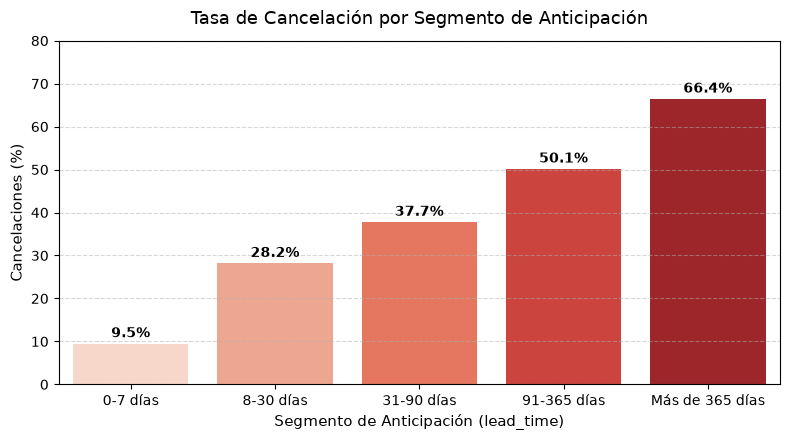

In [135]:
# Cálculo de la tasa de cancelación porcentual por cada segmento
datos_resumen = df.groupby('lead_time_segment', observed=False).agg(
    tasa_cancelacion=('is_canceled', lambda x: x.mean() * 100)
).reset_index()

# Creación y parametrización del gráfico
plt.figure(figsize=(8, 4.5))

ax = sns.barplot(
    data=datos_resumen,
    x='lead_time_segment', 
    y='tasa_cancelacion', 
    palette='Reds'
)

plt.title('Tasa de Cancelación por Segmento de Anticipación', fontsize=13, pad=12)
plt.xlabel('Segmento de Anticipación (lead_time)', fontsize=11)
plt.ylabel('Cancelaciones (%)', fontsize=11)
plt.ylim(0, 80)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Inclusión de las etiquetas con el porcentaje exacto sobre cada barra
for p in ax.patches:
    altura = p.get_height()
    if np.isnan(altura):
        altura = 0
    ax.annotate(
        f"{altura:.1f}%", 
        (p.get_x() + p.get_width() / 2., altura + 1.5), 
        ha='center', 
        fontsize=10, 
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

Se agrega a la bitacora

In [136]:
registrar(
    problema="Lead_time tiene muchos valores posibles y distribución sesgada",
    variable="lead_time_segment",
    decision="Se crea lead_time_segment mediante intervalos interpretables",
    justificacion="La discretización facilita comparar reservas inmediatas, de mediano plazo y anticipadas sin eliminar el valor original."
)

## Creacion de has_company y has_agent

Las columnas agent y company contienen los identificadores de la agencia de viajes o la empresa que gestionó la reserva. En ambas variables los valores nulos no son fallos de registro o datos perdidos al azar, sino ausencias que significan que no cuenta con aagente o empresa. Indica que la reserva fue hecha de manera particular y directa, sin intermediario ni convenio corporativo.

Crear las variables binarias has_agent y has_company permite simplificar esa información en un formato directo (1 si intervino un intermediario y 0 si fue directa), facilitando comparar si las reservas intermediadas cancelan más o menos que las particulares sin depender de cientos de identificadores numéricos dispersos.

In [137]:
# Creación de variables binarias indicadoras (1 = intervino / 0 = directo)
# Las ausencias ya se encuentra corregidas como ausente = 0 en las variables
df['has_agent'] = (df['agent'] != 0).astype('int8')
df['has_company'] = (df['company'] != 0).astype('int8')

# Verificación 
columnas_intermediarios = ['agent', 'has_agent', 'company', 'has_company']
print("Verificación de las primeras filas calculadas:")
display(df[columnas_intermediarios].head())

#Distribución de frecuencias y porcentajes
print("\nDistribución de frecuencias - has_agent:")
print(df['has_agent'].value_counts())
print("\nPorcentajes - has_agent:")
print(df['has_agent'].value_counts(normalize=True).round(4) * 100)

print("\nDistribución de frecuencias - has_company:")
print(df['has_company'].value_counts())
print("\nPorcentajes - has_company:")
print(df['has_company'].value_counts(normalize=True).round(4) * 100)

# Tasa de cancelación (%) según presencia de agente y empresa
print("\nCancelación por Agente:\n", (df.groupby('has_agent')['is_canceled'].mean() * 100).round(2))
print("\nCancelación por Empresa:\n", (df.groupby('has_company')['is_canceled'].mean() * 100).round(2))

Verificación de las primeras filas calculadas:


,agent,has_agent,company,has_company
0,0,0,292,1
1,240,1,0,0
2,240,1,0,0
3,9,1,0,0
4,0,0,0,0



Distribución de frecuencias - has_agent:
has_agent
1    21358
0     3429
Name: count, dtype: int64

Porcentajes - has_agent:
has_agent
1    86.17
0    13.83
Name: proportion, dtype: float64

Distribución de frecuencias - has_company:
has_company
0    23383
1     1404
Name: count, dtype: int64

Porcentajes - has_company:
has_company
0    94.34
1     5.66
Name: proportion, dtype: float64

Cancelación por Agente:
 has_agent
0    25.43
1    39.18
Name: is_canceled, dtype: float64

Cancelación por Empresa:
 has_company
0    38.46
1    17.66
Name: is_canceled, dtype: float64


**Impacto de los intermediarios (`has_agent` y `has_company`)**

- **`has_agent`** Concentra el **86,17%** de las operaciones del hotel. Las reservas gestionadas mediante agentes presentan una tasa de cancelación considerablemente mayor (**39,18%**) frente a las reservas directas (**25,43%**), lo que refleja el efecto de las facilidades de cancelación y la búsqueda de tarifas en plataformas externas.
- **Canal corporativo (`has_company`):** Representa un volumen minoritario (**5,66%** del total), mostrando que el perfil de huéspedes está dominado casi en su totalidad por viajeros particulares y turismo recreativo.

Estos contrastes confirman la utilidad de derivar ambas variables binarias para segmentar el riesgo de cancelación según el canal de origen.

### Market Segment y Distribution Channel

Ambas variables presentan categorías marginales con menos del 1% del total de registros (Aviation y Complementary en segmento. GDS en canal).  Agrupar estas clases poco frecuentes bajo la etiqueta 'Other' simplifica la estructura de los datos y previene la dispersión innecesaria al codificar, evitando crear columnas prácticamente vacías que no aportan valor predictivo 

In [138]:

# Agrupar categorías < 1% en market_segment ('Complementary' y 'Aviation')
df['market_segment'] = df['market_segment'].replace(['Complementary', 'Aviation'], 'Other')

# Agrupar categorías < 1% en distribution_channel ('GDS')
df['distribution_channel'] = df['distribution_channel'].replace('GDS', 'Other')

# Verificación de frecuencias
print("Frecuencias consolidadas - market_segment:")
print(df['market_segment'].value_counts())

print("\nFrecuencias consolidadas - distribution_channel:")
print(df['distribution_channel'].value_counts())



Frecuencias consolidadas - market_segment:
market_segment
Online TA        11764
Offline TA/TO     4975
Groups            4152
Direct            2611
Corporate         1100
Other              185
Name: count, dtype: int64

Frecuencias consolidadas - distribution_channel:
distribution_channel
TA/TO        20348
Direct        3009
Corporate     1391
Other           39
Name: count, dtype: int64


Se carga en la bitacora:

In [139]:
# 4. Asiento en la bitácora de transformación
registrar_transformacion(
    problema="Presencia de categorías con representación menor al 1% en market_segment (Aviation, Complementary) y distribution_channel (GDS)",
    variable="market_segment, distribution_channel",
    decision="Agrupación de categorías poco frecuentes bajo la etiqueta 'Other'",
    justificacion="Reduce la dispersión de categorías testimoniales y evita la creación de columnas dispersas o casi vacías."
)

### Has booking changes

Transformar los booking changes en la variable binaria has_booking_changes (1 si hubo al menos un cambio, 0 si no hubo) permite evaluar el compromiso del cliente y la probabilidad de no realizar una cancelacion

In [140]:


# Creación de la variable binaria (1 = con cambios, 0 = sin cambios)
df['has_booking_changes'] = (df['booking_changes'] > 0).astype('int8')

# Distribución y porcentaje
print("Frecuencias de has_booking_changes:")
print(df['has_booking_changes'].value_counts())
print("\nPorcentajes (%):")
print((df['has_booking_changes'].value_counts(normalize=True) * 100).round(2))

# Tasa de cancelación comparativa (%)
print("\nCancelación por has_booking_changes (%):")
print((df.groupby('has_booking_changes')['is_canceled'].mean() * 100).round(2))



Frecuencias de has_booking_changes:
has_booking_changes
0    21043
1     3744
Name: count, dtype: int64

Porcentajes (%):
has_booking_changes
0    84.9
1    15.1
Name: proportion, dtype: float64

Cancelación por has_booking_changes (%):
has_booking_changes
0    41.16
1    15.46
Name: is_canceled, dtype: float64


Es posible ver como si tiene cambios en la reserva, es menos probable que se realice una cancelacion.

Se guarda en la bitacora

In [141]:
# Registro en bitácora
registrar_transformacion(
    problema="booking_changes tiene más del 84% de valores en 0 y mucha cantidad de valores distintos positivos (mas de un cambio)",
    variable="has_booking_changes",
    decision="Creación de la variable binaria: 1 si booking_changes > 0, 0 en caso contrario",
    justificacion="Aísla el comportamiento de reservas, reduciendolas a si tiene o no."
)

## Bitacora de transformacion final:

In [142]:
print("Bitacora de transformacion:\n")
pd.DataFrame(transformacion_bitacora)


Bitacora de transformacion:



,problema_detectado,variable_afectada,decision_tomada,justificacion
0,Conocer el total de ocupación de la reserva en...,total_gests,"Suma de adults, children y babies","Se crea total_guests, muestra tamaño total del..."
1,Diferenciar reservas de adultos y de grupos fa...,is_family,Creación de variable binaria: 1 si (children >...,Simplifica la lectura del perfil del cliente y...
2,La duración completa de la estadía se encuentr...,total_stay_nights,Derivación por suma: stays_in_weekend_nights m...,Permite mostrar en una sola métrica la duració...
3,Necesidad de estimar el importe total de cada ...,estimated_stay_amount,Crear estimated_stay_amount como producto de a...,El importe estimado resume el valor de la rese...
4,Presencia de categorías con representación men...,"market_segment, distribution_channel",Agrupación de categorías poco frecuentes bajo ...,Reduce la dispersión de categorías testimonial...
5,booking_changes tiene más del 84% de valores e...,has_booking_changes,Creación de la variable binaria: 1 si booking_...,"Aísla el comportamiento de reservas, reduciend..."


## Resumen de los cambios realizados 

Verificacion de los datos:

In [143]:
columnas_nuevas = [
    'has_agent', 'has_company', 'total_stay_nights', 'total_guests',
    'estimated_stay_amount', 'is_family', 'has_booking_changes', 'lead_time_segment'
]

# VALIDACIONES DE INTEGRIDAD GENERAL Y TAMAÑO
registros_eliminados = len(df_original) - len(df)
assert registros_eliminados >= 0, "Error: Las filas finales no pueden superar a las originales"
assert len(df) == len(df_original) - registros_eliminados, "Error: Discrepancia en el conteo de registros eliminados"
assert df[columnas_nuevas].notna().all().all(), "Error: Existen valores nulos en las columnas nuevas"

# VALIDACIONES DE LIMPIEZA (REGLAS DE NEGOCIO Y CONSISTENCIA)

# Validar eliminación de inconsistencias operativas (noches, huéspedes y adultos)
assert (df['total_stay_nights'] > 0).all(), "Error: Quedaron reservas con 0 noches de estadía"
assert (df['total_guests'] > 0).all(), "Error: Quedaron reservas con 0 huéspedes totales"
assert (df['adults'] > 0).all(), "Error: Quedaron reservas sin adultos responsables"

# Validar depuración de outliers imposibles y errores contables
assert (df['adr'] >= 0).all(), "Error: Se detectaron tarifas diarias (ADR) negativas"

# Validar unificación de categorías y tratamiento de nulos
assert 'Undefined' not in df['meal'].values, "Error: La categoría Undefined en meal no fue reemplazada"
assert df['agent'].isnull().sum() == 0 and df['company'].isnull().sum() == 0, "Error: Quedan valores nulos en agent o company"


#VALIDACIONES DE TRANSFORMACIÓN (INDICADORES BINARIOS Y AGRUPACIONES)

# Validar que las variables binarias solo contengan valores {0, 1}
columnas_binarias = ['has_agent', 'has_company', 'is_family', 'has_booking_changes']
for col in columnas_binarias:
    assert set(df[col].unique()).issubset({0, 1}), f"Error: {col} contiene valores distintos de 0 y 1"

# Validar que las categorías minoritarias fueron agrupadas en 'Other'
assert not set(['Aviation', 'Complementary']).intersection(set(df['market_segment'].unique())), "Error: Categorías minoritarias en market_segment no agrupadas"
assert 'GDS' not in df['distribution_channel'].values, "Error: La categoría GDS no fue agrupada en distribution_channel"

# Validar que el importe estimado no sea negativo
assert (df['estimated_stay_amount'] >= 0).all(), "Error: estimated_stay_amount contiene valores negativos"

print("Todas las validaciones pasaron correctamente.")


# 4. SALIDA INFORMATIVA DEL ESTADO FINAL

print('Filas originales:', len(df_original))
print('Registros eliminados durante la limpieza:', registros_eliminados)
print('Filas del dataset preparado:', len(df))
print('Columnas:', len(df.columns))
print('\nColumnas Nuevas (Nuevas variables):')
print(columnas_nuevas)
print('\nVista del dataset preparado:')
display(df.head())

Todas las validaciones pasaron correctamente.
Filas originales: 25000
Registros eliminados durante la limpieza: 213
Filas del dataset preparado: 24787
Columnas: 38

Columnas Nuevas (Nuevas variables):
['has_agent', 'has_company', 'total_stay_nights', 'total_guests', 'estimated_stay_amount', 'is_family', 'has_booking_changes', 'lead_time_segment']

Vista del dataset preparado:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_day_of_month,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,...,required_car_parking_spaces,total_of_special_requests,total_guests,is_family,total_stay_nights,estimated_stay_amount,lead_time_segment,has_agent,has_company,has_booking_changes
0,Resort Hotel,0,17,2025,February,21,2025-02-21,0,1,1,...,1,1,1,0,1,58.00,8-30 días,0,1,0
1,Resort Hotel,0,6,2023,November,1,2023-11-01,2,1,1,...,0,2,1,0,3,174.00,0-7 días,1,0,1
2,Resort Hotel,0,45,2024,April,8,2024-04-08,0,1,2,...,0,2,2,0,1,65.00,31-90 días,1,0,1
3,City Hotel,0,95,2024,March,17,2024-03-17,2,3,2,...,0,1,2,0,5,369.75,91-365 días,1,0,0
4,City Hotel,1,277,2024,November,7,2024-11-07,1,2,2,...,0,0,2,0,3,300.00,91-365 días,0,0,0


## Resumen metodológico: Limpieza vs. Transformación

### 1. Fase de Limpieza (Curación de datos)
* **Eliminación de atributos sin valor analítico:** Se descartaron `booking_id` (identificador único sin capacidad predictiva) y `arrival_date_week_number` (redundancia temporal frente al año, mes y día de llegada).
* **Tratamiento de inconsistencias lógicas (filtrado de registros):** Se solucionaron anomalías operativas eliminando reservas sin pernocte (estadía de 0 noches), reservas sin ocupantes o con menores de edad sin adultos a cargo, errores tipográficos imposibles (`babies >= 9`) y un registro erróneo de tarifa negativa (`adr < 0`).
* **Corrección de tipos y unificación de categorías:** Se reclasificó `'Undefined'` como `'SC'` (*Self Catering*) en la variable `meal`, se transformó `children` al tipo discreto entero (`int64`) y se imputaron con `0` las ausencias estructurales en `agent` y `company` (indicando reservas directas y particulares).

### 2. Fase de Transformación
* **Derivación de totales e importes agregados:** Mediante operaciones aritméticas, se sintetizaron métricas globales como `total_guests` (suma total de personas), `total_stay_nights` (duración total del alojamiento uniendo días hábiles y fines de semana) y `estimated_stay_amount` (producto entre la tarifa diaria `adr` y las noches totales)
* **Creación de variables binarias indicadoras:** Se generaron banderas codificadas en `{0, 1}` para aislar comportamientos predictivos clave: `is_family` (presencia de menores), `has_agent` (intermediación comercial), `has_company` (origen corporativo) y `has_booking_changes` (gestión activa de la reserva
* **Consolidación de categorías marginales:** Se agruparon aquellas clases con frecuencias inferiores al 1% bajo la etiqueta `'Other'` (`Aviation` y `Complementary` en `market_segment`; `GDS` en `distribution_channel`), previniendo la dispersión de columnas en futuras codificaciones
* **Discretización:** Se segmentó `lead_time` en rangos temporales homogéneos para facilitar el análisis por ventanas de anticipación sin verse distorsionado por la asimetría de valores atípicos.

---

## ¿Cómo quedó preparado el dataset?

El conjunto de datos quedó consolidado como una **matriz depurada, consistente y enriquecida para el análisis del negocio**:

1. **Integridad operacional asegurada:** No contiene registros incompletos, reservas ficticias sin ocupantes ni distorsiones de facturación, asegurando que cada fila represente un suceso realista del dataset.
2. **Estructura dimensional controlada:** Se eliminó el ruido provocado por identificadores internos y redundancias de calendario, controlando además la dispersión de categorías testimoniales al unificarlas en `'Other'`.
3. **Ausencias contextualizadas numéricamente:** Los identificadores de intermediación (`agent` y `company`) fueron binarizados, evitando la presencia de nulos que distorsionen los cálculos algorítmicos.
4. **Mayor potencia predictiva sobre la cancelación:** Se generaron atributos de volumen, compromiso del cliente (modificaciones) y tipo de canal, aislando los segmentos de mayor y menor riesgo respecto a la variable objetivo `is_canceled`.
5. **Aptitud para modelado y exploración:** Los datos se encuentran en un estado óptimo para continuar con el trabajo

---
---
---

# Entrega numero 3: Visualización e interpretación de datos

En esta tercera etapa se utilizan **visualizaciones para explorar los patrones de cancelación** y comprender cómo se comporta la variable objetivo `is_canceled` frente a distintas características de las reservas.

A partir del dataset previamente preparado, se comparan las reservas canceladas y no canceladas considerando variables como el **tipo de hotel, la anticipación de la reserva (`lead_time`) y el segmento de mercado**.

Las visualizaciones permiten detectar diferencias entre grupos y reconocer posibles factores asociados a una mayor o menor tasa de cancelación.

El objetivo de esta etapa es pasar de los datos preparados a una **interpretación visual de los patrones**, identificando asociaciones relevantes que puedan orientar los análisis posteriores, sin asumir que estas relaciones implican causalidad.

### Cancelaciones según tipo de hotel

**¿Los hoteles urbanos y los hoteles resort presentan diferencias en la proporción de reservas canceladas?**

***Por qué este gráfico:***

Un countplot con dos colores permite comparar cantidades entre categorías y distinguir canceladas vs no canceladas de forma clara.


Visualización 1: Cancelaciones según tipo de hotel



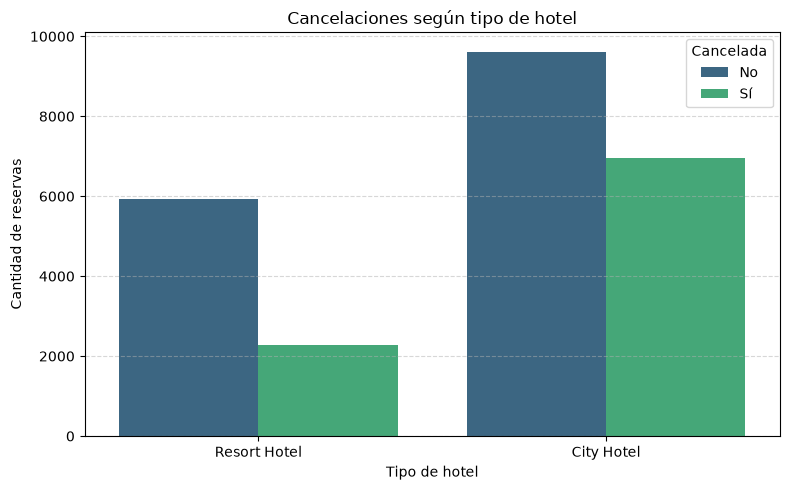

In [144]:
import matplotlib.pyplot as plt
import seaborn as sns

print("\nVisualización 1: Cancelaciones según tipo de hotel\n")

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='hotel',
    hue='is_canceled',
    palette='viridis'
)

plt.title("Cancelaciones según tipo de hotel")
plt.xlabel("Tipo de hotel")
plt.ylabel("Cantidad de reservas")
plt.legend(title="Cancelada", labels=["No", "Sí"])
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


### Variable cuantitativa vs cancelación (lead_time)

**¿Las reservas con mayor anticipación (lead_time) tienen más probabilidad de ser canceladas?**

***Por qué este gráfico:***

Un boxplot permite comparar la distribución de una variable numérica entre dos grupos (cancelada vs no cancelada), mostrando diferencias en medianas y dispersión.


Visualización 2: Lead time vs Cancelación



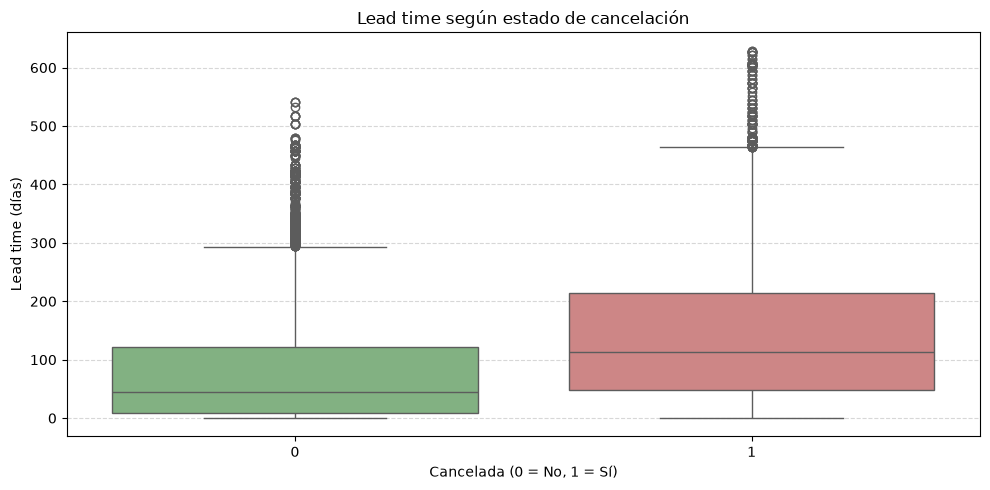

In [145]:
print("\nVisualización 2: Lead time vs Cancelación\n")

plt.figure(figsize=(10,5))


sns.boxplot(
    data=df,
    x='is_canceled',
    y='lead_time',
    hue='is_canceled',                 
    palette=['#7ab97a', '#d97a7a', ],
    legend=False                       
)

plt.title("Lead time según estado de cancelación")
plt.xlabel("Cancelada (0 = No, 1 = Sí)")
plt.ylabel("Lead time (días)")
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


### Otra visualizacion para la cancelacion por lead time 

Se agrupa `lead_time` en `lead_time_segment` para poder visualizar las tasas de cancelaciones basadas en 5 grupos y no todos los datos al mismo tiempo, lo que permite visualizar el patron mas facilmente.

- **Reservas inmediatas (0-7 días):** Presentan un compromiso muy alto, con una tasa de cancelación de apenas el **9,48%**.
- **Reservas planificadas (91-365 días):** Es el segmento con mayor volumen (9.921 casos), donde la tasa de cancelación llega al **50,14%**, lo que implica que la mitad de estas operaciones no se concretan.
- **Reservas a más de un año (>365 días):** Registran el pico máximo de riesgo (**66,41%** de cancelaciones), confirmando que las reservas a muy largo plazo son altamente volátiles.

***Por qué este gráfico***
Se utiliza un barplot con tasas porcentuales porque permite comparar segmentos de anticipación y visualizar claramente cómo varía el riesgo de cancelación entre ellos.
Además, las etiquetas sobre cada barra facilitan la lectura exacta del porcentaje.

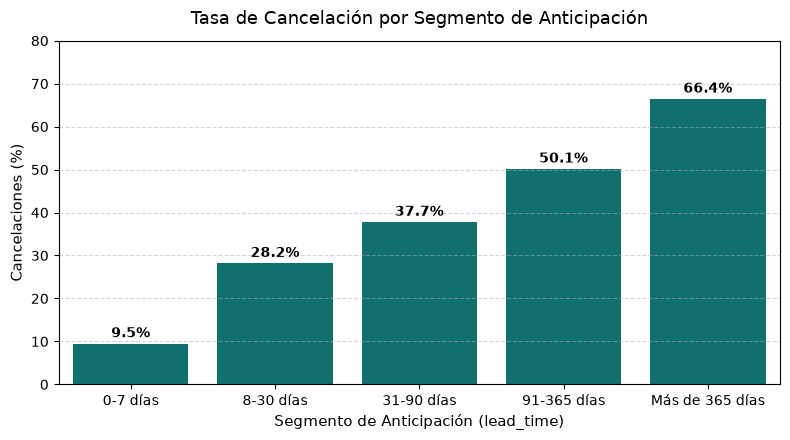

In [146]:
# Cálculo de la tasa de cancelación porcentual por cada segmento
datos_resumen = df.groupby('lead_time_segment', observed=False).agg(
    tasa_cancelacion=('is_canceled', lambda x: x.mean() * 100)
).reset_index()

# Creación y parametrización del gráfico
plt.figure(figsize=(8, 4.5))

ax = sns.barplot(
    data=datos_resumen,
    x='lead_time_segment',
    y='tasa_cancelacion',
    color='teal'   
)
plt.title('Tasa de Cancelación por Segmento de Anticipación', fontsize=13, pad=12)
plt.xlabel('Segmento de Anticipación (lead_time)', fontsize=11)
plt.ylabel('Cancelaciones (%)', fontsize=11)
plt.ylim(0, 80)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Inclusión de las etiquetas con el porcentaje exacto sobre cada barra
for p in ax.patches:
    altura = p.get_height()
    if np.isnan(altura):
        altura = 0
    ax.annotate(
        f"{altura:.1f}%", 
        (p.get_x() + p.get_width() / 2., altura + 1.5), 
        ha='center', 
        fontsize=10, 
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

### Cancelación según segmento de mercado

**¿Existen segmentos de mercado con mayor riesgo de cancelación?**

***Por qué este gráfico:***

Un barplot con tasa de cancelación permite comparar directamente el porcentaje de cancelaciones entre segmentos, revelando diferencias de comportamiento entre tipos de clientes.


Visualización 3: Cancelación según segmento de mercado



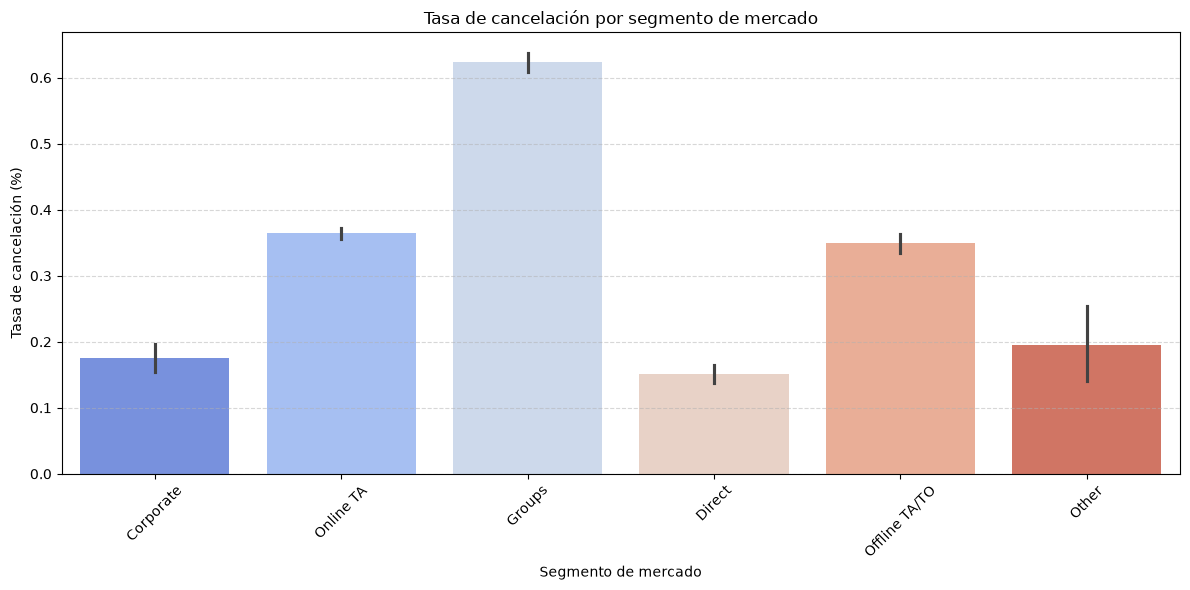

In [147]:
print("\nVisualización 3: Cancelación según segmento de mercado\n")

plt.figure(figsize=(12,6))

sns.barplot(
    data=df,
    x='market_segment',
    y='is_canceled',
    hue='market_segment',     
    palette='coolwarm',
    legend=False              
)

plt.title("Tasa de cancelación por segmento de mercado")
plt.xlabel("Segmento de mercado")
plt.ylabel("Tasa de cancelación (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


## Síntesis de hallazgos y limitaciones
A partir de las visualizaciones construidas se identifican tres patrones relevantes para comprender el fenómeno de cancelación en reservas hoteleras:

- El tipo de hotel influye en el comportamiento de cancelación.  
Los hoteles urbanos presentan una proporción mayor de cancelaciones que los hoteles resort, lo que sugiere que los viajes de corta estadía o laborales podrían estar asociados a mayor volatilidad en las reservas.

- La anticipación de la reserva es un predictor fuerte del riesgo de cancelación.  
Las reservas hechas con mucha anticipación muestran tasas de cancelación significativamente más altas. En particular, las reservas superiores al año presentan el mayor riesgo, lo que evidencia que la incertidumbre temporal afecta la concreción de la estadía.

- El segmento de mercado condiciona el nivel de cancelación.  
Los segmentos intermediados, especialmente Online TA y TA/TO, exhiben tasas de cancelación superiores a otros canales. Esto puede estar vinculado a políticas más flexibles, reservas masivas o menor compromiso inicial del cliente.

**Limitación y precaución analítica**

Si bien los patrones observados son consistentes, deben interpretarse con cautela porque el análisis se basa en relaciones descriptivas y no en modelos causales.
Las visualizaciones muestran asociaciones, pero no permiten afirmar causalidad. Además, algunas variables pueden estar correlacionadas entre sí (por ejemplo, lead_time y segmento de mercado), lo que requiere análisis más avanzados para evitar conclusiones simplificadas.

---
---
---

# Semana 9 - Análisis Exploratorio Inicial (SQL + Python)

Analisis Previo a entrega 4


Inicio del Notebook de la semana 9 y el analisis exploratorio.
Se pasa a explorar variables y formular preguntas e hipotesis.

## 2. Variable objetivo: `is_canceled`

La variable `is_canceled` indica si la reserva fue cancelada.

- **0:** la reserva no fue cancelada  
- **1:** la reserva sí fue cancelada  

Esta variable será el eje del análisis exploratorio inicial.

---

## 3. Estructura del dataset

El dataset contiene aproximadamente 24.900 reservas luego de la limpieza.  
Las columnas incluyen variables numéricas, categóricas y temporales.  
La estructura es consistente con el diccionario original del dataset hotelero.

### Se utiliza DuckDB para inspeccionar la tabla resultante después de la limpieza.

- Primero se crea la conexion

In [148]:
# Crear conexión en memoria
con = duckdb.connect(":memory:")

# Registrar el DataFrame de trabajo (df)
con.register("df", df)

# Crear tabla SQL a partir del DataFrame
con.execute("""
    CREATE OR REPLACE TABLE reservas AS
    SELECT * FROM df
""")

df = con.sql("SELECT * FROM reservas").df()

print(f"Entorno preparado: {len(df):,} registros disponibles en la tabla 'reservas'.")

Entorno preparado: 24,787 registros disponibles en la tabla 'reservas'.


#### Tabla resultante:

In [149]:
describe = con.sql("DESCRIBE reservas")

total_filas = con.sql("SELECT COUNT(*) AS total_filas FROM df")

first_10 = con.sql("SELECT * FROM df LIMIT 10")

print(f"Descipcion de la tabla: \n{describe}")
print(f"\nTotal de filas: \n{total_filas}")
print(f"\nPrimeras 10 filas: \n{first_10}")


Descipcion de la tabla: 
┌─────────────────────────────┬───────────────────────────────────────────────────────────────────────────────┬─────────┬─────────┬─────────┬─────────┐
│         column_name         │                                  column_type                                  │  null   │   key   │ default │  extra  │
│           varchar           │                                    varchar                                    │ varchar │ varchar │ varchar │ varchar │
├─────────────────────────────┼───────────────────────────────────────────────────────────────────────────────┼─────────┼─────────┼─────────┼─────────┤
│ hotel                       │ VARCHAR                                                                       │ YES     │ NULL    │ NULL    │ NULL    │
│ is_canceled                 │ BIGINT                                                                        │ YES     │ NULL    │ NULL    │ NULL    │
│ lead_time                   │ BIGINT                         

### Interpretación
El dataset contiene 24787 reservas luego de la limpieza.

Las columnas incluyen variables numéricas, categóricas y temporales.

---


## 4. Selección de variables relevantes

Se seleccionan cinco variables clave para el análisis exploratorio inicial:

1. `is_canceled` - variable objetivo  
2. `lead_time` - anticipación de la reserva  
3. `hotel` - tipo de hotel  
4. `total_stay_nights` - duración total de la estadía  
5. `market_segment` - segmento de mercado  

Estas variables permiten observar patrones iniciales sin comparaciones multivariadas.

---

## 5. Distribución inicial de `is_canceled`

La proporción entre reservas canceladas y no canceladas muestra el comportamiento general del dataset.  


In [150]:
con.sql("""
    SELECT 
        is_canceled,
        COUNT(*) AS cantidad,
        ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM df), 2) AS porcentaje
FROM df
GROUP BY is_canceled
ORDER BY is_canceled;
""")

┌─────────────┬──────────┬────────────┐
│ is_canceled │ cantidad │ porcentaje │
│    int64    │  int64   │   double   │
├─────────────┼──────────┼────────────┤
│           0 │    15546 │      62.72 │
│           1 │     9241 │      37.28 │
└─────────────┴──────────┴────────────┘


### Visualizacion:


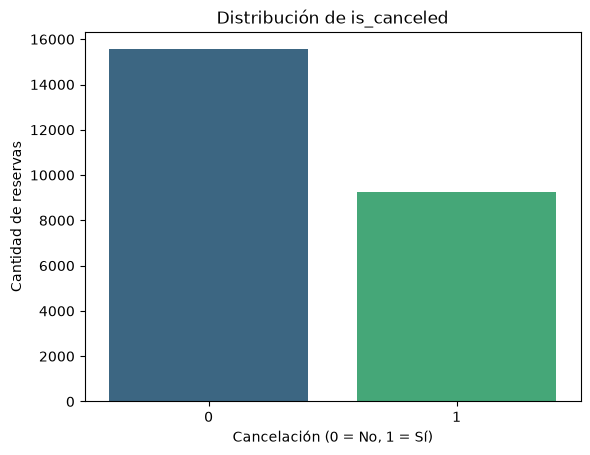

In [151]:

sns.countplot(
    data=df,
    x='is_canceled',
    hue='is_canceled',
    palette='viridis',
    legend=False
)

plt.title('Distribución de is_canceled')
plt.xlabel('Cancelación (0 = No, 1 = Sí)')
plt.ylabel('Cantidad de reservas')
plt.show()


El 62.72% de las reservas no fueron canceladas, mientras que el 37.28% sí se cancelaron. Esto muestra que, aunque la mayoría se completa, la proporción de cancelaciones es considerable dentro del dataset.

---

## 6. Resumen descriptivo de variables seleccionadas y Visualizaciones iniciales

- ### `lead_time` (cuantitativa)

Tabla de frecuencias de la variable


In [152]:
con.sql("""
    SELECT
        COUNT(*) AS cantidad,
        MIN(lead_time) AS minimo,
        MAX(lead_time) AS maximo,
        AVG(lead_time) AS promedio,
        STDDEV(lead_time) AS desviacion
    FROM reservas
""")


┌──────────┬────────┬────────┬────────────────────┬────────────────────┐
│ cantidad │ minimo │ maximo │      promedio      │     desviacion     │
│  int64   │ int64  │ int64  │       double       │       double       │
├──────────┼────────┼────────┼────────────────────┼────────────────────┤
│    24787 │      0 │    629 │ 103.73308589179813 │ 106.66833772600566 │
└──────────┴────────┴────────┴────────────────────┴────────────────────┘

La anticipación de las reservas muestra valores muy bajos y muy altos, indicando que los clientes reservan tanto con pocos días como con muchos meses de anticipación.

### Visualizacion

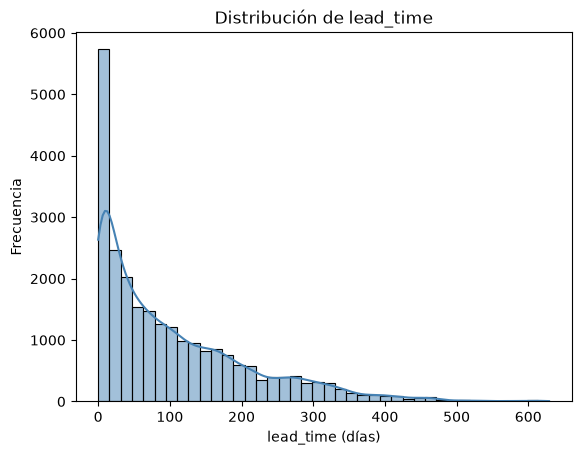

In [153]:
sns.histplot(df['lead_time'], bins=40, kde=True, color='steelblue')
plt.title('Distribución de lead_time')
plt.xlabel('lead_time (días)')
plt.ylabel('Frecuencia')
plt.show()

---

- ### `hotel` (categórica)

Tabla de frecuencias de la variable

In [154]:
con.sql("""
    SELECT 
        hotel,
        COUNT(*) AS cantidad,
        ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM reservas), 2) AS porcentaje
    FROM reservas
    GROUP BY hotel
    ORDER BY cantidad DESC
""")


┌──────────────┬──────────┬────────────┐
│    hotel     │ cantidad │ porcentaje │
│   varchar    │  int64   │   double   │
├──────────────┼──────────┼────────────┤
│ City Hotel   │    16583 │       66.9 │
│ Resort Hotel │     8204 │       33.1 │
└──────────────┴──────────┴────────────┘

### Visualizacion:

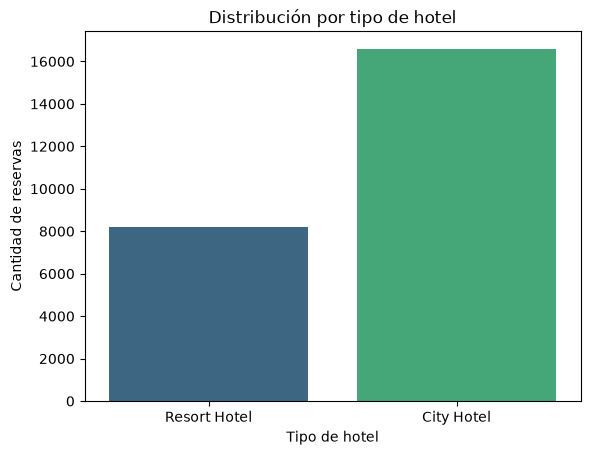

In [155]:
sns.countplot(
    data=df,
    x='hotel',
    hue='hotel',
    palette='viridis',
    legend=False
)

plt.title('Distribución por tipo de hotel')
plt.xlabel('Tipo de hotel')
plt.ylabel('Cantidad de reservas')
plt.show()


El dataset suele tener más reservas en City Hotel que en Resort Hotel.  
Esto puede influir en la proporción de cancelaciones por tipo de hotel.

---

- ### `market_segment` (categórica)

Tabla de frecuencias de la variable



In [156]:
segmento_mercado = con.sql("""
    SELECT 
        market_segment,
        COUNT(*) AS cantidad,
        ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM reservas), 2) AS porcentaje
    FROM reservas
    GROUP BY market_segment
    ORDER BY cantidad DESC
""")


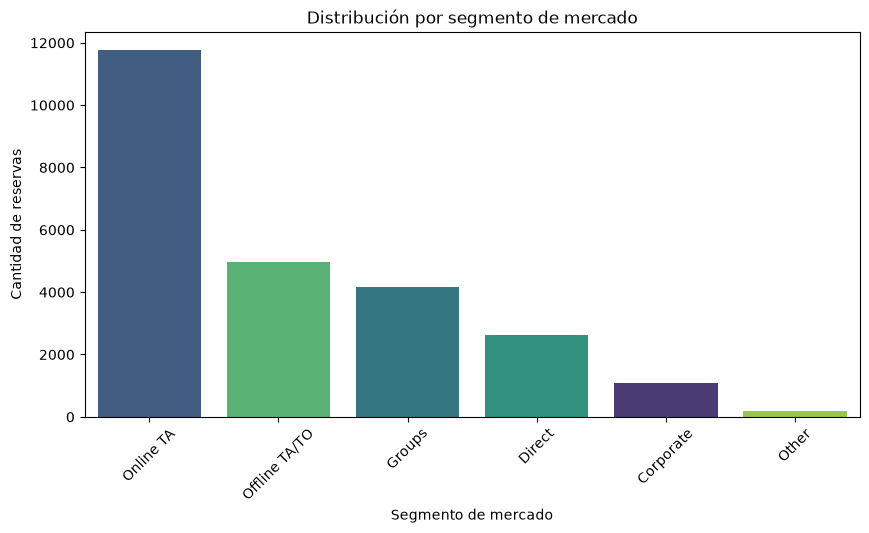

In [157]:
plt.figure(figsize=(10,5))

# Obtener orden de mayor a menos
orden = df['market_segment'].value_counts().sort_values(ascending=False).index

sns.countplot(
    data=df,
    x='market_segment',
    hue='market_segment',
    palette='viridis',
    legend=False,
    order=orden
)

plt.xticks(rotation=45)
plt.title('Distribución por segmento de mercado')
plt.xlabel('Segmento de mercado')
plt.ylabel('Cantidad de reservas')
plt.show()



Los segmentos Online TA y Direct suelen ser los más frecuentes, indicando que la mayoría de las reservas provienen de canales digitales.

---

- ### `total_stay_nights` (cuantitativa)

La mayoría de las estadías son cortas (1–4 noches).  
Las estadías largas son menos frecuentes pero podrían tener comportamientos distintos.

---

In [158]:
con.sql("""
    SELECT
        MIN(total_stay_nights) AS minimo,
        MAX(total_stay_nights) AS maximo,
        AVG(total_stay_nights) AS promedio
    FROM reservas
""")


┌────────┬────────┬────────────────────┐
│ minimo │ maximo │      promedio      │
│ int64  │ int64  │       double       │
├────────┼────────┼────────────────────┤
│      1 │     48 │ 3.4137249364586273 │
└────────┴────────┴────────────────────┘

### Visualizacion
Grafico de densidad (KDE) de `total_stay_nights`

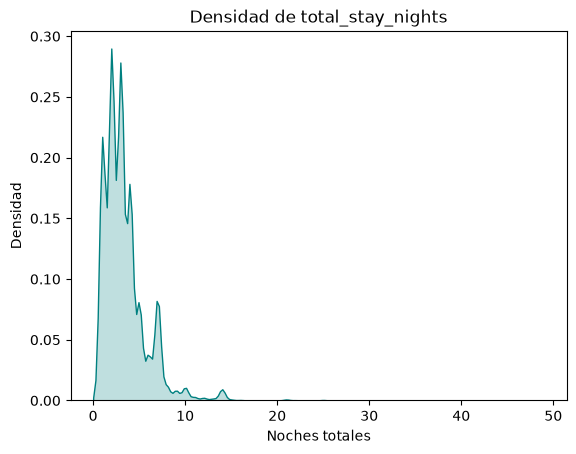

In [159]:
sns.kdeplot(df['total_stay_nights'], fill=True, color='teal')
plt.title('Densidad de total_stay_nights')
plt.xlabel('Noches totales')
plt.ylabel('Densidad')
plt.show()


La distribución está fuertemente concentrada en estadías de pocas noches.

---

## 7. Preguntas e hipótesis para Semana 10

1. ¿La anticipación (`lead_time`) podría estar asociada a la cancelación?  
2. ¿El tipo de hotel muestra diferencias en la proporción de cancelaciones?  
3. ¿El segmento de mercado influye en la probabilidad de cancelar?  
4. ¿La duración de la estadía podría relacionarse con la cancelación?  
5. ¿Existen meses o períodos del año con más cancelaciones?

---

## 8. Cierre Semana 9

En esta semana se realizó:

- identificación de la unidad de análisis,  
- revisión de la variable objetivo,  
- inspección estructural,  
- selección de variables relevantes,  
- análisis descriptivo inicial,  
- visualizaciones individuales,  
- interpretaciones descriptivas,  
- formulación de hipótesis para la próxima semana.

El dataset está listo para avanzar hacia comparaciones y análisis multivariados en la Semana 10.

---

---
---
---

# Semana 10 - Comparaciones exploratorias (SQL + Python) - Entrega 4

La Semana 10 continúa el análisis exploratorio iniciado previamente y se centra en comparar grupos para reconocer patrones, diferencias y comportamientos llamativos dentro del dataset de reservas hoteleras. El propósito no es construir un modelo predictivo ni demostrar relaciones causales, sino interpretar los resultados con prudencia y seleccionar variables que puedan resultar relevantes para las etapas posteriores.



## Se va a trabajar con tres preguntas / hipótesis seleccionadas de la Semana 9:

- ¿La anticipación `lead_time` podría estar asociada a la cancelación?
  - **Hipotesis:** Las reservas hechas con mucha anticipación podrían cancelarse con mayor frecuencia.

- ¿El tipo de hotel muestra diferencias en la proporción de cancelaciones?
  - **Hipotesis:** El City Hotel y el Resort Hotel muestran proporciones de cancelación diferentes.

- ¿El segmento de mercado influye en la probabilidad de cancelar?
  - **Hipotesis:** Algunos segmentos de mercado, especialmente los digitales, podrían presentar tasas de cancelación más altas que otros.
  
---

### Pregunta  1 - `lead_time` y cancelación

La primera pregunta del análisis exploratorio busca evaluar si la anticipación con la que se realiza una reserva, medida mediante la variable `lead_time`, podría estar asociada a su cancelación. La hipótesis inicial plantea que las reservas hechas con mayor anticipación podrían presentar una mayor probabilidad de cancelarse, ya sea por cambios en los planes del huésped, reprogramaciones o menor compromiso al momento de la reserva. Para explorar esta idea, se comparan las distribuciones de `lead_time` entre reservas canceladas y no canceladas, junto con resúmenes descriptivos y visualizaciones que permitan identificar patrones o diferencias relevantes entre ambos grupos.


In [160]:
# Resumen descriptivo de lead_time según cancelación
resumen_descriptivo = con.sql("""
    SELECT
        is_canceled,
        COUNT(*) AS cantidad_reservas,
        ROUND(AVG(lead_time), 2) AS promedio_lead_time,
        ROUND(STDDEV(lead_time), 2) AS desviacion_lead_time
    FROM reservas
    GROUP BY is_canceled
    ORDER BY is_canceled
""")

# segmentación de lead_time en tramos
lead_time_segmentos = con.sql("""
    WITH segmentos AS (
        SELECT
            CASE
                WHEN lead_time <= 7 THEN '0-7 días'
                WHEN lead_time BETWEEN 8 AND 30 THEN '8-30 días'
                WHEN lead_time BETWEEN 31 AND 90 THEN '31-90 días'
                WHEN lead_time BETWEEN 91 AND 365 THEN '91-365 días'
                ELSE 'Más de 365 días'
            END AS segmento_lead_time,
            is_canceled
        FROM reservas
    )
    SELECT
        segmento_lead_time,
        COUNT(*) AS total_reservas,
        SUM(CASE WHEN is_canceled = 1 THEN 1 ELSE 0 END) AS reservas_canceladas,
        ROUND(SUM(CASE WHEN is_canceled = 1 THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS porcentaje_canceladas
    FROM segmentos
    GROUP BY segmento_lead_time
    ORDER BY porcentaje_canceladas DESC
""")

print(f"Resumen descriptivo: \n{resumen_descriptivo}")
print(f"\nLead_time Segmentado: \n{lead_time_segmentos}")

Resumen descriptivo: 
┌─────────────┬───────────────────┬────────────────────┬──────────────────────┐
│ is_canceled │ cantidad_reservas │ promedio_lead_time │ desviacion_lead_time │
│    int64    │       int64       │       double       │        double        │
├─────────────┼───────────────────┼────────────────────┼──────────────────────┤
│           0 │             15546 │              79.24 │                90.76 │
│           1 │              9241 │             144.94 │               118.14 │
└─────────────┴───────────────────┴────────────────────┴──────────────────────┘


Lead_time Segmentado: 
┌────────────────────┬────────────────┬─────────────────────┬───────────────────────┐
│ segmento_lead_time │ total_reservas │ reservas_canceladas │ porcentaje_canceladas │
│      varchar       │     int64      │       int128        │        double         │
├────────────────────┼────────────────┼─────────────────────┼───────────────────────┤
│ Más de 365 días    │            661 │          

El siguiente gráfico muestra el promedio de lead_time (cantidad de días de anticipación con que se realizó la reserva) comparando entre reservas canceladas y reservas no canceladas. 

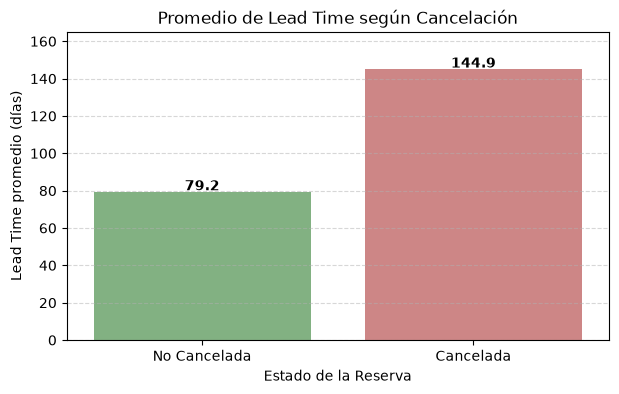

In [161]:
# pasando el resultado de DuckDB a pandas
df_resumen = resumen_descriptivo.df()

# Mapeo para que la leyenda sea clara
df_resumen['Estado'] = df_resumen['is_canceled'].map({0: 'No Cancelada', 1: 'Cancelada'})

plt.figure(figsize=(7,4))
ax = sns.barplot(
    data=df_resumen,
    x='Estado',
    y='promedio_lead_time',
    hue='Estado',                 
    palette=['#7ab97a', '#d97a7a']
                
)

plt.title("Promedio de Lead Time según Cancelación")
plt.xlabel("Estado de la Reserva")
plt.ylabel("Lead Time promedio (días)")
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Etiquetas encima de cada barra
for p in ax.patches:
    altura = p.get_height()
    ax.annotate(
        f"{altura:.1f}",
        (p.get_x() + p.get_width() / 2., altura + 1),
        ha='center', fontsize=10, fontweight='bold'
    )

ax.set_ylim(0, df_resumen['promedio_lead_time'].max() + 20)

plt.show()


*Grafico de Tasa de Cancelacion por Segmento*

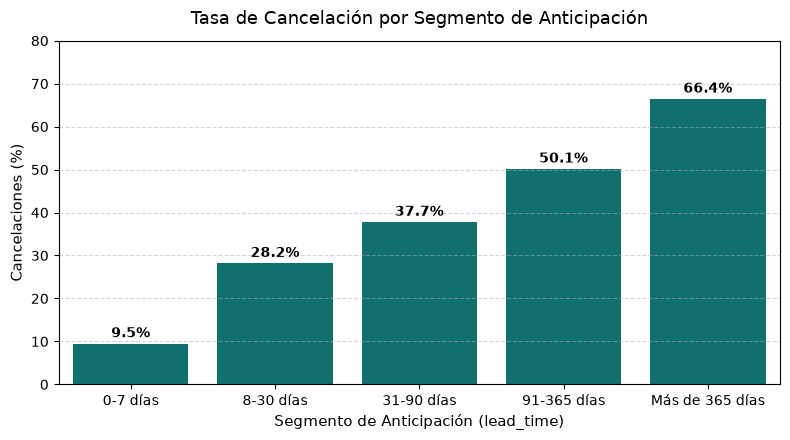

In [162]:
# Cálculo de la tasa de cancelación porcentual por cada segmento
datos_resumen = df.groupby('lead_time_segment', observed=False).agg(
    tasa_cancelacion=('is_canceled', lambda x: x.mean() * 100)
).reset_index()

# Creación y parametrización del gráfico
plt.figure(figsize=(8, 4.5))

ax = sns.barplot(
    data=datos_resumen,
    x='lead_time_segment',
    y='tasa_cancelacion',
    color='teal'   
)
plt.title('Tasa de Cancelación por Segmento de Anticipación', fontsize=13, pad=12)
plt.xlabel('Segmento de Anticipación (lead_time)', fontsize=11)
plt.ylabel('Cancelaciones (%)', fontsize=11)
plt.ylim(0, 80)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Inclusión de las etiquetas con el porcentaje exacto sobre cada barra
for p in ax.patches:
    altura = p.get_height()
    if np.isnan(altura):
        altura = 0
    ax.annotate(
        f"{altura:.1f}%", 
        (p.get_x() + p.get_width() / 2., altura + 1.5), 
        ha='center', 
        fontsize=10, 
        fontweight='bold'
    )

plt.tight_layout()
plt.show()


**Interpretación**

Las reservas *canceladas* presentan un promedio de `lead_time` significativamente mayor que las *no canceladas*. En los datos analizados, las reservas *no canceladas* muestran un promedio de 79.2 días, mientras que las *canceladas* alcanzan un promedio de 144.9 días de anticipación.

Al segmentar la anticipación en tramos, se observa que los porcentajes de cancelación aumentan en los segmentos de mayor anticipación, especialmente a partir de los **31 días**. 

El gráfico demuestra esto: las reservas realizadas con muchos días de anticipación concentran una proporción más alta de cancelaciones, mientras que las reservas de corto plazo muestran menos cancelaciones relativas.

---


## Pregunta 2 - tipo de `hotel` y cancelación

La segunda pregunta busca explorar si el tipo de hotel podría influir en el comportamiento de la cancelación. La hipótesis sugiere que los huéspedes del City Hotel y del Resort Hotel podrían presentar patrones distintos, pudiendo ser por diferencias en el perfil del cliente, el tipo de viaje o las temporadas de las reservas. Para examinar esto ,se comparan las tasas de cancelación entre ambos tipos de hotel y se analizan sus distribuciones para identificar diferencias o comportamientos llamativos.


In [163]:
#Cancelaciones por tipo de hotel
cancelaciones_tipo_hotel = con.sql("""
    SELECT
        hotel,
        COUNT(*) AS total_reservas,
        SUM(CASE WHEN is_canceled = 1 THEN 1 ELSE 0 END) AS reservas_canceladas,
        ROUND(SUM(CASE WHEN is_canceled = 1 THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS porcentaje_canceladas
    FROM reservas
    GROUP BY hotel
    ORDER BY total_reservas DESC
""")

reservas_cantidad_porcentaje = con.sql("""
SELECT
    hotel,
    is_canceled,
    COUNT(*) AS cantidad,
    ROUND(
        COUNT(*) * 100.0 /
        SUM(COUNT(*)) OVER (PARTITION BY hotel)
    , 2) AS porcentaje_del_total
FROM reservas
GROUP BY hotel, is_canceled
ORDER BY hotel, is_canceled;
""")

print(f"Cancelaciones por tipo de Hotel: \n{cancelaciones_tipo_hotel}")
print(f"\nPorcentaje que representa cada estado dentro del total del hotel: \n{reservas_cantidad_porcentaje}")

Cancelaciones por tipo de Hotel: 
┌──────────────┬────────────────┬─────────────────────┬───────────────────────┐
│    hotel     │ total_reservas │ reservas_canceladas │ porcentaje_canceladas │
│   varchar    │     int64      │       int128        │        double         │
├──────────────┼────────────────┼─────────────────────┼───────────────────────┤
│ City Hotel   │          16583 │                6964 │                 41.99 │
│ Resort Hotel │           8204 │                2277 │                 27.75 │
└──────────────┴────────────────┴─────────────────────┴───────────────────────┘


Porcentaje que representa cada estado dentro del total del hotel: 
┌──────────────┬─────────────┬──────────┬──────────────────────┐
│    hotel     │ is_canceled │ cantidad │ porcentaje_del_total │
│   varchar    │    int64    │  int64   │        double        │
├──────────────┼─────────────┼──────────┼──────────────────────┤
│ City Hotel   │           0 │     9619 │                58.01 │
│ City Hotel

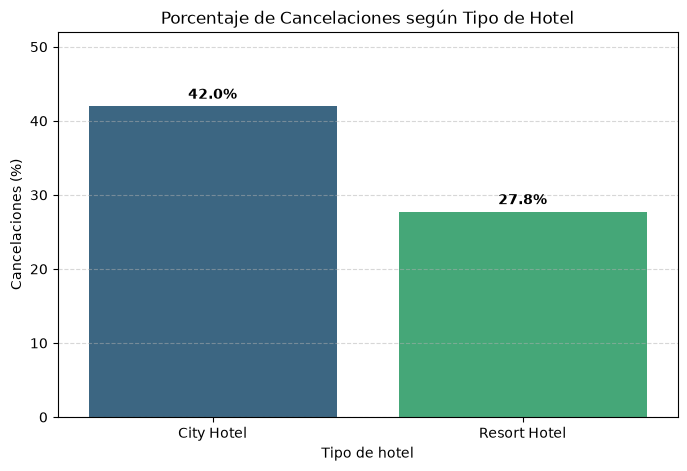

In [164]:
# Convertir DuckDB a pandas
df_hoteles = cancelaciones_tipo_hotel .df()

plt.figure(figsize=(8,5))

ax = sns.barplot(
    data=df_hoteles,
    x='hotel',
    y='porcentaje_canceladas',
    hue='hotel',
    palette='viridis',
    legend=False
)

plt.title("Porcentaje de Cancelaciones según Tipo de Hotel")
plt.xlabel("Tipo de hotel")
plt.ylabel("Cancelaciones (%)")
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Etiquetas encima de cada barra
for p in ax.patches:
    altura = p.get_height()
    ax.annotate(
        f"{altura:.1f}%",
        (p.get_x() + p.get_width() / 2., altura + 1),
        ha='center',
        fontsize=10,
        fontweight='bold'
    )

ax.set_ylim(0, df_hoteles['porcentaje_canceladas'].max() + 10)

plt.show()



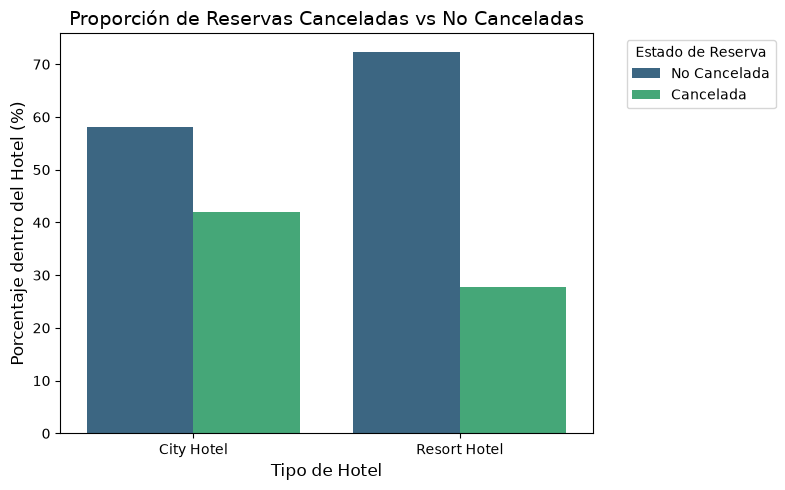

In [165]:
# se pasa el resultado a DataFrame
df_proporciones = reservas_cantidad_porcentaje.df()

# se mapea los valores 0 y 1 a texto para que la leyenda sea más clara
df_proporciones['Estado'] = df_proporciones['is_canceled'].map({1: 'Cancelada', 0: 'No Cancelada'})

plt.figure(figsize=(8, 5))
sns.barplot(
    data=df_proporciones, 
    x='hotel', 
    y='porcentaje_del_total', 
    hue='Estado', 
    palette='viridis'
)

plt.title('Proporción de Reservas Canceladas vs No Canceladas', fontsize=14)
plt.xlabel('Tipo de Hotel', fontsize=12)
plt.ylabel('Porcentaje dentro del Hotel (%)', fontsize=12)

# Leyenda fuera del gráfico para que no tape las barras
plt.legend(title='Estado de Reserva', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()

plt.show()

**Interpretación**

El **City Hotel** concentra la mayor cantidad de reservas, pero al comparar porcentajes se observan diferencias en la proporción de cancelaciones entre ambos tipos de `hotel`. El gráfico permite visualizar cuántas reservas *canceladas* y no *canceladas* se registran en cada tipo de hotel, mostrando que el comportamiento de cancelación no es idéntico entre **City Hotel** y** Resort Hotel**.

---

## Pregunta 3 - `market_segment` y cancelación

La tercera pregunta analiza si el segmento de mercado (`market_segment`) está asociado a la probabilidad de cancelar una reserva. La hipótesis es que ciertos canales, como agencias online o segmentos corporativos, podrían mostrar tasas de cancelación diferentes debido a sus dinámicas particulares de reserva, reprogramación o gestión de disponibilidad. Para evaluar esta hipótesis, se comparan las proporciones de cancelación entre segmentos y se observan patrones que permitan identificar grupos con comportamientos diferenciados.


In [166]:
#Cancelaciones por segmento de mercado
df_segmentos = con.sql("""
    SELECT
        market_segment,
        COUNT(*) AS total_reservas,

        -- Canceladas
        SUM(CASE WHEN is_canceled = 1 THEN 1 ELSE 0 END) AS reservas_canceladas,
        ROUND(SUM(CASE WHEN is_canceled = 1 THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS porcentaje_canceladas,

        -- No canceladas
        SUM(CASE WHEN is_canceled = 0 THEN 1 ELSE 0 END) AS reservas_no_canceladas,
        ROUND(SUM(CASE WHEN is_canceled = 0 THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS porcentaje_no_canceladas

    FROM reservas
    GROUP BY market_segment
    ORDER BY porcentaje_canceladas DESC
""").df()

df_segmentos


,market_segment,total_reservas,reservas_canceladas,porcentaje_canceladas,reservas_no_canceladas,porcentaje_no_canceladas
0,Groups,4152,2588.0,62.33,1564.0,37.67
1,Online TA,11764,4295.0,36.51,7469.0,63.49
2,Offline TA/TO,4975,1736.0,34.89,3239.0,65.11
3,Other,185,36.0,19.46,149.0,80.54
4,Corporate,1100,193.0,17.55,907.0,82.45
5,Direct,2611,393.0,15.05,2218.0,84.95


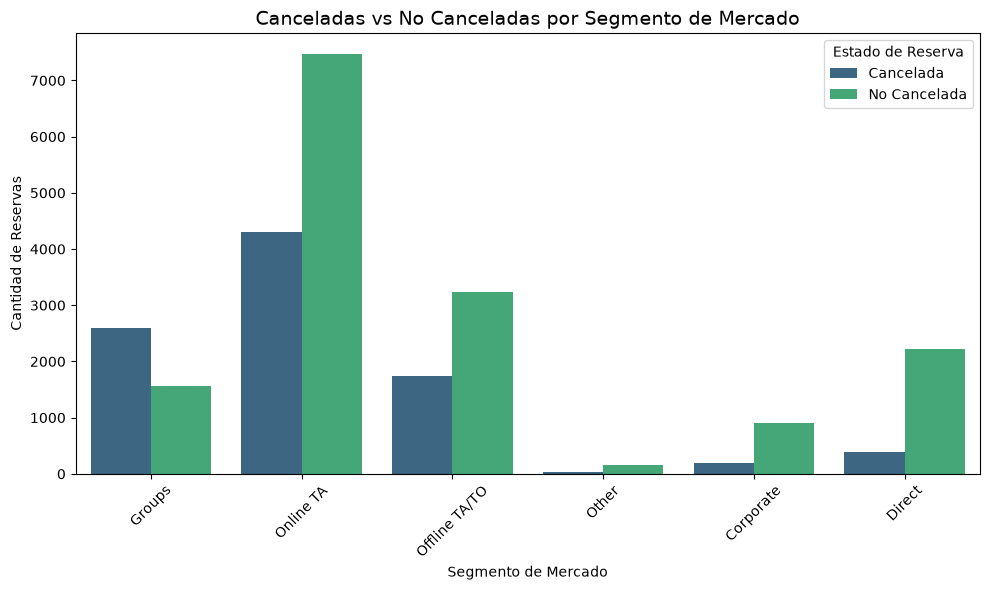

In [167]:
df_grafico_Segmentos = df_segmentos.melt(
    id_vars='market_segment',
    value_vars=['reservas_canceladas', 'reservas_no_canceladas'],
    var_name='Estado',
    value_name='Cantidad'
)

df_grafico_Segmentos['Estado'] = df_grafico_Segmentos['Estado'].map({
    'reservas_canceladas': 'Cancelada',
    'reservas_no_canceladas': 'No Cancelada'
})

plt.figure(figsize=(10,6))
sns.barplot(
    data=df_grafico_Segmentos,
    x='market_segment',
    y='Cantidad',
    hue='Estado',
    palette='viridis'
)

plt.xticks(rotation=45)
plt.title('Canceladas vs No Canceladas por Segmento de Mercado', fontsize=14)
plt.xlabel('Segmento de Mercado')
plt.ylabel('Cantidad de Reservas')
plt.legend(title='Estado de Reserva')
plt.tight_layout()
plt.show()


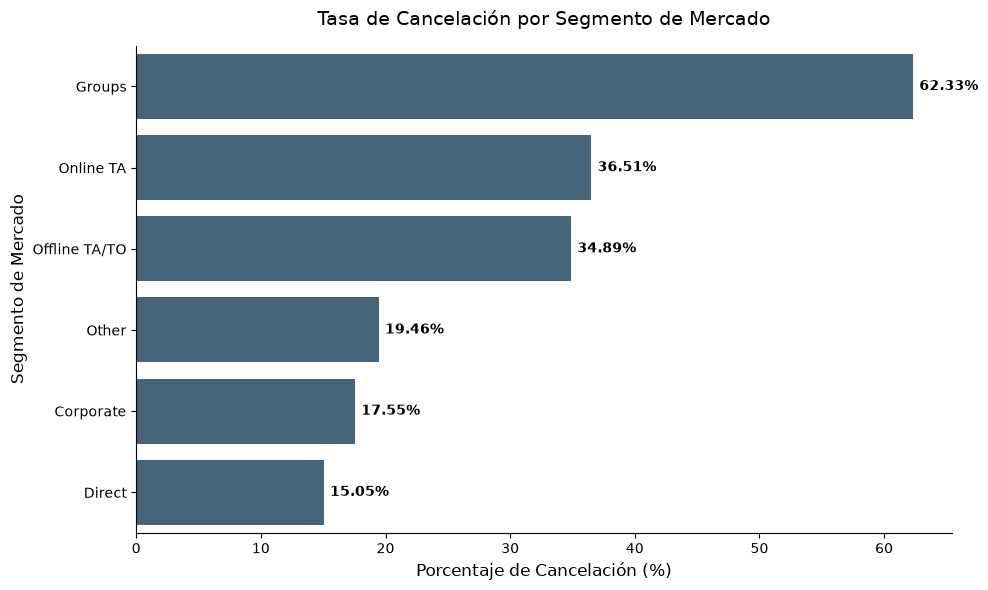

In [168]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=df_segmentos,
    x='porcentaje_canceladas',
    y='market_segment',
    color='#3c6682'
)

plt.title('Tasa de Cancelación por Segmento de Mercado', fontsize=14, pad=15)
plt.xlabel('Porcentaje de Cancelación (%)', fontsize=12)
plt.ylabel('Segmento de Mercado', fontsize=12)

# Etiquetas con porcentaje 
for index, value in enumerate(df_segmentos['porcentaje_canceladas']):
    ax.text(value + 0.5, index, f'{value}%', va='center', fontsize=10, fontweight='bold')

sns.despine()
plt.tight_layout()
plt.show()



**Interpretación**


La tabla y el gráfico muestran la proporción de reservas canceladas según cada segmento de mercado. Se observa que el segmento **Groups** presenta la tasa de cancelación más alta del dataset (62.33%), seguido por **Online TA** (36.51%) y **Offline TA/TO** (34.89%). En contraposición, los segmentos **Direct** (15.05%) y **Corporate** (17.55%) registran los porcentajes de cancelación más bajos. Esto indica una diferencia sustancial en la concreción de las reservas dependiendo del canal o tipo de cliente por el que ingresan.

---


## Patrones y casos llamativos

Al comparar los segmentos de mercado, aparecen diferencias claras en el comportamiento de cancelación. **Online TA** (Las Agencias de viaje Online) concentra una proporción elevada de reservas canceladas, lo que sugiere que este canal podría tener mayor variabilidad o menor compromiso previo del cliente. En contraste, segmentos como Direct o Corporate muestran porcentajes más bajos y estables, mostrando comportamientos más predecibles.

También se observan casos llamativos en los extremos de `lead_time`: las reservas realizadas con muy poca anticipación **(0–7 días)** presentan tasas de cancelación relativamente bajas, mientras que las reservas con anticipaciones muy largas **(más de 365 días)** muestran porcentajes de cancelación inusualmente altos. Se debe analizar el mtivo de la existencia de estas reserva tan anticipadas

En el tipo de `hotel`, el **City Hotel** concentra la mayoría de las reservas y también una proporción considerable de cancelaciones. Aunque esto puede deberse al volumen, se debe revisar si ciertos meses o segmentos dentro del **City Hotel** presentan comportamientos diferentes. El Resort Hotel, por su parte, muestra menos casos totales y una distribución de cancelaciones más estable, lo que podría indicar un perfil de cliente distinto.

Estos patrones y anomalías no implican causalidad, pero sí señalan grupos y comportamientos que merecen atención en etapas posteriores del análisis y en la selección de variables para modelado.

---


## Variables candidatas para modelado

Las comparaciones realizadas sugieren que las siguientes variables podrían aportar información útil para predecir cancelaciones:

- `lead_time`: muestra diferencias claras entre reservas canceladas y no canceladas.
- `market_segment`: algunos segmentos presentan tasas de cancelación notablemente más altas.
- `hotel`: el tipo de hotel podría influir en el comportamiento de cancelación.
- `total_stay_nights`: la duración de la estadía podría relacionarse con la cancelación.
- `deposit_type` y `previous_cancellations`: variables que reflejan compromiso y antecedentes del cliente.


---

## Conclusiones exploratorias

1. Las reservas con mayor anticipación presentan una proporción más alta de cancelaciones, especialmente en los tramos de `lead_time` elevados.

2. El tipo de hotel muestra diferencias en la distribución de cancelaciones, lo que sugiere que el contexto del hotel podría influir en el comportamiento del cliente.

3. La mayoria de los segmentos de mercado exhiben tasas de cancelación similares, con algunos canales que concentran más reservas canceladas, convirtiéndolos en candidatos para análisis más profundos.

---


## Alcances y limitaciones

- Las comparaciones realizadas en este analisis son descriptivas y no permiten afirmar causalidad.
- No se han incorporado aún todas las variables disponibles, como temporada o tipo de depósito, que podrían modificar los patrones observados.
- Las segmentaciones utilizadas simplifican la realidad y podrían requerir análisis más finos o pruebas estadísticas en etapas posteriores.



---
---
---


# TPI Semana 12 - Entrega 5 - Primer modelo predictivo e interpretación inicial

## 1. Objetivo predictivo

El objetivo de esta etapa es construir un primer modelo de clasificación supervisada que permita anticipar al momento de registrar una reserva hotelera, si dicha reserva será cancelada o no.

La variable objetivo es `is_canceled`, donde:

- `0` representa una reserva no cancelada.
- `1` representa una reserva cancelada.

Para construir el modelo se utilizarán únicamente variables disponibles al momento de registrar la reserva. Para impedir que el modelo utilice datos generados o modificados después del momento en el que debería realizar la predicción.

## Carga del Dataset


### Se utiliza DuckDB para cargar los datos resultante después de la limpieza y transformacion realizada en las semanas anteriores.


In [169]:
# Crear conexión en memoria
con = duckdb.connect(":memory:")

# Registrar el DataFrame de trabajo (df)
con.register("df", df)

# Crear tabla SQL a partir del DataFrame
con.execute("""
    CREATE OR REPLACE TABLE reservas AS
    SELECT * FROM df
""")

df = con.sql("SELECT * FROM reservas").df()

print(f"Entorno preparado: {len(df):,} registros disponibles en la tabla 'reservas'.")

Entorno preparado: 24,787 registros disponibles en la tabla 'reservas'.


## 2. Preparación de los datos

### Variables seleccionadas

Se seleccionaron las siguientes variables predictoras:

- `lead_time`: cantidad de días de anticipación de la reserva.
- `hotel`: tipo de hotel asociado a la reserva.
- `market_segment`: segmento de mercado mediante el cual se realizó la reserva.
- `deposit_type`: tipo de depósito o garantía.
- `previous_cancellations`: cantidad de cancelaciones previas del cliente.
- `total_stay_nights`: cantidad total de noches previstas.

Estas variables describen características de la reserva, del cliente y tipo comercial. Se pueden conocer al momento de realizar la reserva.

### Variables excluidas

Se excluye `booking_id` porque funciona únicamente como identificador y no se trata de una característica relevante de la reserva.

También se excluyen `assigned_room_type`, `booking_changes` y `days_in_waiting_list` porque podrían generarse o modificarse después del registro inicial. Utilizarlas podría producir una fuga de información, ya que el modelo estaría empleando datos que posiblemente no estarían disponibles en el momento en que debe realizarse la predicción.



### Se seleccionan los datos con SQL

In [170]:
datos_modelo = con.sql("""
    SELECT
        is_canceled,
        lead_time,
        hotel,
        market_segment,
        deposit_type,
        previous_cancellations,
        total_stay_nights
    FROM reservas
""").df()

print("Dimensiones de los datos seleccionados:", datos_modelo.shape)

display(datos_modelo.head())

Dimensiones de los datos seleccionados: (24787, 7)


,is_canceled,lead_time,hotel,market_segment,deposit_type,previous_cancellations,total_stay_nights
0,0,17,Resort Hotel,Corporate,No Deposit,1,1
1,0,6,Resort Hotel,Online TA,No Deposit,0,3
2,0,45,Resort Hotel,Online TA,No Deposit,0,1
3,0,95,City Hotel,Online TA,No Deposit,0,5
4,1,277,City Hotel,Groups,Non Refund,0,3


### Se verifican faltantes nuevamente

*(Luego de la etapa de limpieza no se encuentran mas faltantes)*

In [171]:
print("Tipos de datos:")
display(
    datos_modelo.dtypes
        .rename("tipo")
        .reset_index()
        .rename(columns={"index": "variable"})
)

print("Valores faltantes:")
faltantes_modelo = datos_modelo.isna().sum().reset_index()
faltantes_modelo.columns = ["variable", "cantidad_faltantes"]

faltantes_modelo["porcentaje_faltantes"] = (
    faltantes_modelo["cantidad_faltantes"]
    / len(datos_modelo)
    * 100
).round(2)

display(faltantes_modelo)

Tipos de datos:


,variable,tipo
0,is_canceled,int64
1,lead_time,int64
2,hotel,str
3,market_segment,str
4,deposit_type,str
5,previous_cancellations,int64
6,total_stay_nights,int64


Valores faltantes:


,variable,cantidad_faltantes,porcentaje_faltantes
0,is_canceled,0,0.0
1,lead_time,0,0.0
2,hotel,0,0.0
3,market_segment,0,0.0
4,deposit_type,0,0.0
5,previous_cancellations,0,0.0
6,total_stay_nights,0,0.0


No se encontraron valores faltantes en la variable objetivo ni en las seis variables predictoras seleccionadas. Por este motivo, no fue necesario aplicar un procedimiento de imputación antes de entrenar el modelo.

### Clasificacion de las variables a trabajar

In [172]:
variable_objetivo = "is_canceled"

variables_numericas = [
    "lead_time",
    "previous_cancellations",
    "total_stay_nights",
]

variables_categoricas = [
    "hotel",
    "market_segment",
    "deposit_type",
]

variables_predictoras = variables_numericas + variables_categoricas

print("Variable objetivo:")
print(variable_objetivo)

print("\nVariables numéricas:")
print(variables_numericas)

print("\nVariables categóricas:")
print(variables_categoricas)

Variable objetivo:
is_canceled

Variables numéricas:
['lead_time', 'previous_cancellations', 'total_stay_nights']

Variables categóricas:
['hotel', 'market_segment', 'deposit_type']


Las variables `hotel`, `market_segment` y `deposit_type` son categóricas, por lo que deberán transformarse a una representación numérica antes de entrenar el árbol de decisión. Para esto se va a utilizar una codificación one-hot.

Las variables `lead_time`, `previous_cancellations` y `total_stay_nights` son numéricas.



## 2. Separación de entrenamiento y prueba

Los datos se dividen en un conjunto de entrenamiento y un conjunto de prueba. El conjunto de entrenamiento se utilizará para que el modelo aprenda los patrones presentes en los datos y el conjunto de prueba se reservará para generar predicciones sobre registros que no participaron del entrenamiento.

La división se realizará utilizando el 70 % de los registros para entrenamiento y el 30 % para prueba. Se utiliza una semilla aleatoria fija para que la separación sea reproducible y se conserva la proporción de reservas canceladas y no canceladas en ambos conjuntos.

In [173]:
# Variable objetivo
y = datos_modelo["is_canceled"]

# Variables predictoras
X = datos_modelo.drop(columns="is_canceled")

# División en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42, #Semilla aleatoria para seleccionar los registros
    stratify=y
)

print(f"\nCasos de entrenamiento: {len(X_train):,}")
print(f"\nCasos de prueba: {len(X_test):,}")
print("\nDistribución en entrenamiento:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nDistribución en prueba:")
print((y_test.value_counts(normalize=True) * 100).round(2))


Casos de entrenamiento: 17,350

Casos de prueba: 7,437

Distribución en entrenamiento:
is_canceled
0    62.72
1    37.28
Name: proportion, dtype: float64

Distribución en prueba:
is_canceled
0    62.71
1    37.29
Name: proportion, dtype: float64


### División de los datos

La división generó **17.350** registros para entrenamiento y **7.437** para prueba, siendo aproximadamente el **70 %** y **30 %** de los datos.

La proporción de la variable objetivo se mantiene prácticamente igual en ambos conjuntos, alrededor del 62,7 % de las reservas no fueron canceladas (`0`) y el 37,3 % fueron canceladas (`1`). Esto es por el uso de `stratify=y`, que permite conservar la distribución de la variable objetivo al realizar la división.

## 3. Entrenamiento del primer modelo

Antes de entrenar el modelo es necesario transformar las variables categóricas a una representación numérica. En este caso, las variables `hotel`, `market_segment` y `deposit_type` se codifican mediante variables indicadoras.

Las variables numéricas `lead_time`, `previous_cancellations` y `total_stay_nights` se mantienen sin modificaciones.

Luego se construye un árbol de decisión para clasificación utilizando el conjunto de entrenamiento. Se limita la profundidad del árbol para obtener un primer modelo sencillo y facilitar su posterior interpretación.

### Preparando Variables Categoricas

In [174]:
variables_categoricas = [
    "hotel",
    "market_segment",
    "deposit_type"
]

X_train = pd.get_dummies(
    X_train,
    columns=variables_categoricas,
    drop_first=True
)

X_test = pd.get_dummies(
    X_test,
    columns=variables_categoricas,
    drop_first=True
)

# Asegurar que entrenamiento y prueba tengan las mismas columnas
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print(f"Variables después de la preparación: {X_train.shape[1]}")

if X_train.columns.equals(X_test.columns):
    print("Entrenamiento y prueba tienen las mismas columnas.")
else:
    print("Entrenamiento y prueba tienen columnas diferentes.")

display(X_train.head())


Variables después de la preparación: 11
Entrenamiento y prueba tienen las mismas columnas.


,lead_time,previous_cancellations,total_stay_nights,hotel_Resort Hotel,market_segment_Direct,market_segment_Groups,market_segment_Offline TA/TO,market_segment_Online TA,market_segment_Other,deposit_type_Non Refund,deposit_type_Refundable
24641,0,0,1,False,True,False,False,False,False,False,False
5036,261,0,7,True,False,False,True,False,False,False,False
17215,35,0,3,False,False,False,False,True,False,False,False
20337,234,0,3,False,True,False,False,False,False,False,False
4080,308,0,7,False,False,False,False,True,False,False,False


### Preparación de las variables

La tabla muestra las variables que serán utilizadas por el modelo luego de realizar la codificación de las variables categóricas. Las variables numéricas (`lead_time`, `previous_cancellations` y `total_stay_nights`) mantienen sus valores originales y las variables categóricas fueron transformadas en variables indicadoras usando `get_dummies()`.

En estas nuevas columnas, `True` indica que la reserva pertenece a esa categoría y `False` que no pertenece. Como se utiliza `drop_first=True`, una categoría de cada variable categórica se utiliza como referencia y no se representa mediante una columna propia, evitando información redundante.

Se verifica que los conjuntos de entrenamiento y prueba tengan exactamente las mismas columnas, para confirmar que posean la misma estructura antes de entrenar y evaluar el modelo.

### Entrenando el arbol

A partir de los datos previamente preparados, se entrena un árbol de decisión utilizando el conjunto de entrenamiento. El objetivo es que el modelo identifique patrones en las variables predictoras que permitan clasificar una reserva como cancelada o no cancelada.

In [175]:
modelo = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

modelo.fit(
    X_train,
    y_train
)

print("Modelo entrenado correctamente.")
print(f"Profundidad del árbol: {modelo.get_depth()}")
print(f"Cantidad de hojas: {modelo.get_n_leaves()}")

Modelo entrenado correctamente.
Profundidad del árbol: 3
Cantidad de hojas: 8


Se entrenó un árbol de decisión para clasificación utilizando las seis variables predictoras originales. Después de codificar las variables categóricas, estas variables quedaron representadas mediante once columnas numéricas e indicadoras.

El modelo se configuró con una profundidad máxima de 3 niveles (`max_depth=3`).

El parámetro `random_state=42` permite mantener reproducibilidad en aquellos aspectos aleatorios del algoritmo.

Una vez ejecutado `fit(X_train, y_train)`, el árbol aprende reglas de decisión a partir de las características de las reservas del conjunto de entrenamiento para clasificarlas como canceladas (`1`) o no canceladas (`0`).

#### Visualizando el arbol

Es posible visualizar el arbol utilizando plot_tree (Debido a que es un arbol relativamente simple, se puede visualizar sin dificultades)

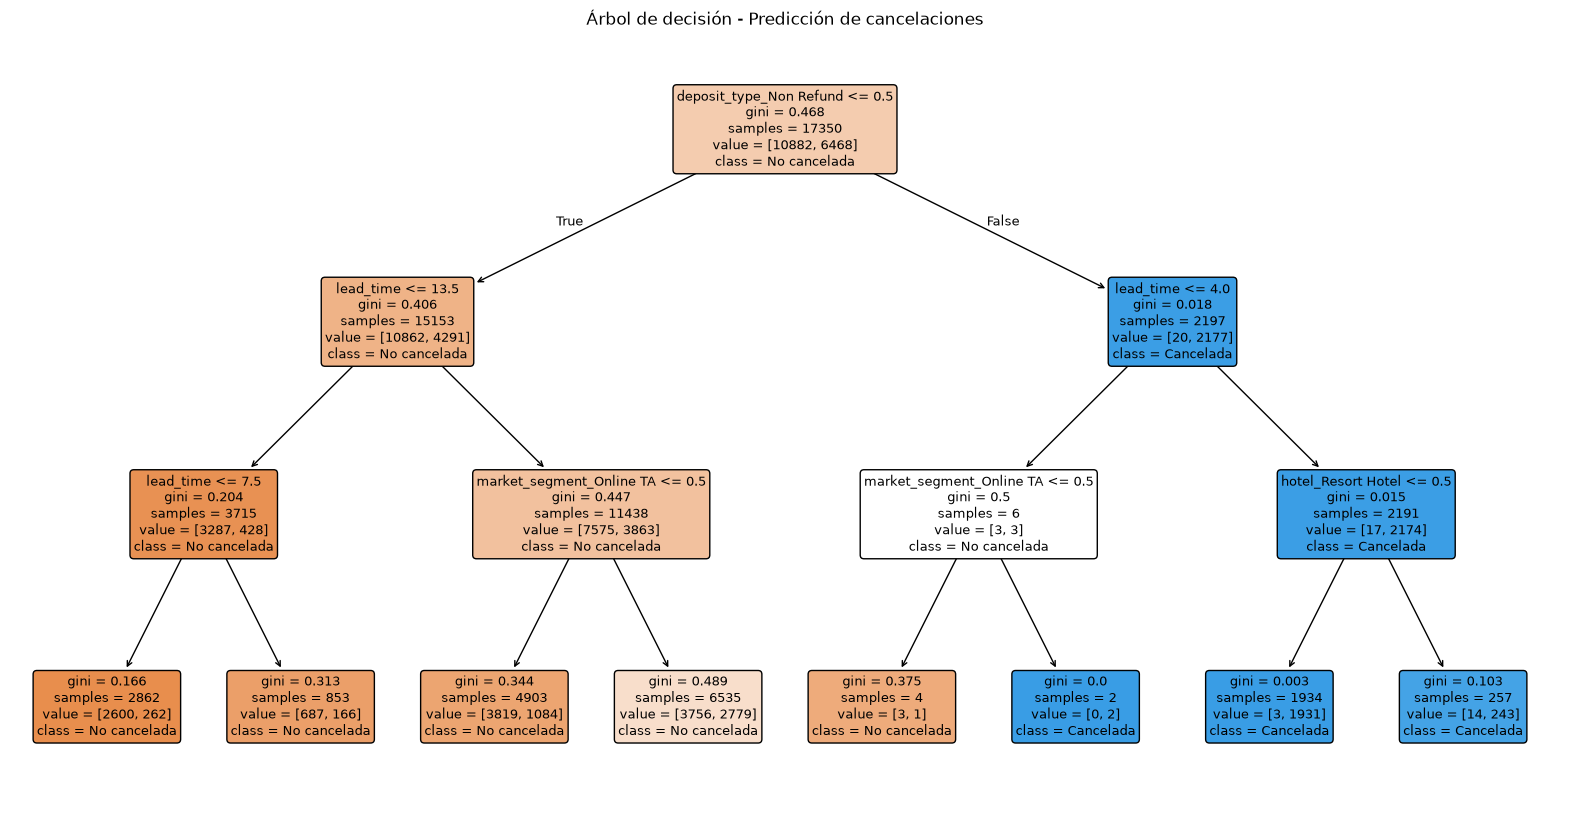

In [176]:

plt.figure(figsize=(20, 10))

plot_tree(
    modelo,
    feature_names=X_train.columns,
    class_names=["No cancelada", "Cancelada"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Árbol de decisión - Predicción de cancelaciones")
plt.show()

### Que hace el arbol de decisión

El árbol de decisión realiza la clasificación mediante una serie de preguntas sobre las variables predictoras. El recorrido comienza en el nodo superior y, según se cumpla o no cada condición, continúa por una de las ramas hasta llegar a una hoja, donde se obtiene la clasificación final como reserva cancelada o no cancelada.

En cada nodo, `samples` indica la cantidad de registros que llegaron hasta ese punto, `value` muestra cuántos pertenecen a cada clase y `class` indica la clase que el modelo asignaría en ese nodo.

Por ejemplo, la primera decisión del árbol utiliza el tipo de depósito (`deposit_type_Non Refund`). A partir de allí, el modelo continúa evaluando otras variables, como `lead_time`, `market_segment` y `hotel`, hasta determinar la clasificación correspondiente.

La profundidad máxima de 3 permite mantener un árbol relativamente sencillo y facilita la interpretación de las reglas utilizadas para realizar las predicciones.



## 4. Generación e inspección de predicciones

Una vez entrenado el árbol de decisión, se aplica el modelo sobre el conjunto de prueba para obtener una predicción para cada reserva.

Estas predicciones se comparan con los valores reales de `is_canceled`, permitiendo observar casos en los que el modelo coincide con el resultado real y casos en los que se equivoca.

También se obtiene la probabilidad estimada de cancelación para complementar la interpretación de la clase predicha.

In [177]:
# Generar predicciones sobre el conjunto de prueba
y_pred = modelo.predict(X_test)

# Probabilidad estimada de cancelación (clase 1)
probabilidad_cancelacion = modelo.predict_proba(X_test)[:, 1]

# Crear tabla para comparar resultados
resultados = pd.DataFrame({
    "resultado_real": y_test.to_numpy(),
    "prediccion": y_pred,
    "probabilidad_cancelacion": probabilidad_cancelacion.round(3)
})

# Indicar si la predicción coincide con el valor real
resultados["coincide"] = (
    resultados["resultado_real"] == resultados["prediccion"]
)

display(resultados.head(20))

,resultado_real,prediccion,probabilidad_cancelacion,coincide
0,0,0,0.221,True
1,0,0,0.195,True
2,1,0,0.195,False
3,1,0,0.221,False
4,0,0,0.425,True
5,0,0,0.221,True
6,0,0,0.221,True
7,0,0,0.221,True
8,0,0,0.221,True
9,0,0,0.425,True


### Inspección de las primeras predicciones

Al observar las primeras 20 reservas del conjunto de prueba, se identifican los ciertos y errores del modelo. En 15 casos la predicción coincide con el resultado real, mientras que en 5 casos existe una diferencia.

En esta muestra se observan 6 reservas que realmente fueron canceladas. El modelo clasificó correctamente una de ellas como cancelada, con una probabilidad estimada de cancelación de 0,998. Sin embargo, las cinco restantes fueron clasificadas como no canceladas.

Aunque varias reservas fueron clasificadas como no canceladas, el modelo les asignó diferentes probabilidades de cancelación.

Esta observación se realiza únicamente sobre los primeros 20 casos de prueba, por lo que no permite evaluar el rendimiento general del modelo.

---


## 5. Interpretación de los resultados

En las primeras 20 predicciones del conjunto de prueba se observan 15 casos en los que la clasificación realizada por el modelo coincide con el resultado real y 5 casos en los que no coincide.

Se puede ver 6 reservas que realmente fueron canceladas. El modelo identificó correctamente una de ellas como cancelada, mientras que las otras cinco fueron clasificadas como no canceladas. También se observan diferencias en las probabilidades estimadas, varias reservas fueron clasificadas como no canceladas con probabilidades de cancelación de 0,092, 0,195, 0,221 o 0,425, mientras que la reserva clasificada como cancelada presentó una probabilidad de 0,998.

***Que quieren decir estas probabilidades:***

- **0,092** = **9,2 % de probabilidad de cancelación**.
- **0,195** = **19,5 % de probabilidad de cancelación**.
- **0,221** = **22,1 % de probabilidad de cancelación**.
- **0,425** = **42,5 % de probabilidad de cancelación**.
- **0,998** = **99,8 % de probabilidad de cancelación**.

Por lo tanto, aunque varias reservas tengan como resultado final **"no cancelada"**, el modelo puede estimar distintos niveles de probabilidad de cancelación para cada una.

Estas primeras observaciones muestran que la predicción del modelo no debe interpretarse como una certeza. Una misma clase predicha puede estar asociada a diferentes probabilidades y el modelo también puede cometer errores.

### Utilidad de las predicciones

Las predicciones podrían utilizarse como información de apoyo para identificar reservas con mayor riesgo estimado de cancelación. Esto podría ayudar al hotel a priorizar el seguimiento de determinadas reservas y mejorar la planificación operativa.

Sin embargo, la predicción debería utilizarse como un elemento de apoyo y no como una decisión automática.

### Limitaciones

1. **Errores de clasificación:** el modelo puede clasificar incorrectamente una reserva. En los primeros casos inspeccionados se observan reservas que realmente fueron canceladas pero que el modelo clasificó como no canceladas.Este tipo de error podría impedir que el hotel identifique anticipadamente una cancelación.

2. **Dependencia de los datos históricos:** el modelo aprende patrones presentes en los datos utilizados para entrenarlo. Si cambian las características de las reservas, las políticas del hotel o el comportamiento de los clientes, esos patrones podrían no servir en el futuro.

3. **Modelo inicial y simplificado:** se utilizó un árbol limitado a una profundidad máxima de tres niveles y solamente seis variables predictoras. Pueden existir otros factores relevantes que el modelo no esté considerando.

Las relaciones aprendidas por el árbol permiten realizar predicciones, pero no implican que las variables utilizadas sean causas directas de una cancelación.

Este primer árbol de decisión permite explorar la posibilidad de anticipar cancelaciones mediante información disponible al momento de registrar una reserva. Los resultados obtenidos son útiles como una primera aproximación, pero deben interpretarse con cautela y requieren una evaluación más completa antes de considerar su utilización para la toma de decisiones.

---
---
---

# Trabajo Práctico Integrador - Introducción al Análisis de Datos - Semana 13
## Entrega 6 - Evaluación del modelo de clasificación

**Caso:** Predicción de cancelaciones en reservas hoteleras.

### Predicciones sobre el conjunto de prueba

Una vez entrenado el modelo, se generan las predicciones sobre el conjunto de
prueba. Estas predicciones se compararán con los valores reales de `is_canceled`
para evaluar los aciertos y errores del modelo.

In [178]:
y_pred = modelo.predict(X_test)

**Generación de predicciones**

Una vez entrenado el modelo, se utiliza el conjunto de prueba (`X_test`) para generar las predicciones.

El resultado se almacena en `y_pred`, donde cada valor indica la clase predicha por el modelo para una reserva: `0` para no cancelada y `1` para cancelada.

Estas predicciones se compararán luego con los valores reales (`y_test`) para evaluar el desempeño del modelo.

---

## 4. Matriz de confusión

Para evaluar los aciertos y errores del modelo sobre el conjunto de prueba, se construye una matriz de confusión comparando los valores reales de `is_canceled` con las predicciones realizadas por el modelo.

En este problema se considera como clase positiva la cancelación de una reserva (`is_canceled = 1`) y como clase negativa una reserva no cancelada (`is_canceled = 0`).

La matriz permitirá identificar los verdaderos positivos (TP), verdaderos negativos (TN), falsos positivos (FP) y falsos negativos (FN).

In [179]:
matriz_confusion = confusion_matrix(y_test, y_pred)

print(matriz_confusion)

[[4662    2]
 [1840  933]]


In [180]:
tn, fp, fn, tp = matriz_confusion.ravel()

print("Verdaderos negativos (TN):", tn)
print("Falsos positivos (FP):", fp)
print("Falsos negativos (FN):", fn)
print("Verdaderos positivos (TP):", tp)

Verdaderos negativos (TN): 4662
Falsos positivos (FP): 2
Falsos negativos (FN): 1840
Verdaderos positivos (TP): 933


---

### Interpretación de la matriz de confusión

Considerando la cancelación de una reserva como la clase positiva:

- **Verdaderos negativos (TN):** 4662 reservas no se cancelaron y el modelo las clasificó correctamente como no canceladas.
- **Falsos positivos (FP):** 2 reservas fueron clasificadas como canceladas, aunque finalmente no se cancelaron.
- **Falsos negativos (FN):** 1840 reservas se cancelaron, pero el modelo las clasificó como no canceladas.
- **Verdaderos positivos (TP):** 933 reservas se cancelaron y el modelo las clasificó correctamente como canceladas.

La matriz permite observar que el modelo tiene una cantidad considerable de falsos negativos, es decir, cancelaciones reales que no fueron anticipadas por el modelo. Este tipo de error será especialmente importante al interpretar las métricas de clasificación.

---

## 5. Métricas de clasificación

A partir de las predicciones realizadas sobre el conjunto de prueba, se calculan
distintas métricas para evaluar el desempeño del modelo.

En este análisis se considera la cancelación (`is_canceled = 1`) como la clase
positiva. Se utilizarán las siguientes métricas:

- **Accuracy:** indica qué proporción del total de reservas fue clasificada correctamente.
- **Precision:** indica de las reservas que el modelo predijo como canceladas qué proporción realmente se canceló.
- **Recall:** indica de todas las cancelaciones reales qué proporción logró detectar el modelo.
- **F1-score:** combina precision y recall en una única métrica, permitiendo analizar el equilibrio entre ambas.

Estas métricas permiten complementar la información obtenida mediante la matriz
de confusión y comprender mejor el comportamiento del modelo.

In [181]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy:  {accuracy:.3f} ({accuracy * 100:.1f}%)")
print(f"Precision: {precision:.3f} ({precision * 100:.1f}%)")
print(f"Recall:    {recall:.3f} ({recall * 100:.1f}%)")
print(f"F1-score:  {f1:.3f} ({f1 * 100:.1f}%)")

Accuracy:  0.752 (75.2%)
Precision: 0.998 (99.8%)
Recall:    0.336 (33.6%)
F1-score:  0.503 (50.3%)


### Interpretación de las métricas

- **Accuracy = 75,2 %:** el modelo clasificó correctamente aproximadamente el 75,2 % del total de reservas del conjunto de prueba.

- **Precision = 99,8 %:** cuando el modelo predice que una reserva se cancelará, acierta aproximadamente el 99,8 % de las veces. Esto es consistente con la muy baja cantidad de falsos positivos observada.

- **Recall = 33,6 %:** de todas las reservas que realmente se cancelaron, el modelo logró detectar aproximadamente el 33,6 %. Esto indica que una parte importante de las cancelaciones reales no fue anticipada por el modelo.

- **F1-score = 50,3 %:** al combinar precision y recall, esta métrica refleja el desequilibrio existente entre la alta precisión del modelo y su menor capacidad para detectar todas las cancelaciones reales.
  
---

## 6. Interpretación de los errores

En este problema, un **falso positivo (FP)** ocurre cuando el modelo predice que una reserva se cancelará, pero finalmente la reserva se mantiene. En el conjunto de prueba se observaron solamente 2 casos de este tipo.

Un **falso negativo (FN)** ocurre cuando el modelo predice que una reserva no se cancelará, pero finalmente sí se cancela. En este caso se observaron 1840 falsos negativos.

Para la gestión hotelera se deben considerar relevantes los falsos negativos, ya que representan cancelaciones que el modelo no logró anticipar. Esto podría limitar la utilidad del modelo para tomar medidas preventivas frente a posibles cancelaciones.

La cantidad de falsos negativos también es consistente con el recall obtenido (33,6 %), que muestra que el modelo detecta aproximadamente una tercera parte de las cancelaciones reales.

---


## 7. Conclusión

El modelo aporta información útil para anticipar cancelaciones, aunque presenta
limitaciones importantes que deben considerarse antes de utilizar sus predicciones
para tomar decisiones.

El modelo alcanzó un accuracy del 75,2 % y una precision del 99,8 %, lo que indica
que, cuando predice una cancelación, esa predicción resulta muy confiable. Sin
embargo, el recall obtenido fue del 33,6 %, por lo que el modelo logra detectar
solo una parte de las cancelaciones que realmente ocurren. Esto también se refleja
en la cantidad de falsos negativos observados.

Por lo tanto, el modelo puede ser útil como una primera herramienta de apoyo,
pero no debería utilizarse como único criterio para tomar decisiones sobre las
reservas. Su principal limitación es la dificultad para detectar una proporción
importante de las cancelaciones reales.